
================ RAW FILE DISCOVERY ================
model                  policy                target_case  n_files
   rf              DPP-TS-QBC electric_cond_seebeck_coef       10
   rf              DPP-TS-QBC electric_cond_thermal_cond       10
   rf              DPP-TS-QBC           electric_cond_zT       10
   rf                      HV electric_cond_seebeck_coef        5
   rf                      HV electric_cond_thermal_cond        5
   rf                      HV           electric_cond_zT        5
   rf          HV + k-medoids electric_cond_seebeck_coef       10
   rf          HV + k-medoids electric_cond_thermal_cond       10
   rf          HV + k-medoids           electric_cond_zT       10
   rf             NSGA-II QBC electric_cond_seebeck_coef       10
   rf             NSGA-II QBC electric_cond_thermal_cond       10
   rf             NSGA-II QBC           electric_cond_zT       10
   rf NSGA-II QBC + diversity electric_cond_seebeck_coef        5
   rf NSGA-II QBC + di

C:\Users\rafae\AppData\Local\Temp\ipykernel_31728\962741033.py:463: UserWarning: 

The `scale` parameter is deprecated and will be removed in v0.15.0. You can now control the size of each plot element using matplotlib `Line2D` parameters (e.g., `linewidth`, `markersize`, etc.).

  sns.pointplot(
C:\Users\rafae\AppData\Local\Temp\ipykernel_31728\962741033.py:463: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  sns.pointplot(
C:\Users\rafae\AppData\Local\Temp\ipykernel_31728\962741033.py:463: UserWarning: 

The `scale` parameter is deprecated and will be removed in v0.15.0. You can now control the size of each plot element using matplotlib `Line2D` parameters (e.g., `linewidth`, `markersize`, etc.).

  sns.pointplot(
C:\Users\rafae\AppData\Local\Temp\ipykernel_31728\962741033.py:463: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line 

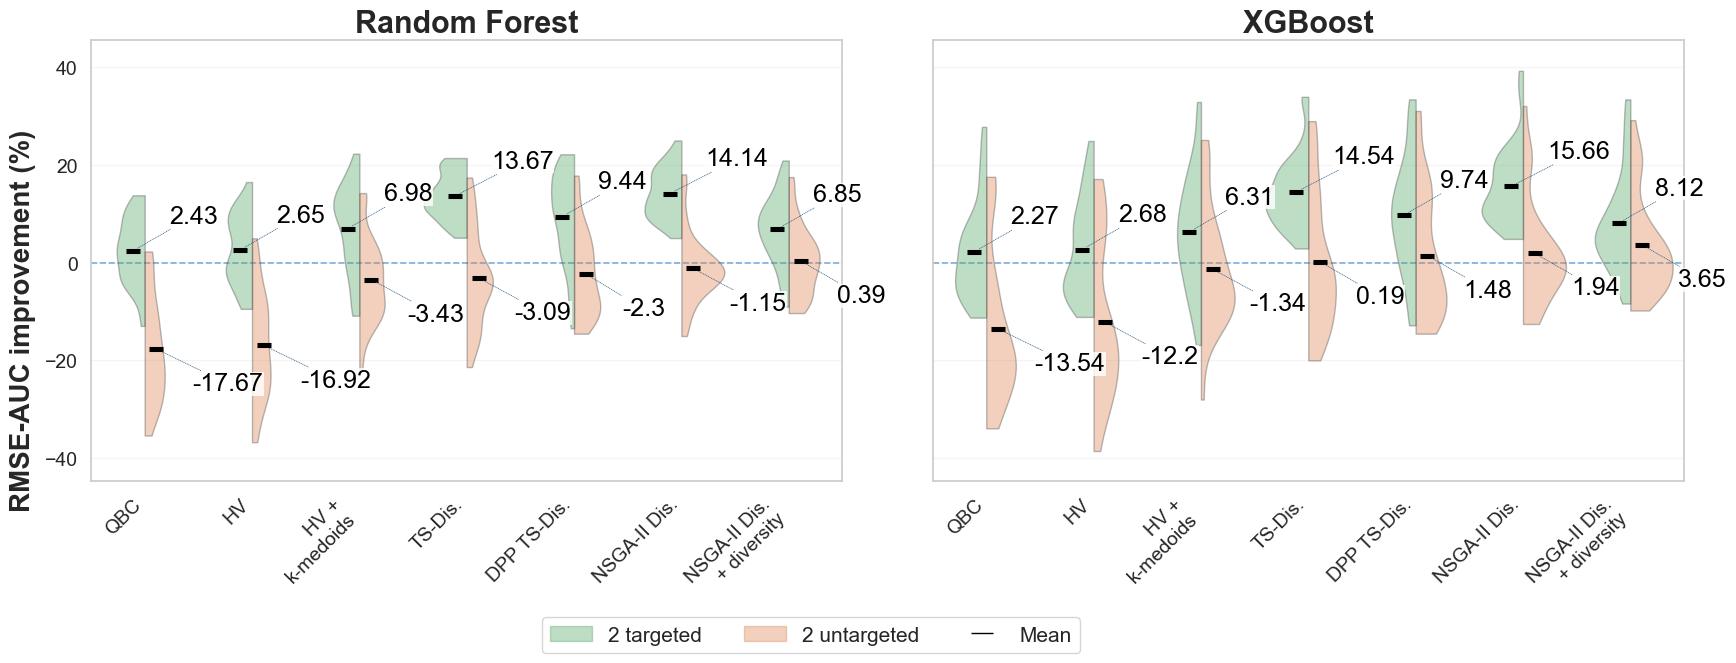


Saved figure:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\ThermoElectricNew3\WITH_MODIFICATIONS\plots\2Targets_RF_XGB_Raw_Violin_Distributions\2targets_2untargeted_RF_XGB_raw_violin.png

Saved raw plotting data:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\ThermoElectricNew3\WITH_MODIFICATIONS\plots\2Targets_RF_XGB_Raw_Violin_Distributions\2targets_2untargeted_RF_XGB_raw_plot_data.csv

Saved mean data:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\ThermoElectricNew3\WITH_MODIFICATIONS\plots\2Targets_RF_XGB_Raw_Violin_Distributions\2targets_2untargeted_RF_XGB_raw_means.csv

Saved discovered raw-file index:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\ThermoElectricNew3\WITH_MODIFICATIONS\plots\2Targets_RF_XGB_Raw_Violin_Di

In [13]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
# Configuration
BASE_ROOT = Path(
    r"C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES"
    r"\PhD Toronto\DatasetGeneration\Better_Acqsition\ThermoElectricNew3"
    r"\WITH_MODIFICATIONS"
)
RAW_ROOT = BASE_ROOT
DATA_ROOT = BASE_ROOT / "al"
PLOTS_ROOT = BASE_ROOT / "plots"
OUTPUT_ROOT = PLOTS_ROOT / "2Targets_RF_XGB_Raw_Violin_Distributions"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
OUTPUT_FIGURE = OUTPUT_ROOT / "2targets_2untargeted_RF_XGB_raw_violin.png"
OUTPUT_PLOT_DATA = OUTPUT_ROOT / "2targets_2untargeted_RF_XGB_raw_plot_data.csv"
OUTPUT_MEAN_DATA = OUTPUT_ROOT / "2targets_2untargeted_RF_XGB_raw_means.csv"
OUTPUT_DISCOVERED = OUTPUT_ROOT / "2targets_2untargeted_RF_XGB_discovered_raw_files.csv"
MODELS = {"rf": "Random Forest", "xgb": "XGBoost"}
MODEL_ORDER = ["rf", "xgb"]
SEEDS = range(5)
# Properties
PROPERTIES = ["electric_cond", "thermal_cond", "seebeck_coef", "zT"]
PROPERTY_LABELS = {
    "electric_cond": "Electrical conductivity",
    "thermal_cond": "Thermal conductivity",
    "seebeck_coef": "Seebeck coefficient",
    "zT": "Figure of merit (zT)",
}
RMSE_METRIC_ALIASES = {
    "electric_cond": [
        "rmse_elec_cond",
        "rmse_electric_cond",
        "rmse_electrical_conductivity",
        "rmse_electric_conductivity",
        "rmse_el",
        "rmse_elec",
    ],
    "thermal_cond": [
        "rmse_k_total",
        "rmse_thermal_cond",
        "rmse_thermal_conductivity",
        "rmse_thc",
        "rmse_thermal",
    ],
    "seebeck_coef": [
        "rmse_seebeck",
        "rmse_seebeck_coef",
        "rmse_seebeck_coefficient",
        "rmse_seeb",
    ],
    "zT": [
        "rmse_zt",
        "rmse_zT",
        "rmse_ZT",
        "rmse_figure_of_merit",
    ],
}
TWO_TARGET_CASES = {
    "electric_cond_thermal_cond": {"electric_cond", "thermal_cond"},
    "electric_cond_seebeck_coef": {"electric_cond", "seebeck_coef"},
    "electric_cond_zT": {"electric_cond", "zT"},
    "thermal_cond_seebeck_coef": {"thermal_cond", "seebeck_coef"},
    "thermal_cond_zT": {"thermal_cond", "zT"},
    "seebeck_coef_zT": {"seebeck_coef", "zT"},
}
# Policies and displayed labels
POLICY_ORDER = [
    "QBC",
    "HV",
    "HV + k-medoids",
    "TS-QBC",
    "DPP-TS-QBC",
    "NSGA-II QBC",
    "NSGA-II QBC + diversity",
]
DISPLAY_POLICY_LABELS = {
    "QBC": "QBC",
    "HV": "HV",
    "HV + k-medoids": "HV +\nk-medoids",
    "TS-QBC": "TS-Dis.",
    "DPP-TS-QBC": "DPP TS-Dis.",
    "NSGA-II QBC": "NSGA-II Dis.",
    "NSGA-II QBC + diversity": "NSGA-II Dis.\n+ diversity",
}
CASE_ORDER = ["2 targeted", "2 untargeted"]
CASE_COLORS = {
    "2 targeted": "#55a868",
    "2 untargeted": "#dd8452",
}
# General helpers
def _norm(value):
    return re.sub(r"[^a-z0-9]", "", str(value).lower())
def identify_seed_and_model(path):
    path = Path(path)
    match = re.search(
        r"(?:_|-|\s)(rf|xgb)(\d*)\.csv$",
        path.name,
        flags=re.IGNORECASE,
    )
    if not match:
        return None, None
    model = match.group(1).lower()
    digits = match.group(2)
    if digits:
        return model, int(digits)
    for parent in path.parents:
        if parent.name.isdigit():
            return model, int(parent.name)
    return model, None
def property_tokens(property_id):
    aliases = {
        "electric_cond": [
            "electriccond",
            "electricalconductivity",
            "electricconductivity",
            "electric",
            "elec",
        ],
        "thermal_cond": [
            "thermalcond",
            "thermalconductivity",
            "thermal",
            "thc",
        ],
        "seebeck_coef": [
            "seebeckcoef",
            "seebeckcoefficient",
            "seebeck",
            "seeb",
        ],
        "zT": ["zt", "figureofmerit"],
    }
    return aliases[property_id]
def identify_target_case(text):
    compact = _norm(text)
    present = []
    for prop in PROPERTIES:
        aliases = sorted(property_tokens(prop), key=len, reverse=True)
        if any(_norm(alias) in compact for alias in aliases):
            present.append(prop)
    if len(present) != 2:
        return None
    target_set = set(present)
    for case_name, case_properties in TWO_TARGET_CASES.items():
        if target_set == case_properties:
            return case_name
    return None
def resolve_metric_column(df, property_id):
    for column in RMSE_METRIC_ALIASES[property_id]:
        if column in df.columns:
            return column
    normalized_columns = {_norm(c): c for c in df.columns}
    for column in RMSE_METRIC_ALIASES[property_id]:
        key = _norm(column)
        if key in normalized_columns:
            return normalized_columns[key]
    return None
# Detect policies from raw paths
def detect_raw_policy(path):
    path = Path(path)
    full = _norm(str(path)).replace("growingea", "growea")
    name = _norm(path.name)
    stem = _norm(path.stem)
    if "random" in full:
        return "Random"
    if (
        "growdisagreementhvtopmkmedoidstwotargets" in full
        or "growdisagreementhvtopmkmedoids" in full
        or "hvkmedoids" in full
    ):
        return "HV + k-medoids"
    if (
        "growdisagreementhvtwotargets" in full
        or "growdisagreementhvnodiversitytwotargets" in full
        or ("growdisagreementhv" in full and "kmedoids" not in full)
    ):
        return "HV"
    if "dpptsqbc" in full or "growdpptsqbc" in full:
        return "DPP-TS-QBC"
    if (
        ("tsqbc" in full and "dpptsqbc" not in full and "growea" not in full)
        or "growtsqbc" in full
    ):
        return "TS-QBC"
    if (
        ("nsgaii" in full and "divers" in full)
        or "groweadeltadiversity" in full
        or ("growea" in full and "withdiversity" in full)
        or ("growea" in full and "divers" in full)
    ):
        return "NSGA-II QBC + diversity"
    if (
        ("nsgaii" in full and "divers" not in full)
        or (
            "growea" in full
            and "withdiversity" not in full
            and "divers" not in full
        )
        or stem.startswith("growea")
        or name.startswith("growea")
    ):
        return "NSGA-II QBC"
    qbc_exclusions = ("tsqbc", "dpptsqbc", "nsgaii", "growea")
    if not any(token in full for token in qbc_exclusions):
        if (
            "grow2qbc" in full
            or "growing2qbc" in full
            or "2qbc" in full
        ):
            return "QBC"
        if any(_norm(part) == "qbc" for part in path.parts):
            return "QBC"
        if re.search(
            r"(?:^|[_\-])qbc[_\-](?:rf|xgb)\d*\.csv$",
            path.name,
            flags=re.IGNORECASE,
        ):
            return "QBC"
    return None
# RMSE-AUC calculation
def load_curve(path):
    try:
        df = pd.read_csv(path)
    except Exception as exc:
        print(f"Could not read {path}: {exc}")
        return None
    train_column = None
    for candidate in [
        "train_ratio",
        "train_fraction",
        "training_ratio",
        "fraction_train",
    ]:
        if candidate in df.columns:
            train_column = candidate
            break
    if train_column is None:
        return None
    df = df.copy()
    df["train_percent"] = 100.0 * pd.to_numeric(
        df[train_column], errors="coerce"
    )
    return df
def normalized_rmse_auc_for_property(df, property_id):
    if df is None:
        return None
    metric_col = resolve_metric_column(df, property_id)
    if metric_col is None:
        return None
    curve = (
        df[["train_percent", metric_col]]
        .apply(pd.to_numeric, errors="coerce")
        .dropna()
        .groupby("train_percent", as_index=False)[metric_col]
        .mean()
        .sort_values("train_percent")
    )
    if len(curve) < 2:
        return None
    x = curve["train_percent"].to_numpy(dtype=float)
    y = curve[metric_col].to_numpy(dtype=float)
    width = x[-1] - x[0]
    if width <= 0:
        return None
    if hasattr(np, "trapezoid"):
        auc = np.trapezoid(y, x)
    else:
        auc = np.trapz(y, x)
    return float(auc / width)
# Discover raw two-target files
def discover_raw_files():
    if not RAW_ROOT.exists():
        raise FileNotFoundError(f"Raw search root does not exist:\n{RAW_ROOT}")
    rows = []
    for path in RAW_ROOT.rglob("*.csv"):
        if OUTPUT_ROOT in path.parents:
            continue
        model, seed = identify_seed_and_model(path)
        if model not in MODELS or seed not in SEEDS:
            continue
        policy = detect_raw_policy(path)
        if policy is None or policy == "Random":
            continue
        target_case = identify_target_case(str(path))
        if target_case not in TWO_TARGET_CASES:
            continue
        rows.append({
            "model": model,
            "seed": seed,
            "policy": policy,
            "target_case": target_case,
            "path": str(path),
        })
    raw_index = pd.DataFrame(rows)
    if raw_index.empty:
        raise ValueError(
            "No raw sysTEM AL files were discovered. "
            "Check RAW_ROOT and the raw file naming patterns."
        )
    raw_index.to_csv(OUTPUT_DISCOVERED, index=False)
    print("\n================ RAW FILE DISCOVERY ================")
    diagnostic = (
        raw_index
        .groupby(["model", "policy", "target_case"], as_index=False)
        .size()
        .rename(columns={"size": "n_files"})
    )
    print(diagnostic.to_string(index=False))
    return raw_index
def random_path(model, seed):
    return (
        DATA_ROOT
        / "grow_random"
        / "ThermoEl"
        / "all"
        / str(seed)
        / f"ThermoEl_all_random_{model}{seed}.csv"
    )
# Build distributions from raw trajectories
def build_distribution_dataframe():
    raw_index = discover_raw_files()
    policy_index = raw_index.loc[
        raw_index["policy"].isin(POLICY_ORDER)
    ].copy()
    if policy_index.empty:
        raise ValueError(
            "No raw 2-target acquisition-policy files were discovered."
        )
    policy_index = (
        policy_index
        .sort_values("path")
        .drop_duplicates(
            subset=["model", "seed", "policy", "target_case"],
            keep="first",
        )
    )
    rows = []
    for run in policy_index.itertuples(index=False):
        rand_path = random_path(run.model, run.seed)
        if not rand_path.exists():
            print(
                "Missing canonical Random baseline: "
                f"model={run.model}, seed={run.seed}, "
                f"expected_path={rand_path}"
            )
            continue
        policy_df = load_curve(Path(run.path))
        random_df = load_curve(rand_path)
        if policy_df is None or random_df is None:
            continue
        targeted_properties = TWO_TARGET_CASES[run.target_case]
        for property_id in PROPERTIES:
            policy_auc = normalized_rmse_auc_for_property(
                policy_df, property_id
            )
            random_auc = normalized_rmse_auc_for_property(
                random_df, property_id
            )
            if policy_auc is None or random_auc is None:
                continue
            if random_auc == 0:
                continue
            improvement_percent = 100.0 * (1.0 - policy_auc / random_auc)
            is_targeted = property_id in targeted_properties
            rows.append({
                "model": run.model,
                "model_display": MODELS[run.model],
                "seed": run.seed,
                "policy": run.policy,
                "target_case": run.target_case,
                "property_id": property_id,
                "property_name": PROPERTY_LABELS[property_id],
                "case_type": "targeted" if is_targeted else "untargeted",
                "axis": "2 targeted" if is_targeted else "2 untargeted",
                "policy_mean_rmse_auc": policy_auc,
                "random_mean_rmse_auc": random_auc,
                "case_improvement_percent": improvement_percent,
                "policy_file": run.path,
                "random_file": str(rand_path),
            })
    distribution_df = pd.DataFrame(rows)
    if distribution_df.empty:
        raise ValueError(
            "No RMSE-AUC improvement values could be calculated from the raw files."
        )
    distribution_df.to_csv(OUTPUT_PLOT_DATA, index=False)
    stats_df = (
        distribution_df
        .groupby(["model", "policy", "axis"], as_index=False)[
            "case_improvement_percent"
        ]
        .mean()
        .rename(columns={
            "case_improvement_percent": "mean_case_improvement_percent"
        })
    )
    stats_df.to_csv(OUTPUT_MEAN_DATA, index=False)
    print("\n================ FINAL DISTRIBUTION COUNTS ================")
    counts = (
        distribution_df
        .groupby(["model", "policy", "axis"], as_index=False)
        .size()
        .rename(columns={"size": "n_values"})
    )
    print(counts.to_string(index=False))
    return distribution_df
# Plot Random Forest on the left and XGBoost on the right
def make_figure(distribution_df):
    all_values = pd.to_numeric(
        distribution_df["case_improvement_percent"], errors="coerce"
    ).to_numpy(dtype=float)
    all_values = all_values[np.isfinite(all_values)]
    if len(all_values) == 0:
        raise ValueError("No finite improvement values are available for plotting.")
    value_min = min(float(all_values.min()), 0.0)
    value_max = max(float(all_values.max()), 0.0)
    span = max(value_max - value_min, 1.0)
    padding = max(1.0, 0.08 * span)
    y_lim = (value_min - padding, value_max + padding)
    sns.set_theme(style="whitegrid")
    fig, axes = plt.subplots(
        nrows=1,
        ncols=2,
        figsize=(18, 7),
        sharey=True,
    )
    for column_index, model in enumerate(MODEL_ORDER):
        ax = axes[column_index]
        panel_df = distribution_df.loc[
            (distribution_df["model"] == model)
            & (distribution_df["policy"].isin(POLICY_ORDER))
        ].copy()
        if not panel_df.empty:
            sns.violinplot(
                data=panel_df,
                x="policy",
                y="case_improvement_percent",
                hue="axis",
                order=POLICY_ORDER,
                hue_order=CASE_ORDER,
                palette={
                    case_name: CASE_COLORS[case_name]
                    for case_name in CASE_ORDER
                },
                split=True,
                inner=None,
                cut=0,
                bw_adjust=0.8,
                gridsize=250,
                linewidth=1.0,
                saturation=1.0,
                ax=ax,
            )
            for collection in ax.collections:
                collection.set_alpha(0.38)
            # Black mean markers
            sns.pointplot(
                data=panel_df,
                x="policy",
                y="case_improvement_percent",
                hue="axis",
                order=POLICY_ORDER,
                hue_order=CASE_ORDER,
                estimator=np.mean,
                errorbar=None,
                join=False,
                dodge=0.22,
                markers="_",
                linestyles="none",
                palette={case_name: "black" for case_name in CASE_ORDER},
                scale=1.8,
                ax=ax,
                legend=False,
                zorder=6,
            )
            # Mean values with dotted leader lines, matching the last cell
            for hue_index, case_name in enumerate(CASE_ORDER):
                means = (
                    panel_df.loc[panel_df["axis"] == case_name]
                    .groupby("policy", observed=True)["case_improvement_percent"]
                    .mean()
                )
                offset = -0.11 if hue_index == 0 else 0.11
                vertical_offset = 25 if hue_index == 0 else -25
                for i, policy in enumerate(POLICY_ORDER):
                    if policy not in means.index or not np.isfinite(means[policy]):
                        continue
                    value = float(means[policy])
                    label = f"{value:.2f}".rstrip("0").rstrip(".")
                    ax.annotate(
                        label,
                        xy=(i + offset, value),
                        xytext=(26, vertical_offset),
                        textcoords="offset points",
                        ha="left",
                        va="center",
                        fontsize=18,
                        fontweight="normal",
                        color="black",
                        zorder=8,
                        arrowprops=dict(
                            arrowstyle="-",
                            color="#24527a",
                            linestyle=":",
                            linewidth=0.5,
                            shrinkA=2,
                            shrinkB=4,
                        ),
                        bbox=dict(
                            facecolor="white",
                            edgecolor="none",
                            alpha=0.82,
                            pad=0.4,
                        ),
                    )
        if ax.get_legend() is not None:
            ax.get_legend().remove()
        ax.axhline(
            0.0,
            linestyle="--",
            linewidth=1.2,
            color="#5b9bd5",
            alpha=0.85,
            zorder=0,
        )
        ax.set_ylim(*y_lim)
        ax.set_title(MODELS[model], fontsize=22, fontweight="bold")
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.grid(axis="y", alpha=0.20)
        ax.set_xticks(np.arange(len(POLICY_ORDER)))
        ax.set_xticklabels(
            [DISPLAY_POLICY_LABELS[p] for p in POLICY_ORDER],
            fontsize=14,
            rotation=45,
            ha="right",
        )
        ax.tick_params(axis="y", labelsize=14)
    legend_handles = [
        Patch(
            facecolor=CASE_COLORS["2 targeted"],
            edgecolor=CASE_COLORS["2 targeted"],
            alpha=0.38,
            label="2 targeted",
        ),
        Patch(
            facecolor=CASE_COLORS["2 untargeted"],
            edgecolor=CASE_COLORS["2 untargeted"],
            alpha=0.38,
            label="2 untargeted",
        ),
        Line2D(
            [0],
            [0],
            color="black",
            marker="_",
            markersize=16,
            linestyle="none",
            label="Mean",
        ),
    ]
    fig.legend(
        handles=legend_handles,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.01),
        ncol=3,
        fontsize=15,
        frameon=True,
        title=None,
    )
    fig.supylabel(
        "RMSE-AUC improvement (%)",
        fontsize=20,
        fontweight="bold",
        x=0.055,
    )
    plt.subplots_adjust(
        left=0.10,
        right=0.985,
        top=0.90,
        bottom=0.27,
        wspace=0.12,
    )
    fig.savefig(OUTPUT_FIGURE, dpi=250, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("\nSaved figure:")
    print(OUTPUT_FIGURE)
    print("\nSaved raw plotting data:")
    print(OUTPUT_PLOT_DATA)
    print("\nSaved mean data:")
    print(OUTPUT_MEAN_DATA)
    print("\nSaved discovered raw-file index:")
    print(OUTPUT_DISCOVERED)
def main():
    distribution_df = build_distribution_dataframe()
    make_figure(distribution_df)
if __name__ == "__main__":
    main()


========== RAW RANDOM FOREST VIOLIN OBSERVATIONS: 1 TARGET(S) ==========
         display_policy         axis  n_raw_observations
                    QBC   1 targeted                  20
                    QBC 3 untargeted                  60
         HV + k-medoids   1 targeted                  20
         HV + k-medoids 3 untargeted                  60
                 TS-QBC   1 targeted                  20
                 TS-QBC 3 untargeted                  60
             DPP-TS-QBC   1 targeted                  20
             DPP-TS-QBC 3 untargeted                  60
NSGA-II QBC + diversity   1 targeted                  20
NSGA-II QBC + diversity 3 untargeted                  60

Expected per policy when all files are present:
  1 targeted   = 20 observations
      4 campaigns x 1 targeted property x 5 seeds
  3 untargeted = 60 observations
      4 campaigns x 3 untargeted properties x 5 seeds

========== PROPERTY CONTRIBUTIONS TO VIOLINS ==========
         display_policy

C:\Users\rafae\AppData\Local\Temp\ipykernel_31728\1756471557.py:770: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.pointplot(
C:\Users\rafae\AppData\Local\Temp\ipykernel_31728\1756471557.py:770: UserWarning: 

The `scale` parameter is deprecated and will be removed in v0.15.0. You can now control the size of each plot element using matplotlib `Line2D` parameters (e.g., `linewidth`, `markersize`, etc.).

  sns.pointplot(
C:\Users\rafae\AppData\Local\Temp\ipykernel_31728\1756471557.py:770: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  sns.pointplot(
C:\Users\rafae\AppData\Local\Temp\ipykernel_31728\1756471557.py:792: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavi

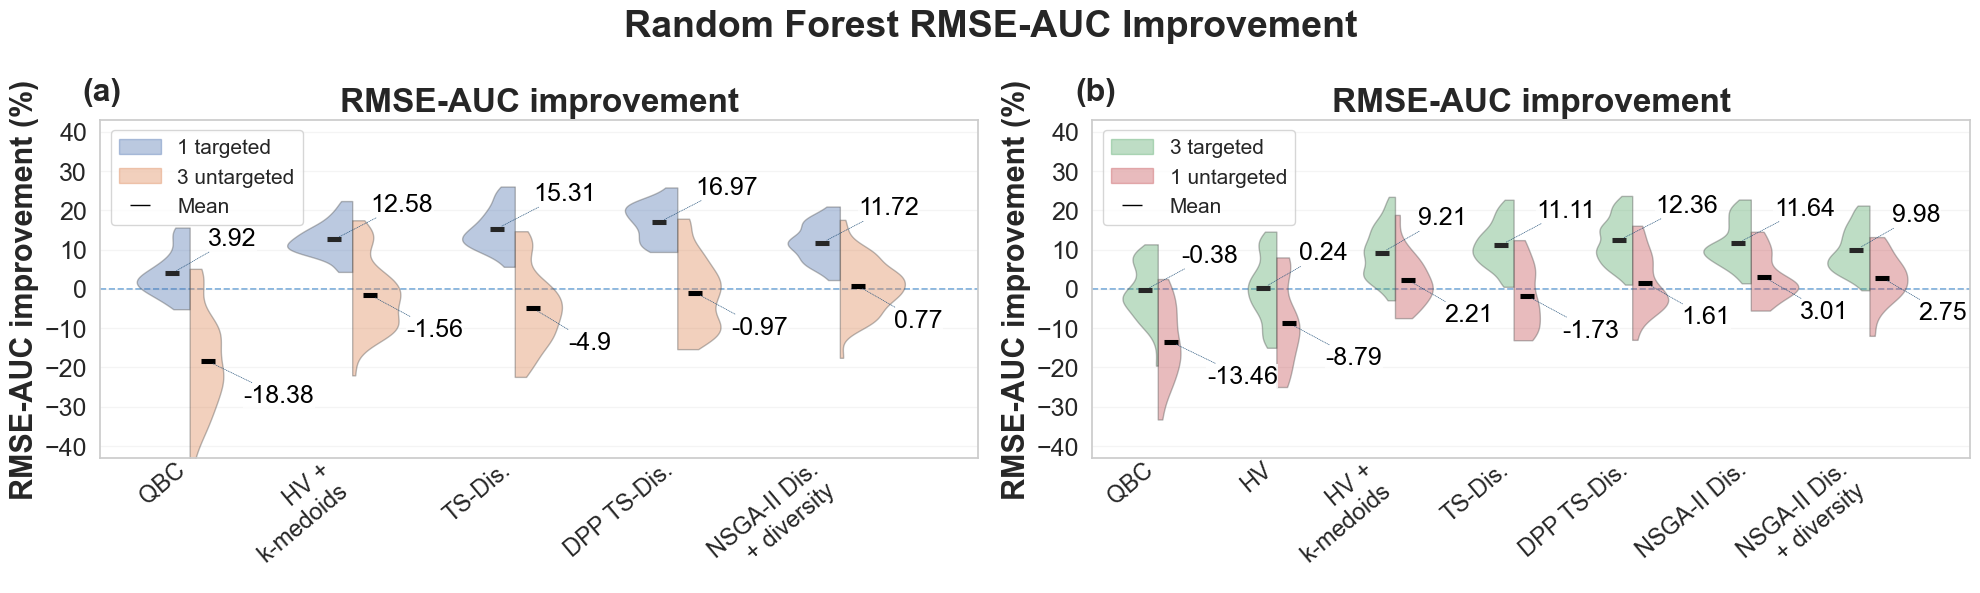

Saved: C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\ThermoElectricNew3\WITH_MODIFICATIONS\plots\Combined_1Target_3Target_RandomForest\RandomForest_1Target_3Target_violin_only.png
Saved one-target raw violin data: C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\ThermoElectricNew3\WITH_MODIFICATIONS\plots\Combined_1Target_3Target_RandomForest\RandomForest_1Target_violin_ALL_CASES_raw_observations.csv
Saved three-target raw violin data: C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\ThermoElectricNew3\WITH_MODIFICATIONS\plots\Combined_1Target_3Target_RandomForest\RandomForest_3Target_violin_ALL_CASES_raw_observations.csv


In [11]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from matplotlib.ticker import ScalarFormatter
from matplotlib.transforms import blended_transform_factory
# =============================================================================
# Configuration
# =============================================================================
BASE_ROOT = Path(
    r"C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES"
    r"\PhD Toronto\DatasetGeneration\Better_Acqsition\ThermoElectricNew3"
    r"\WITH_MODIFICATIONS"
)
DATA_ROOT = BASE_ROOT / "al"
PLOTS_ROOT = BASE_ROOT / "plots"
ANALYSIS_ROOT = BASE_ROOT / "analysis"
OUTPUT_ROOT = PLOTS_ROOT / "Combined_1Target_3Target_RandomForest"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
OUTPUT_FIGURE = OUTPUT_ROOT / "RandomForest_1Target_3Target_violin_only.png"
SEEDS = range(5)
MODEL = "rf"
# This is the campaign requested:
# targeted = Electrical conductivity + Seebeck coefficient + Thermal conductivity
# untargeted = Figure of merit zT
TARGET_FOLDER = "el_seeb_ThC"
TARGET_PREFIX = "ThermoEl_el_seeb_ThC"
# =============================================================================
# Policies for the RMSE curves
# =============================================================================
POLICIES = {
    "3QBC": (
        "grow_3QBC",
        "growing_3QBC",
    ),
    "HV": (
        "grow_disagreementHV_no_diversity_ThreeTargets",
        "growing_HV_nodiv_3targets",
    ),
    "HV + k-medoids": (
        "grow_disagreementHV_topM_kmedoids_ThreeTargets",
        "growing_3HV_k",
    ),
    "DPP-TS-QBC": (
        "grow_DPP_TS_QBC_ThreeTargets",
        "growing_DPP_TS_QBC_3targets",
    ),
    "NSGA-II QBC": (
        "grow_EA_3Obj_ThreeTargets_QBC_ONLY",
        "growing_EA_3obj_qbc_only",
    ),
    "NSGA-II QBC + diversity": (
        "grow_EA_4Obj_ThreeTargets",
        "growing_EA_3out_div",
    ),
    "TS-QBC": (
        "grow_TS_QBC_no_diversity_ThreeTargets",
        "growing_TS_nodiv_3targets",
    ),
    "MORBO-QBC + Vendi": (
        "grow_MORBO_QBC_vendi_TR_and_sample_diverse_ThreeTargets",
        "growing_MORBO_QBC_vendi_TR_sample_diverse_3targets",
    ),
    "Random": (
        "grow_random",
        "random",
    ),
}
FILLED_MARKER_POLICIES = {
    "HV + k-medoids",
    "DPP-TS-QBC",
    "NSGA-II QBC + diversity",
    "MORBO-QBC + Vendi",
}
POLICY_COLORS = {
    "3QBC": "tab:gray",
    "HV": "tab:orange",
    "HV + k-medoids": "tab:orange",
    "TS-QBC": "tab:green",
    "DPP-TS-QBC": "tab:green",
    "NSGA-II QBC": "tab:red",
    "NSGA-II QBC + diversity": "tab:red",
    "MORBO-QBC + Vendi": "tab:purple",
    "Random": "tab:blue",
}
POLICY_LINESTYLES = {
    "3QBC": "-",
    "HV": "-",
    "HV + k-medoids": "dotted",
    "TS-QBC": "-",
    "DPP-TS-QBC": "dotted",
    "NSGA-II QBC": "-",
    "NSGA-II QBC + diversity": "dotted",
    "MORBO-QBC + Vendi": "dotted",
    "Random": "-",
}
# =============================================================================
# Violin-plot configuration
# =============================================================================
#
# TOP-LEFT PANEL:
#   Aggregate ALL raw one-target campaigns into:
#       1 targeted   = 4 campaigns x 1 targeted property x 5 seeds = 20
#       3 untargeted = 4 campaigns x 3 untargeted properties x 5 seeds = 60
#   observations per policy when all files are present.
#
# TOP-RIGHT PANEL:
#   Aggregate ALL raw three-target campaigns into:
#       3 targeted   = 4 campaigns x 3 targeted properties x 5 seeds = 60
#       1 untargeted = 4 campaigns x 1 untargeted property x 5 seeds = 20
#   observations per policy when all files are present.
#
# Each observation is calculated independently from the raw AL trajectory:
#
#   improvement_percent =
#       100 * (1 - policy_RMSE_AUC_seed / random_RMSE_AUC_seed)
#
# No averaging is done across seeds, properties, campaigns, or policies before
# sns.violinplot. Duplicate rows at exactly the same train_ratio are averaged
# only within one raw trajectory before integrating RMSE-AUC.
#
# IMPORTANT:
# The four RMSE panels still use only TARGET_FOLDER = "el_seeb_ThC".
# =============================================================================
POLICY_ORDER = [
    "QBC",
    "HV",
    "HV + k-medoids",
    "TS-QBC",
    "DPP-TS-QBC",
    "NSGA-II QBC",
    "NSGA-II QBC + diversity",
]
ONE_TARGET_VIOLIN_POLICY_ORDER = [p for p in POLICY_ORDER if p not in {"HV", "NSGA-II QBC"}]
THREE_TARGET_VIOLIN_POLICY_ORDER = POLICY_ORDER.copy()
DISPLAY_POLICY_LABELS = {
    "DPP-TS-QBC": "DPP TS-Dis.",
    "TS-QBC": "TS-Dis.",
    "NSGA-II QBC + diversity": "NSGA-II Dis.\n+ diversity",
    "NSGA-II QBC": "NSGA-II Dis.",
    "HV + k-medoids": "HV +\nk-medoids",
    "HV": "HV",
    "QBC": "QBC",
}
CASE_COLORS = {
    "1 targeted": "#4c72b0",
    "3 untargeted": "#dd8452",
    "3 targeted": "#55a868",
    "1 untargeted": "#c44e52",
}
# All 1-target campaign combinations used to build the aggregate violin.
VIOLIN_ONE_TARGET_SETS = {
    "electric_cond": {
        "prefix": "ThermoEl_electric_cond",
        "targeted": {"electric_cond"},
    },
    "seebeck_coef": {
        "prefix": "ThermoEl_seebeck_coef",
        "targeted": {"seebeck_coef"},
    },
    "zT": {
        "prefix": "ThermoEl_zT",
        "targeted": {"zT"},
    },
    "thermal_cond": {
        "prefix": "ThermoEl_thermal_cond",
        "targeted": {"thermal_cond"},
    },
}
# All 3-target campaign combinations used to build the aggregate violin.
VIOLIN_THREE_TARGET_SETS = {
    "el_seeb_zT": {
        "prefix": "ThermoEl_el_seeb_zT",
        "targeted": {"electric_cond", "seebeck_coef", "zT"},
    },
    "el_seeb_ThC": {
        "prefix": "ThermoEl_el_seeb_ThC",
        "targeted": {"electric_cond", "seebeck_coef", "thermal_cond"},
    },
    "el_zT_ThC": {
        "prefix": "ThermoEl_el_zT_ThC",
        "targeted": {"electric_cond", "zT", "thermal_cond"},
    },
    "seeb_zT_ThC": {
        "prefix": "ThermoEl_seeb_zT_ThC",
        "targeted": {"seebeck_coef", "zT", "thermal_cond"},
    },
}
# One-target policies copied from the user's one-target / three-untargeted code.
# HV and NSGA-II QBC were not evaluated for the one-target campaigns, so they
# are intentionally absent from this mapping and from the one-target panel.
ONE_TARGET_VIOLIN_POLICIES = {
    "QBC": (
        "grow_QBC",
        "growing_QBC",
    ),
    "HV + k-medoids": (
        "grow_disagreementHV_topM_kmedoids_OneTarget",
        "growing_1HV_k",
    ),
    "DPP-TS-QBC": (
        "grow_DPP_TS_QBC_OneTarget",
        "growing_DPP_TS_QBC_1target",
    ),
    "NSGA-II QBC + diversity": (
        "grow_EA_DeltaDiversity",
        "growing_EA_1out_div",
    ),
    "TS-QBC": (
        "grow_TS_QBC_no_diversity_OneTarget",
        "growing_TS_nodiv_1target",
    ),
}
THREE_TARGET_VIOLIN_POLICIES = {
    "HV": (
        "grow_disagreementHV_no_diversity_ThreeTargets",
        "growing_HV_nodiv_3targets",
    ),
    "QBC": (
        "grow_3QBC",
        "growing_3QBC",
    ),
    "HV + k-medoids": (
        "grow_disagreementHV_topM_kmedoids_ThreeTargets",
        "growing_3HV_k",
    ),
    "DPP-TS-QBC": (
        "grow_DPP_TS_QBC_ThreeTargets",
        "growing_DPP_TS_QBC_3targets",
    ),
    "NSGA-II QBC": (
        "grow_EA_3Obj_ThreeTargets_QBC_ONLY",
        "growing_EA_3obj_qbc_only",
    ),
    "NSGA-II QBC + diversity": (
        "grow_EA_4Obj_ThreeTargets",
        "growing_EA_3out_div",
    ),
    "TS-QBC": (
        "grow_TS_QBC_no_diversity_ThreeTargets",
        "growing_TS_nodiv_3targets",
    ),
}
VIOLIN_RMSE_METRICS = {
    "rmse_elec_cond": ("electric_cond", "Electrical conductivity"),
    "rmse_k_total": ("thermal_cond", "Thermal conductivity"),
    "rmse_seebeck": ("seebeck_coef", "Seebeck coefficient"),
    "rmse_zt": ("zT", "Figure of merit (zT)"),
}
OUTPUT_RAW_VIOLIN_ONE_TARGET_DATA = (
    OUTPUT_ROOT / "RandomForest_1Target_violin_ALL_CASES_raw_observations.csv"
)
OUTPUT_RAW_VIOLIN_THREE_TARGET_DATA = (
    OUTPUT_ROOT / "RandomForest_3Target_violin_ALL_CASES_raw_observations.csv"
)
# =============================================================================
# Helpers
# =============================================================================
def result_path(folder, prefix, seed):
    """Path for one Random Forest seed of the requested 3-target campaign."""
    if folder == "grow_random":
        return (
            DATA_ROOT
            / folder
            / "ThermoEl"
            / "all"
            / str(seed)
            / f"ThermoEl_all_random_{MODEL}{seed}.csv"
        )
    return (
        DATA_ROOT
        / folder
        / "ThermoEl"
        / TARGET_FOLDER
        / str(seed)
        / f"{TARGET_PREFIX}{prefix}_{MODEL}{seed}.csv"
    )
def load_policy(label, folder, prefix):
    frames = []
    for seed in SEEDS:
        path = result_path(folder, prefix, seed)
        if not path.exists():
            print(f"Missing: {path}")
            continue
        df = pd.read_csv(path)
        if "train_ratio" not in df.columns:
            raise KeyError(f"'train_ratio' is missing from {path}")
        df = df.copy()
        df["seed"] = seed
        df["policy"] = label
        df["train_percent"] = 100.0 * df["train_ratio"]
        frames.append(df)
    if not frames:
        print(f"Skipping {label}: no files found.")
        return None
    return pd.concat(frames, ignore_index=True)
def summarize(df, metric):
    per_seed = (
        df.groupby(["seed", "train_percent"], as_index=False)[metric]
        .mean()
    )
    return (
        per_seed.groupby("train_percent")[metric]
        .agg(mean="mean", std="std")
        .reset_index()
        .sort_values("train_percent")
    )
def find_first_policy_crosses_random(
    policy_stats,
    random_stats,
    min_percent=5.0,
):
    """
    Find the first point where the mean policy RMSE crosses the mean Random
    RMSE from above.
    QBC checkpoints can be slightly shifted relative to Random/HV, e.g.
    33.55% vs 34.00%. Therefore train_percent is rounded to the nearest
    integer campaign checkpoint before comparing the curves.
    After alignment, define D(x) = policy_mean - random_mean and detect the
    first segment with D_i > 0 and D_{i+1} <= 0. The crossing is estimated by
    linear interpolation.
    """
    policy_aligned = policy_stats[["train_percent", "mean"]].copy()
    random_aligned = random_stats[["train_percent", "mean"]].copy()
    policy_aligned["checkpoint"] = policy_aligned["train_percent"].round().astype(int)
    random_aligned["checkpoint"] = random_aligned["train_percent"].round().astype(int)
    policy_aligned = (
        policy_aligned.groupby("checkpoint", as_index=False)["mean"]
        .mean()
        .rename(columns={"mean": "policy_mean"})
    )
    random_aligned = (
        random_aligned.groupby("checkpoint", as_index=False)["mean"]
        .mean()
        .rename(columns={"mean": "random_mean"})
    )
    merged = (
        policy_aligned.merge(random_aligned, on="checkpoint", how="inner")
        .sort_values("checkpoint")
    )
    merged = merged.loc[merged["checkpoint"] >= int(round(min_percent))].copy()
    merged = merged.loc[
        np.isfinite(merged["policy_mean"]) & np.isfinite(merged["random_mean"])
    ].copy()
    if len(merged) < 2:
        return None
    x = merged["checkpoint"].to_numpy(dtype=float)
    d = (merged["policy_mean"] - merged["random_mean"]).to_numpy(dtype=float)
    first_worse = None
    for i, value in enumerate(d):
        if np.isfinite(value) and value > 0:
            first_worse = i
            break
    if first_worse is None:
        for i, value in enumerate(d):
            if np.isfinite(value) and value <= 0:
                return float(x[i])
        return None
    for i in range(first_worse, len(d) - 1):
        d_i = float(d[i])
        d_j = float(d[i + 1])
        if not np.isfinite(d_i) or not np.isfinite(d_j):
            continue
        x_i = float(x[i])
        x_j = float(x[i + 1])
        if np.isclose(d_i, 0.0, atol=1e-12, rtol=1e-9):
            return x_i
        if d_i > 0 and d_j <= 0:
            if np.isclose(d_j, 0.0, atol=1e-12, rtol=1e-9):
                return x_j
            return float(x_i + (x_j - x_i) * d_i / (d_i - d_j))
    return None
    x = merged["train_percent"].to_numpy(dtype=float)
    d = (
        merged["policy_mean"].to_numpy(dtype=float)
        - merged["random_mean"].to_numpy(dtype=float)
    )
    if len(x) == 1:
        return float(x[0]) if d[0] <= 0 else None
    # If the first valid point is already not worse than Random, use it.
    if d[0] <= 0:
        return float(x[0])
    for i in range(len(x) - 1):
        x_i = float(x[i])
        x_j = float(x[i + 1])
        d_i = float(d[i])
        d_j = float(d[i + 1])
        # If the current sampled checkpoint is already at or below Random,
        # return it directly.
        if d_i <= 0:
            return x_i
        # Exact segment crossing from above to at/below Random.
        if d_i > 0 and d_j <= 0:
            if np.isclose(d_i, d_j, atol=1e-15, rtol=1e-12):
                return x_j
            x_star = x_i + (x_j - x_i) * d_i / (d_i - d_j)
            return float(x_star)
    # Final sampled point if it is at or below Random.
    if d[-1] <= 0:
        return float(x[-1])
    return None
def add_first_crossing_markers(
    ax,
    summary_by_label,
    targeted=True,
):
    if "Random" not in summary_by_label:
        return
    random_stats = summary_by_label["Random"]
    text_transform = blended_transform_factory(ax.transData, ax.transAxes)
    specs = [
        ("3QBC", "QBC"),
        ("HV", "HV"),
    ]
    crossings = {}
    # Unified methodology for both policies.
    for policy_label, display_name in specs:
        if policy_label not in summary_by_label:
            crossings[policy_label] = None
            continue
        x_value = find_first_policy_crosses_random(
            summary_by_label[policy_label],
            random_stats,
            min_percent=5.0,
        )
        crossings[policy_label] = x_value
        if x_value is None:
            print(f"{policy_label}: no crossing with Random found")
        else:
            print(f"{policy_label}: first crossing with Random = {x_value:.2f}%")
    qbc_x = crossings.get("3QBC")
    hv_x = crossings.get("HV")
    # --------------------------------------------------------------
    # Dynamic label positioning to reduce overlaps:
    # - compare proximity in log-x because x-axis is logarithmic
    # - if close, separate more strongly both vertically and horizontally
    # --------------------------------------------------------------
    close_crossings = False
    if qbc_x is not None and hv_x is not None:
        log_sep = abs(np.log10(qbc_x) - np.log10(hv_x))
        close_crossings = log_sep < 0.10
    if close_crossings:
        label_settings = {
            "3QBC": {"y": 0.93, "xoffset": 12, "ha": "left"},
            "HV":   {"y": 0.63, "xoffset": -12, "ha": "right"},
        }
    else:
        label_settings = {
            "3QBC": {"y": 0.88, "xoffset": 7, "ha": "left"},
            "HV":   {"y": 0.70, "xoffset": -7, "ha": "right"},
        }
    # Move QBC downward when its crossing is far to the right, which is where
    # the Targeted / Untargeted label sits. This mainly affects panels like
    # zT and Seebeck.
    if qbc_x is not None and qbc_x >= 30:
        label_settings["3QBC"]["y"] = 0.56
    for policy_label, display_name in specs:
        crossing_x = crossings.get(policy_label)
        if crossing_x is None:
            continue
        color = POLICY_COLORS[policy_label]
        settings = label_settings[policy_label]
        ax.axvline(
            crossing_x,
            color=color,
            linestyle=":",
            linewidth=2.6,
            alpha=0.95,
            zorder=2.4,
        )
        ax.annotate(
            f"{display_name}: {crossing_x:.1f}%",
            xy=(crossing_x, settings["y"]),
            xycoords=text_transform,
            xytext=(settings["xoffset"], 0),
            textcoords="offset points",
            color=color,
            rotation=90,
            ha=settings["ha"],
            va="top",
            fontsize=16,
            fontweight="bold",
            bbox=dict(
                boxstyle="round,pad=0.15",
                facecolor="white",
                edgecolor=color,
                alpha=0.88,
            ),
            zorder=10,
        )
def normalized_rmse_auc_from_raw_file(path, metric):
    """Return normalized RMSE-AUC from one raw AL trajectory CSV."""
    if not path.exists():
        return None
    df = pd.read_csv(path)
    if "train_ratio" not in df.columns:
        print(f"WARNING: 'train_ratio' missing: {path}")
        return None
    if metric not in df.columns:
        print(f"WARNING: '{metric}' missing: {path}")
        return None
    curve = df[["train_ratio", metric]].copy()
    curve["train_ratio"] = pd.to_numeric(
        curve["train_ratio"], errors="coerce"
    )
    curve[metric] = pd.to_numeric(
        curve[metric], errors="coerce"
    )
    # Only collapse duplicate rows at the same AL checkpoint.
    # Do NOT aggregate across seeds, properties, campaigns, or policies.
    curve = (
        curve.dropna()
        .groupby("train_ratio", as_index=False)[metric]
        .mean()
        .sort_values("train_ratio")
    )
    if len(curve) < 2:
        print(f"WARNING: fewer than 2 valid AL iterations: {path} | {metric}")
        return None
    x = 100.0 * curve["train_ratio"].to_numpy(dtype=float)
    y = curve[metric].to_numpy(dtype=float)
    width = x[-1] - x[0]
    if width <= 0:
        print(f"WARNING: invalid AL interval: {path} | {metric}")
        return None
    if hasattr(np, "trapezoid"):
        area = np.trapezoid(y, x)
    else:
        area = np.trapz(y, x)
    return {
        "rmse_auc": float(area / width),
        "first_train_percent": float(x[0]),
        "last_train_percent": float(x[-1]),
        "n_iterations": int(len(curve)),
    }
def violin_random_path(seed):
    return (
        DATA_ROOT
        / "grow_random"
        / "ThermoEl"
        / "all"
        / str(seed)
        / f"ThermoEl_all_random_{MODEL}{seed}.csv"
    )
def violin_policy_path(
    folder,
    target_folder,
    target_prefix,
    suffix,
    seed,
):
    return (
        DATA_ROOT
        / folder
        / "ThermoEl"
        / target_folder
        / str(seed)
        / f"{target_prefix}{suffix}_{MODEL}{seed}.csv"
    )
def load_violin_dataframe(
    *,
    n_targets,
    target_sets,
    policies,
    policy_order,
    targeted_axis,
    untargeted_axis,
    output_csv,
):
    """
    Build one aggregate Random Forest violin dataframe directly from raw AL files.
    Each row is one independent:
        campaign x policy x seed x property
    RMSE-AUC improvement observation relative to the matched Random trajectory
    for the same seed and property.
    """
    rows = []
    # Cache matched Random AUC by seed and property.
    random_auc_cache = {}
    for seed in SEEDS:
        rand_path = violin_random_path(seed)
        if not rand_path.exists():
            print(f"WARNING: missing Random raw file: {rand_path}")
        random_auc_cache[seed] = {
            metric: normalized_rmse_auc_from_raw_file(rand_path, metric)
            for metric in VIOLIN_RMSE_METRICS
        }
    for target_folder, target_info in target_sets.items():
        target_prefix = target_info["prefix"]
        targeted_properties = target_info["targeted"]
        for display_policy in policy_order:
            if display_policy not in policies:
                print(
                    f"WARNING: '{display_policy}' is not configured for "
                    f"n_targets={n_targets}; skipping."
                )
                continue
            folder, suffix = policies[display_policy]
            for seed in SEEDS:
                policy_file = violin_policy_path(
                    folder=folder,
                    target_folder=target_folder,
                    target_prefix=target_prefix,
                    suffix=suffix,
                    seed=seed,
                )
                if not policy_file.exists():
                    print(f"WARNING: missing policy raw file: {policy_file}")
                    continue
                for metric, (
                    property_id,
                    property_name,
                ) in VIOLIN_RMSE_METRICS.items():
                    case_type = (
                        "targeted"
                        if property_id in targeted_properties
                        else "untargeted"
                    )
                    axis = (
                        targeted_axis
                        if case_type == "targeted"
                        else untargeted_axis
                    )
                    policy_auc = normalized_rmse_auc_from_raw_file(
                        policy_file,
                        metric,
                    )
                    random_auc = random_auc_cache[seed].get(metric)
                    if policy_auc is None or random_auc is None:
                        continue
                    if np.isclose(
                        random_auc["rmse_auc"],
                        0.0,
                        atol=1e-15,
                        rtol=0.0,
                    ):
                        print(
                            "WARNING: Random RMSE-AUC is zero; skipping: "
                            f"n_targets={n_targets}, "
                            f"policy={display_policy}, "
                            f"campaign={target_folder}, "
                            f"seed={seed}, "
                            f"property={property_name}"
                        )
                        continue
                    improvement_percent = 100.0 * (
                        1.0
                        - policy_auc["rmse_auc"]
                        / random_auc["rmse_auc"]
                    )
                    rows.append(
                        {
                            "n_targets": n_targets,
                            "display_policy": display_policy,
                            "target_case": target_folder,
                            "seed": seed,
                            "axis": axis,
                            "case_type": case_type,
                            "property_id": property_id,
                            "property_name": property_name,
                            "metric": metric,
                            "improvement_percent": improvement_percent,
                            "policy_rmse_auc": policy_auc["rmse_auc"],
                            "random_rmse_auc": random_auc["rmse_auc"],
                            "policy_file": str(policy_file),
                            "random_file": str(violin_random_path(seed)),
                        }
                    )
    violin_df = pd.DataFrame(rows)
    if violin_df.empty:
        raise RuntimeError(
            f"No raw violin observations were generated for n_targets={n_targets}. "
            "Check DATA_ROOT, filenames, and metric columns."
        )
    violin_df["display_policy"] = pd.Categorical(
        violin_df["display_policy"],
        categories=policy_order,
        ordered=True,
    )
    violin_df["axis"] = pd.Categorical(
        violin_df["axis"],
        categories=[targeted_axis, untargeted_axis],
        ordered=True,
    )
    # Save the EXACT rows supplied to seaborn.
    violin_df.to_csv(output_csv, index=False)
    print(
        "\n"
        f"========== RAW RANDOM FOREST VIOLIN OBSERVATIONS: {n_targets} TARGET(S) =========="
    )
    counts = (
        violin_df.groupby(
            ["display_policy", "axis"],
            observed=True,
        )
        .size()
        .rename("n_raw_observations")
        .reset_index()
    )
    print(counts.to_string(index=False))
    if n_targets == 1:
        print(
            "\nExpected per policy when all files are present:"
            "\n  1 targeted   = 20 observations"
            "\n      4 campaigns x 1 targeted property x 5 seeds"
            "\n  3 untargeted = 60 observations"
            "\n      4 campaigns x 3 untargeted properties x 5 seeds"
        )
    elif n_targets == 3:
        print(
            "\nExpected per policy when all files are present:"
            "\n  3 targeted   = 60 observations"
            "\n      4 campaigns x 3 targeted properties x 5 seeds"
            "\n  1 untargeted = 20 observations"
            "\n      4 campaigns x 1 untargeted property x 5 seeds"
        )
    property_counts = (
        violin_df.groupby(
            ["display_policy", "axis", "property_name"],
            observed=True,
        )
        .size()
        .rename("n")
        .reset_index()
    )
    print("\n========== PROPERTY CONTRIBUTIONS TO VIOLINS ==========")
    print(property_counts.to_string(index=False))
    print(f"\nSaved exact violin observations to: {output_csv}")
    return violin_df
def plot_violin_panel(
    ax,
    violin_df,
    policy_order,
    hue_order,
    title,
    *,
    one_target=False,
    show_ylabel=True,
):
    """Plot one split violin panel using the raw observation dataframe."""
    panel_palette = {
        case_name: CASE_COLORS[case_name]
        for case_name in hue_order
    }
    sns.violinplot(
        data=violin_df,
        x="display_policy",
        y="improvement_percent",
        hue="axis",
        order=policy_order,
        hue_order=hue_order,
        palette=panel_palette,
        split=True,
        inner=None,
        cut=0,
        bw_adjust=0.8,
        gridsize=250,
        linewidth=1.0,
        saturation=1.0,
        ax=ax,
    )
    for collection in ax.collections:
        try:
            collection.set_alpha(0.38)
        except Exception:
            pass
    # Mean shown as a short horizontal line.
    sns.pointplot(
        data=violin_df,
        x="display_policy",
        y="improvement_percent",
        hue="axis",
        order=policy_order,
        hue_order=hue_order,
        estimator=np.mean,
        errorbar=None,
        join=False,
        dodge=0.22,
        markers="_",
        linestyles="none",
        color="black",
        scale=1.8,
        ax=ax,
        legend=False,
        zorder=6,
    )
    # Short dotted leader lines from each black mean marker to its value.
    for hue_index, case_name in enumerate(hue_order):
        means = (violin_df.loc[violin_df["axis"] == case_name]
                 .groupby("display_policy")["improvement_percent"].mean())
        offset = -0.11 if hue_index == 0 else 0.11  # pointplot dodge=0.22
        vertical_offset = 25 if hue_index == 0 else -25
        for i, policy in enumerate(policy_order):
            if policy not in means.index or not np.isfinite(means[policy]):
                continue
            value = float(means[policy])
            label = f"{value:.2f}".rstrip("0").rstrip(".")
            ax.annotate(
                label, xy=(i + offset, value), xytext=(26, vertical_offset),
                textcoords="offset points", ha="left", va="center",
                fontsize=18, fontweight="normal", color="black", zorder=8,
                arrowprops=dict(arrowstyle="-", color="#24527a", linestyle=":",
                                linewidth=0.5, shrinkA=2, shrinkB=4),
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.82, pad=0.4),
            )
    for policy_index, policy in enumerate(policy_order):
        if violin_df.loc[violin_df["display_policy"] == policy].empty:
            ax.text(policy_index, 0.04, "N/A", transform=ax.get_xaxis_transform(),
                    ha="center", va="bottom", fontsize=11, color="0.4")
    ax.set_xlim(-0.55, len(policy_order) - 0.15)
    ax.axhline(
        0.0,
        linestyle="--",
        linewidth=1.2,
        color="#5b9bd5",
        alpha=0.85,
        zorder=0,
    )
    if ax.get_legend() is not None:
        ax.get_legend().remove()
    ax.set_title(title, fontsize=24, fontweight="bold")
    ax.set_xlabel("")
    if show_ylabel:
        ax.set_ylabel(
            "RMSE-AUC improvement (%)",
            fontsize=22,
            fontweight="bold",
        )
    else:
        ax.set_ylabel("")
    ax.set_xticks(np.arange(len(policy_order)))
    panel_display_labels = [DISPLAY_POLICY_LABELS[p] for p in policy_order]
    ax.set_xticklabels(
        panel_display_labels,
        fontsize=17,
        rotation=40,
        ha="right",
    )
    ax.tick_params(axis="x", labelsize=17, pad=-6)
    ax.tick_params(axis="y", labelsize=18)
    # Use the same y-axis range for both violin panels.
    # Major ticks (and horizontal grid lines) are shown every 10 percentage points.
    # Show 3 percentage points of unlabeled space beyond the ±40% ticks.
    ax.set_ylim(-43, 43)
    ax.set_yticks(np.arange(-40, 41, 10))
    ax.grid(axis="y", which="major", alpha=0.20)
    violin_legend_handles = [
        Patch(
            facecolor=CASE_COLORS[hue_order[0]],
            edgecolor=CASE_COLORS[hue_order[0]],
            alpha=0.38,
            label=hue_order[0],
        ),
        Patch(
            facecolor=CASE_COLORS[hue_order[1]],
            edgecolor=CASE_COLORS[hue_order[1]],
            alpha=0.38,
            label=hue_order[1],
        ),
        plt.Line2D(
            [0], [0],
            color="black",
            marker="_",
            markersize=15,
            linestyle="none",
            label="Mean",
        ),
    ]
    ax.legend(
        handles=violin_legend_handles,
        loc="best",
        fontsize=15,
        frameon=True,
    )
# =============================================================================
# RMSE plotting helper
# =============================================================================
def plot_rmse_panel(ax, data, metric, title, ylabel, target_label):
    summary_by_label = {}
    for label, df in data.items():
        if metric not in df.columns:
            print(f"Missing column '{metric}' for {label}.")
            continue
        stats = summarize(df, metric)
        summary_by_label[label] = stats
        x = stats["train_percent"].to_numpy()
        mean = stats["mean"].to_numpy()
        std = stats["std"].fillna(0.0).to_numpy()
        color = POLICY_COLORS[label]
        linestyle = POLICY_LINESTYLES[label]
        if label == "Random":
            line = ax.plot(
                x,
                mean,
                label=label,
                color=color,
                linewidth=2.8,
                linestyle=linestyle,
                marker=None,
                zorder=3,
            )[0]
        elif label in FILLED_MARKER_POLICIES:
            line = ax.plot(
                x,
                mean,
                label=label,
                color=color,
                linewidth=2.0,
                linestyle=linestyle,
                zorder=3,
            )[0]
        else:
            line = ax.plot(
                x,
                mean,
                label=label,
                color=color,
                linewidth=2.0,
                linestyle=linestyle,
                zorder=3,
            )[0]
        lower = (mean - std).astype(float)
        upper = (mean + std).astype(float)
        lower[lower <= 0] = np.nan
        ax.fill_between(
            x,
            lower,
            upper,
            color=color,
            alpha=0.10,
            linewidth=0,
            zorder=1,
        )
    ax.set_title(title, fontsize=24, fontweight="bold")
    ax.set_xlabel("Training data (%)", fontsize=20, fontweight="bold")
    ax.set_ylabel(ylabel, fontsize=20, fontweight="bold")
    ax.set_xscale("log", base=16)
    ax.set_yscale("log", base=2)
    formatter = ScalarFormatter()
    formatter.set_scientific(False)
    formatter.set_useOffset(False)
    ax.yaxis.set_major_formatter(formatter)
    ax.set_xticks([5, 10, 20, 50, 100])
    ax.set_xticklabels(["5", "10", "20", "50", "100"])
    ax.set_xlim(5, 100)
    ax.tick_params(axis="both", labelsize=18)
    ax.grid(which="major", alpha=0.30)
    ax.grid(which="minor", alpha=0.10)
    add_first_crossing_markers(
        ax,
        summary_by_label,
        targeted=(target_label.lower() == "targeted"),
    )
    # Requested targeted / untargeted label inside the plot.
    ax.text(
        0.96,
        0.94,
        target_label,
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=18,
        fontweight="bold",
        bbox=dict(
            boxstyle="round,pad=0.25",
            facecolor="white",
            edgecolor="0.4",
            alpha=0.90,
        ),
        zorder=10,
    )
# =============================================================================
# Load violin data DIRECTLY from raw AL trajectory files
# =============================================================================
violin_one_target_df = load_violin_dataframe(
    n_targets=1,
    target_sets=VIOLIN_ONE_TARGET_SETS,
    policies=ONE_TARGET_VIOLIN_POLICIES,
    policy_order=ONE_TARGET_VIOLIN_POLICY_ORDER,
    targeted_axis="1 targeted",
    untargeted_axis="3 untargeted",
    output_csv=OUTPUT_RAW_VIOLIN_ONE_TARGET_DATA,
)
violin_three_target_df = load_violin_dataframe(
    n_targets=3,
    target_sets=VIOLIN_THREE_TARGET_SETS,
    policies=THREE_TARGET_VIOLIN_POLICIES,
    policy_order=THREE_TARGET_VIOLIN_POLICY_ORDER,
    targeted_axis="3 targeted",
    untargeted_axis="1 untargeted",
    output_csv=OUTPUT_RAW_VIOLIN_THREE_TARGET_DATA,
)
# =============================================================================
# Build ONE figure: 1 row x 4 columns
#
#   columns 1-2 -> Random Forest violin: 1 targeted / 3 untargeted
#   columns 3-4 -> Random Forest violin: 3 targeted / 1 untargeted
# =============================================================================
# Use the full policy order and mark categories without observations as N/A.
ONE_TARGET_PLOT_ORDER = [
    p for p in ONE_TARGET_VIOLIN_POLICY_ORDER
]
THREE_TARGET_PLOT_ORDER = [
    p for p in THREE_TARGET_VIOLIN_POLICY_ORDER
]
print("One-target plotting order:", ONE_TARGET_PLOT_ORDER)
print("Three-target plotting order:", THREE_TARGET_PLOT_ORDER)
sns.set_theme(style="whitegrid")
fig = plt.figure(figsize=(20, 6.5))
gs = fig.add_gridspec(
    nrows=1,
    ncols=4,
    width_ratios=[1.0, 1.0, 1.0, 1.0],
    wspace=0.30,
)
# Each violin spans two columns.
ax_violin_one = fig.add_subplot(gs[0, 0:2])
ax_violin_three = fig.add_subplot(gs[0, 2:4])
# =============================================================================
# Panel A: Random Forest violin, ALL 1-target cases
# =============================================================================
plot_violin_panel(
    ax=ax_violin_one,
    violin_df=violin_one_target_df,
    policy_order=ONE_TARGET_PLOT_ORDER,
    hue_order=["1 targeted", "3 untargeted"],
    title="RMSE-AUC improvement",
    one_target=True,
    show_ylabel=True,
)
# =============================================================================
# Panel B: Random Forest violin, ALL 3-target cases
# =============================================================================
plot_violin_panel(
    ax=ax_violin_three,
    violin_df=violin_three_target_df,
    policy_order=THREE_TARGET_PLOT_ORDER,
    hue_order=["3 targeted", "1 untargeted"],
    title="RMSE-AUC improvement",
    one_target=False,
    show_ylabel=True,
)
# =============================================================================
# Panel labels
# =============================================================================
for ax, label in [
    (ax_violin_one, "(a)"),
    (ax_violin_three, "(b)"),
]:
    ax.text(
        -0.02,
        1.04,
        label,
        transform=ax.transAxes,
        fontsize=23,
        fontweight="bold",
        va="bottom",
        ha="left",
    )
# =============================================================================
# Save
# =============================================================================
fig.suptitle("Random Forest RMSE-AUC Improvement", fontsize=27, fontweight="bold", y=0.99)
fig.subplots_adjust(
    left=0.055,
    right=0.99,
    top=0.82,
    bottom=0.30,
)
fig.savefig(
    OUTPUT_FIGURE,
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)
print(f"Saved: {OUTPUT_FIGURE}")
print(f"Saved one-target raw violin data: {OUTPUT_RAW_VIOLIN_ONE_TARGET_DATA}")
print(f"Saved three-target raw violin data: {OUTPUT_RAW_VIOLIN_THREE_TARGET_DATA}")



========== RAW XGBOOST VIOLIN OBSERVATIONS: 1 TARGET(S) ==========
         display_policy         axis  n_raw_observations
                    QBC   1 targeted                  20
                    QBC 3 untargeted                  60
         HV + k-medoids   1 targeted                  20
         HV + k-medoids 3 untargeted                  60
                 TS-QBC   1 targeted                  20
                 TS-QBC 3 untargeted                  60
             DPP-TS-QBC   1 targeted                  20
             DPP-TS-QBC 3 untargeted                  60
NSGA-II QBC + diversity   1 targeted                  20
NSGA-II QBC + diversity 3 untargeted                  60

Expected per policy when all files are present:
  1 targeted   = 20 observations
      4 campaigns x 1 targeted property x 5 seeds
  3 untargeted = 60 observations
      4 campaigns x 3 untargeted properties x 5 seeds

========== PROPERTY CONTRIBUTIONS TO VIOLINS ==========
         display_policy      

C:\Users\rafae\AppData\Local\Temp\ipykernel_31728\1062021419.py:765: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.pointplot(
C:\Users\rafae\AppData\Local\Temp\ipykernel_31728\1062021419.py:765: UserWarning: 

The `scale` parameter is deprecated and will be removed in v0.15.0. You can now control the size of each plot element using matplotlib `Line2D` parameters (e.g., `linewidth`, `markersize`, etc.).

  sns.pointplot(
C:\Users\rafae\AppData\Local\Temp\ipykernel_31728\1062021419.py:765: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  sns.pointplot(
C:\Users\rafae\AppData\Local\Temp\ipykernel_31728\1062021419.py:787: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavi

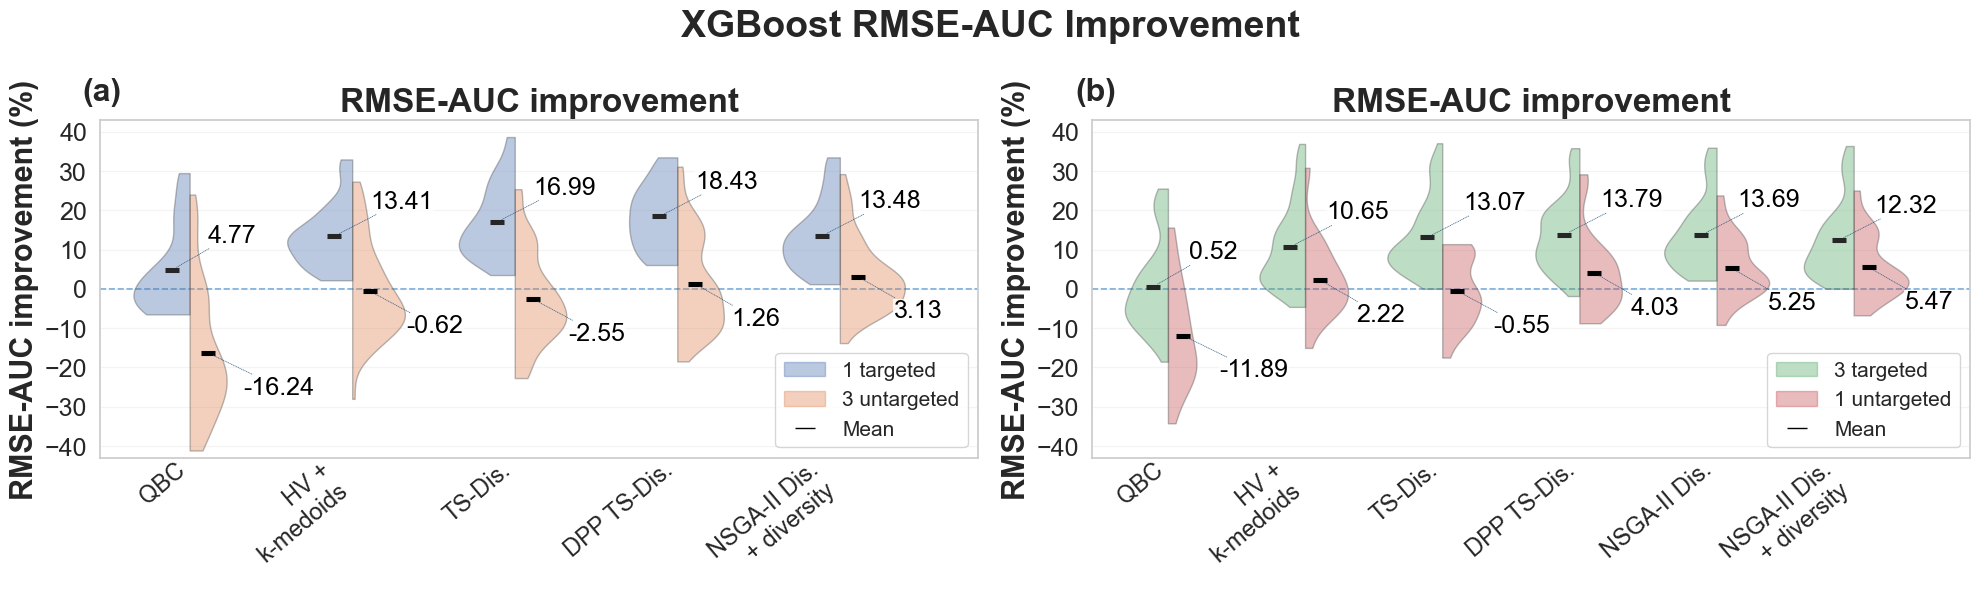

Saved: C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\ThermoElectricNew3\WITH_MODIFICATIONS\plots\Combined_1Target_3Target_XGBoost\XGBoost_1Target_3Target_violin_only.png
Saved one-target raw violin data: C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\ThermoElectricNew3\WITH_MODIFICATIONS\plots\Combined_1Target_3Target_XGBoost\XGBoost_1Target_violin_ALL_CASES_raw_observations.csv
Saved three-target raw violin data: C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\ThermoElectricNew3\WITH_MODIFICATIONS\plots\Combined_1Target_3Target_XGBoost\XGBoost_3Target_violin_ALL_CASES_raw_observations.csv


In [12]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from matplotlib.ticker import ScalarFormatter
from matplotlib.transforms import blended_transform_factory
# =============================================================================
# Configuration
# =============================================================================
BASE_ROOT = Path(
    r"C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES"
    r"\PhD Toronto\DatasetGeneration\Better_Acqsition\ThermoElectricNew3"
    r"\WITH_MODIFICATIONS"
)
DATA_ROOT = BASE_ROOT / "al"
PLOTS_ROOT = BASE_ROOT / "plots"
ANALYSIS_ROOT = BASE_ROOT / "analysis"
OUTPUT_ROOT = PLOTS_ROOT / "Combined_1Target_3Target_XGBoost"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
OUTPUT_FIGURE = OUTPUT_ROOT / "XGBoost_1Target_3Target_violin_only.png"
SEEDS = range(5)
MODEL = "xgb"
# This is the campaign requested:
# targeted = Electrical conductivity + Seebeck coefficient + Thermal conductivity
# untargeted = Figure of merit zT
TARGET_FOLDER = "el_seeb_ThC"
TARGET_PREFIX = "ThermoEl_el_seeb_ThC"
# =============================================================================
# Policies for the RMSE curves
# =============================================================================
POLICIES = {
    "3QBC": (
        "grow_3QBC",
        "growing_3QBC",
    ),
    "HV": (
        "grow_disagreementHV_no_diversity_ThreeTargets",
        "growing_HV_nodiv_3targets",
    ),
    "HV + k-medoids": (
        "grow_disagreementHV_topM_kmedoids_ThreeTargets",
        "growing_3HV_k",
    ),
    "DPP-TS-QBC": (
        "grow_DPP_TS_QBC_ThreeTargets",
        "growing_DPP_TS_QBC_3targets",
    ),
    "NSGA-II QBC": (
        "grow_EA_3Obj_ThreeTargets_QBC_ONLY",
        "growing_EA_3obj_qbc_only",
    ),
    "NSGA-II QBC + diversity": (
        "grow_EA_4Obj_ThreeTargets",
        "growing_EA_3out_div",
    ),
    "TS-QBC": (
        "grow_TS_QBC_no_diversity_ThreeTargets",
        "growing_TS_nodiv_3targets",
    ),
    "MORBO-QBC + Vendi": (
        "grow_MORBO_QBC_vendi_TR_and_sample_diverse_ThreeTargets",
        "growing_MORBO_QBC_vendi_TR_sample_diverse_3targets",
    ),
    "Random": (
        "grow_random",
        "random",
    ),
}
FILLED_MARKER_POLICIES = {
    "HV + k-medoids",
    "DPP-TS-QBC",
    "NSGA-II QBC + diversity",
    "MORBO-QBC + Vendi",
}
POLICY_COLORS = {
    "3QBC": "tab:gray",
    "HV": "tab:orange",
    "HV + k-medoids": "tab:orange",
    "TS-QBC": "tab:green",
    "DPP-TS-QBC": "tab:green",
    "NSGA-II QBC": "tab:red",
    "NSGA-II QBC + diversity": "tab:red",
    "MORBO-QBC + Vendi": "tab:purple",
    "Random": "tab:blue",
}
POLICY_LINESTYLES = {
    "3QBC": "-",
    "HV": "-",
    "HV + k-medoids": "dotted",
    "TS-QBC": "-",
    "DPP-TS-QBC": "dotted",
    "NSGA-II QBC": "-",
    "NSGA-II QBC + diversity": "dotted",
    "MORBO-QBC + Vendi": "dotted",
    "Random": "-",
}
# =============================================================================
# Violin-plot configuration
# =============================================================================
#
# TOP-LEFT PANEL:
#   Aggregate ALL raw one-target campaigns into:
#       1 targeted   = 4 campaigns x 1 targeted property x 5 seeds = 20
#       3 untargeted = 4 campaigns x 3 untargeted properties x 5 seeds = 60
#   observations per policy when all files are present.
#
# TOP-RIGHT PANEL:
#   Aggregate ALL raw three-target campaigns into:
#       3 targeted   = 4 campaigns x 3 targeted properties x 5 seeds = 60
#       1 untargeted = 4 campaigns x 1 untargeted property x 5 seeds = 20
#   observations per policy when all files are present.
#
# Each observation is calculated independently from the raw AL trajectory:
#
#   improvement_percent =
#       100 * (1 - policy_RMSE_AUC_seed / random_RMSE_AUC_seed)
#
# No averaging is done across seeds, properties, campaigns, or policies before
# sns.violinplot. Duplicate rows at exactly the same train_ratio are averaged
# only within one raw trajectory before integrating RMSE-AUC.
#
# IMPORTANT:
# The four RMSE panels still use only TARGET_FOLDER = "el_seeb_ThC".
# =============================================================================
POLICY_ORDER = [
    "QBC",
    "HV + k-medoids",
    "TS-QBC",
    "DPP-TS-QBC",
    "NSGA-II QBC",
    "NSGA-II QBC + diversity",
]
ONE_TARGET_VIOLIN_POLICY_ORDER = [p for p in POLICY_ORDER if p != "NSGA-II QBC"]
THREE_TARGET_VIOLIN_POLICY_ORDER = POLICY_ORDER.copy()
DISPLAY_POLICY_LABELS = {
    "DPP-TS-QBC": "DPP TS-Dis.",
    "TS-QBC": "TS-Dis.",
    "NSGA-II QBC + diversity": "NSGA-II Dis.\n+ diversity",
    "NSGA-II QBC": "NSGA-II Dis.",
    "HV + k-medoids": "HV +\nk-medoids",
    "HV": "HV",
    "QBC": "QBC",
}
CASE_COLORS = {
    "1 targeted": "#4c72b0",
    "3 untargeted": "#dd8452",
    "3 targeted": "#55a868",
    "1 untargeted": "#c44e52",
}
# All 1-target campaign combinations used to build the aggregate violin.
VIOLIN_ONE_TARGET_SETS = {
    "electric_cond": {
        "prefix": "ThermoEl_electric_cond",
        "targeted": {"electric_cond"},
    },
    "seebeck_coef": {
        "prefix": "ThermoEl_seebeck_coef",
        "targeted": {"seebeck_coef"},
    },
    "zT": {
        "prefix": "ThermoEl_zT",
        "targeted": {"zT"},
    },
    "thermal_cond": {
        "prefix": "ThermoEl_thermal_cond",
        "targeted": {"thermal_cond"},
    },
}
# All 3-target campaign combinations used to build the aggregate violin.
VIOLIN_THREE_TARGET_SETS = {
    "el_seeb_zT": {
        "prefix": "ThermoEl_el_seeb_zT",
        "targeted": {"electric_cond", "seebeck_coef", "zT"},
    },
    "el_seeb_ThC": {
        "prefix": "ThermoEl_el_seeb_ThC",
        "targeted": {"electric_cond", "seebeck_coef", "thermal_cond"},
    },
    "el_zT_ThC": {
        "prefix": "ThermoEl_el_zT_ThC",
        "targeted": {"electric_cond", "zT", "thermal_cond"},
    },
    "seeb_zT_ThC": {
        "prefix": "ThermoEl_seeb_zT_ThC",
        "targeted": {"seebeck_coef", "zT", "thermal_cond"},
    },
}
# One-target policies copied from the user's one-target / three-untargeted code.
# HV and NSGA-II QBC were not evaluated for the one-target campaigns, so they
# are intentionally absent from this mapping and from the one-target panel.
ONE_TARGET_VIOLIN_POLICIES = {
    "QBC": (
        "grow_QBC",
        "growing_QBC",
    ),
    "HV + k-medoids": (
        "grow_disagreementHV_topM_kmedoids_OneTarget",
        "growing_1HV_k",
    ),
    "DPP-TS-QBC": (
        "grow_DPP_TS_QBC_OneTarget",
        "growing_DPP_TS_QBC_1target",
    ),
    "NSGA-II QBC + diversity": (
        "grow_EA_DeltaDiversity",
        "growing_EA_1out_div",
    ),
    "TS-QBC": (
        "grow_TS_QBC_no_diversity_OneTarget",
        "growing_TS_nodiv_1target",
    ),
}
THREE_TARGET_VIOLIN_POLICIES = {
    "QBC": (
        "grow_3QBC",
        "growing_3QBC",
    ),
    "HV + k-medoids": (
        "grow_disagreementHV_topM_kmedoids_ThreeTargets",
        "growing_3HV_k",
    ),
    "DPP-TS-QBC": (
        "grow_DPP_TS_QBC_ThreeTargets",
        "growing_DPP_TS_QBC_3targets",
    ),
    "NSGA-II QBC": (
        "grow_EA_3Obj_ThreeTargets_QBC_ONLY",
        "growing_EA_3obj_qbc_only",
    ),
    "NSGA-II QBC + diversity": (
        "grow_EA_4Obj_ThreeTargets",
        "growing_EA_3out_div",
    ),
    "TS-QBC": (
        "grow_TS_QBC_no_diversity_ThreeTargets",
        "growing_TS_nodiv_3targets",
    ),
}
VIOLIN_RMSE_METRICS = {
    "rmse_elec_cond": ("electric_cond", "Electrical conductivity"),
    "rmse_k_total": ("thermal_cond", "Thermal conductivity"),
    "rmse_seebeck": ("seebeck_coef", "Seebeck coefficient"),
    "rmse_zt": ("zT", "Figure of merit (zT)"),
}
OUTPUT_RAW_VIOLIN_ONE_TARGET_DATA = (
    OUTPUT_ROOT / "XGBoost_1Target_violin_ALL_CASES_raw_observations.csv"
)
OUTPUT_RAW_VIOLIN_THREE_TARGET_DATA = (
    OUTPUT_ROOT / "XGBoost_3Target_violin_ALL_CASES_raw_observations.csv"
)
# =============================================================================
# Helpers
# =============================================================================
def result_path(folder, prefix, seed):
    """Path for one XGBoost seed of the requested 3-target campaign."""
    if folder == "grow_random":
        return (
            DATA_ROOT
            / folder
            / "ThermoEl"
            / "all"
            / str(seed)
            / f"ThermoEl_all_random_{MODEL}{seed}.csv"
        )
    return (
        DATA_ROOT
        / folder
        / "ThermoEl"
        / TARGET_FOLDER
        / str(seed)
        / f"{TARGET_PREFIX}{prefix}_{MODEL}{seed}.csv"
    )
def load_policy(label, folder, prefix):
    frames = []
    for seed in SEEDS:
        path = result_path(folder, prefix, seed)
        if not path.exists():
            print(f"Missing: {path}")
            continue
        df = pd.read_csv(path)
        if "train_ratio" not in df.columns:
            raise KeyError(f"'train_ratio' is missing from {path}")
        df = df.copy()
        df["seed"] = seed
        df["policy"] = label
        df["train_percent"] = 100.0 * df["train_ratio"]
        frames.append(df)
    if not frames:
        print(f"Skipping {label}: no files found.")
        return None
    return pd.concat(frames, ignore_index=True)
def summarize(df, metric):
    per_seed = (
        df.groupby(["seed", "train_percent"], as_index=False)[metric]
        .mean()
    )
    return (
        per_seed.groupby("train_percent")[metric]
        .agg(mean="mean", std="std")
        .reset_index()
        .sort_values("train_percent")
    )
def find_first_policy_crosses_random(
    policy_stats,
    random_stats,
    min_percent=5.0,
):
    """
    Find the first point where the mean policy RMSE crosses the mean Random
    RMSE from above.
    QBC checkpoints can be slightly shifted relative to Random/HV, e.g.
    33.55% vs 34.00%. Therefore train_percent is rounded to the nearest
    integer campaign checkpoint before comparing the curves.
    After alignment, define D(x) = policy_mean - random_mean and detect the
    first segment with D_i > 0 and D_{i+1} <= 0. The crossing is estimated by
    linear interpolation.
    """
    policy_aligned = policy_stats[["train_percent", "mean"]].copy()
    random_aligned = random_stats[["train_percent", "mean"]].copy()
    policy_aligned["checkpoint"] = policy_aligned["train_percent"].round().astype(int)
    random_aligned["checkpoint"] = random_aligned["train_percent"].round().astype(int)
    policy_aligned = (
        policy_aligned.groupby("checkpoint", as_index=False)["mean"]
        .mean()
        .rename(columns={"mean": "policy_mean"})
    )
    random_aligned = (
        random_aligned.groupby("checkpoint", as_index=False)["mean"]
        .mean()
        .rename(columns={"mean": "random_mean"})
    )
    merged = (
        policy_aligned.merge(random_aligned, on="checkpoint", how="inner")
        .sort_values("checkpoint")
    )
    merged = merged.loc[merged["checkpoint"] >= int(round(min_percent))].copy()
    merged = merged.loc[
        np.isfinite(merged["policy_mean"]) & np.isfinite(merged["random_mean"])
    ].copy()
    if len(merged) < 2:
        return None
    x = merged["checkpoint"].to_numpy(dtype=float)
    d = (merged["policy_mean"] - merged["random_mean"]).to_numpy(dtype=float)
    first_worse = None
    for i, value in enumerate(d):
        if np.isfinite(value) and value > 0:
            first_worse = i
            break
    if first_worse is None:
        for i, value in enumerate(d):
            if np.isfinite(value) and value <= 0:
                return float(x[i])
        return None
    for i in range(first_worse, len(d) - 1):
        d_i = float(d[i])
        d_j = float(d[i + 1])
        if not np.isfinite(d_i) or not np.isfinite(d_j):
            continue
        x_i = float(x[i])
        x_j = float(x[i + 1])
        if np.isclose(d_i, 0.0, atol=1e-12, rtol=1e-9):
            return x_i
        if d_i > 0 and d_j <= 0:
            if np.isclose(d_j, 0.0, atol=1e-12, rtol=1e-9):
                return x_j
            return float(x_i + (x_j - x_i) * d_i / (d_i - d_j))
    return None
    x = merged["train_percent"].to_numpy(dtype=float)
    d = (
        merged["policy_mean"].to_numpy(dtype=float)
        - merged["random_mean"].to_numpy(dtype=float)
    )
    if len(x) == 1:
        return float(x[0]) if d[0] <= 0 else None
    # If the first valid point is already not worse than Random, use it.
    if d[0] <= 0:
        return float(x[0])
    for i in range(len(x) - 1):
        x_i = float(x[i])
        x_j = float(x[i + 1])
        d_i = float(d[i])
        d_j = float(d[i + 1])
        # If the current sampled checkpoint is already at or below Random,
        # return it directly.
        if d_i <= 0:
            return x_i
        # Exact segment crossing from above to at/below Random.
        if d_i > 0 and d_j <= 0:
            if np.isclose(d_i, d_j, atol=1e-15, rtol=1e-12):
                return x_j
            x_star = x_i + (x_j - x_i) * d_i / (d_i - d_j)
            return float(x_star)
    # Final sampled point if it is at or below Random.
    if d[-1] <= 0:
        return float(x[-1])
    return None
def add_first_crossing_markers(
    ax,
    summary_by_label,
    targeted=True,
):
    if "Random" not in summary_by_label:
        return
    random_stats = summary_by_label["Random"]
    text_transform = blended_transform_factory(ax.transData, ax.transAxes)
    specs = [
        ("3QBC", "QBC"),
        ("HV", "HV"),
    ]
    crossings = {}
    # Unified methodology for both policies.
    for policy_label, display_name in specs:
        if policy_label not in summary_by_label:
            crossings[policy_label] = None
            continue
        x_value = find_first_policy_crosses_random(
            summary_by_label[policy_label],
            random_stats,
            min_percent=5.0,
        )
        crossings[policy_label] = x_value
        if x_value is None:
            print(f"{policy_label}: no crossing with Random found")
        else:
            print(f"{policy_label}: first crossing with Random = {x_value:.2f}%")
    qbc_x = crossings.get("3QBC")
    hv_x = crossings.get("HV")
    # --------------------------------------------------------------
    # Dynamic label positioning to reduce overlaps:
    # - compare proximity in log-x because x-axis is logarithmic
    # - if close, separate more strongly both vertically and horizontally
    # --------------------------------------------------------------
    close_crossings = False
    if qbc_x is not None and hv_x is not None:
        log_sep = abs(np.log10(qbc_x) - np.log10(hv_x))
        close_crossings = log_sep < 0.10
    if close_crossings:
        label_settings = {
            "3QBC": {"y": 0.93, "xoffset": 12, "ha": "left"},
            "HV":   {"y": 0.63, "xoffset": -12, "ha": "right"},
        }
    else:
        label_settings = {
            "3QBC": {"y": 0.88, "xoffset": 7, "ha": "left"},
            "HV":   {"y": 0.70, "xoffset": -7, "ha": "right"},
        }
    # Move QBC downward when its crossing is far to the right, which is where
    # the Targeted / Untargeted label sits. This mainly affects panels like
    # zT and Seebeck.
    if qbc_x is not None and qbc_x >= 30:
        label_settings["3QBC"]["y"] = 0.56
    for policy_label, display_name in specs:
        crossing_x = crossings.get(policy_label)
        if crossing_x is None:
            continue
        color = POLICY_COLORS[policy_label]
        settings = label_settings[policy_label]
        ax.axvline(
            crossing_x,
            color=color,
            linestyle=":",
            linewidth=2.6,
            alpha=0.95,
            zorder=2.4,
        )
        ax.annotate(
            f"{display_name}: {crossing_x:.1f}%",
            xy=(crossing_x, settings["y"]),
            xycoords=text_transform,
            xytext=(settings["xoffset"], 0),
            textcoords="offset points",
            color=color,
            rotation=90,
            ha=settings["ha"],
            va="top",
            fontsize=16,
            fontweight="bold",
            bbox=dict(
                boxstyle="round,pad=0.15",
                facecolor="white",
                edgecolor=color,
                alpha=0.88,
            ),
            zorder=10,
        )
def normalized_rmse_auc_from_raw_file(path, metric):
    """Return normalized RMSE-AUC from one raw AL trajectory CSV."""
    if not path.exists():
        return None
    df = pd.read_csv(path)
    if "train_ratio" not in df.columns:
        print(f"WARNING: 'train_ratio' missing: {path}")
        return None
    if metric not in df.columns:
        print(f"WARNING: '{metric}' missing: {path}")
        return None
    curve = df[["train_ratio", metric]].copy()
    curve["train_ratio"] = pd.to_numeric(
        curve["train_ratio"], errors="coerce"
    )
    curve[metric] = pd.to_numeric(
        curve[metric], errors="coerce"
    )
    # Only collapse duplicate rows at the same AL checkpoint.
    # Do NOT aggregate across seeds, properties, campaigns, or policies.
    curve = (
        curve.dropna()
        .groupby("train_ratio", as_index=False)[metric]
        .mean()
        .sort_values("train_ratio")
    )
    if len(curve) < 2:
        print(f"WARNING: fewer than 2 valid AL iterations: {path} | {metric}")
        return None
    x = 100.0 * curve["train_ratio"].to_numpy(dtype=float)
    y = curve[metric].to_numpy(dtype=float)
    width = x[-1] - x[0]
    if width <= 0:
        print(f"WARNING: invalid AL interval: {path} | {metric}")
        return None
    if hasattr(np, "trapezoid"):
        area = np.trapezoid(y, x)
    else:
        area = np.trapz(y, x)
    return {
        "rmse_auc": float(area / width),
        "first_train_percent": float(x[0]),
        "last_train_percent": float(x[-1]),
        "n_iterations": int(len(curve)),
    }
def violin_random_path(seed):
    return (
        DATA_ROOT
        / "grow_random"
        / "ThermoEl"
        / "all"
        / str(seed)
        / f"ThermoEl_all_random_{MODEL}{seed}.csv"
    )
def violin_policy_path(
    folder,
    target_folder,
    target_prefix,
    suffix,
    seed,
):
    return (
        DATA_ROOT
        / folder
        / "ThermoEl"
        / target_folder
        / str(seed)
        / f"{target_prefix}{suffix}_{MODEL}{seed}.csv"
    )
def load_violin_dataframe(
    *,
    n_targets,
    target_sets,
    policies,
    policy_order,
    targeted_axis,
    untargeted_axis,
    output_csv,
):
    """
    Build one aggregate XGBoost violin dataframe directly from raw AL files.
    Each row is one independent:
        campaign x policy x seed x property
    RMSE-AUC improvement observation relative to the matched Random trajectory
    for the same seed and property.
    """
    rows = []
    # Cache matched Random AUC by seed and property.
    random_auc_cache = {}
    for seed in SEEDS:
        rand_path = violin_random_path(seed)
        if not rand_path.exists():
            print(f"WARNING: missing Random raw file: {rand_path}")
        random_auc_cache[seed] = {
            metric: normalized_rmse_auc_from_raw_file(rand_path, metric)
            for metric in VIOLIN_RMSE_METRICS
        }
    for target_folder, target_info in target_sets.items():
        target_prefix = target_info["prefix"]
        targeted_properties = target_info["targeted"]
        for display_policy in policy_order:
            if display_policy not in policies:
                print(
                    f"WARNING: '{display_policy}' is not configured for "
                    f"n_targets={n_targets}; skipping."
                )
                continue
            folder, suffix = policies[display_policy]
            for seed in SEEDS:
                policy_file = violin_policy_path(
                    folder=folder,
                    target_folder=target_folder,
                    target_prefix=target_prefix,
                    suffix=suffix,
                    seed=seed,
                )
                if not policy_file.exists():
                    print(f"WARNING: missing policy raw file: {policy_file}")
                    continue
                for metric, (
                    property_id,
                    property_name,
                ) in VIOLIN_RMSE_METRICS.items():
                    case_type = (
                        "targeted"
                        if property_id in targeted_properties
                        else "untargeted"
                    )
                    axis = (
                        targeted_axis
                        if case_type == "targeted"
                        else untargeted_axis
                    )
                    policy_auc = normalized_rmse_auc_from_raw_file(
                        policy_file,
                        metric,
                    )
                    random_auc = random_auc_cache[seed].get(metric)
                    if policy_auc is None or random_auc is None:
                        continue
                    if np.isclose(
                        random_auc["rmse_auc"],
                        0.0,
                        atol=1e-15,
                        rtol=0.0,
                    ):
                        print(
                            "WARNING: Random RMSE-AUC is zero; skipping: "
                            f"n_targets={n_targets}, "
                            f"policy={display_policy}, "
                            f"campaign={target_folder}, "
                            f"seed={seed}, "
                            f"property={property_name}"
                        )
                        continue
                    improvement_percent = 100.0 * (
                        1.0
                        - policy_auc["rmse_auc"]
                        / random_auc["rmse_auc"]
                    )
                    rows.append(
                        {
                            "n_targets": n_targets,
                            "display_policy": display_policy,
                            "target_case": target_folder,
                            "seed": seed,
                            "axis": axis,
                            "case_type": case_type,
                            "property_id": property_id,
                            "property_name": property_name,
                            "metric": metric,
                            "improvement_percent": improvement_percent,
                            "policy_rmse_auc": policy_auc["rmse_auc"],
                            "random_rmse_auc": random_auc["rmse_auc"],
                            "policy_file": str(policy_file),
                            "random_file": str(violin_random_path(seed)),
                        }
                    )
    violin_df = pd.DataFrame(rows)
    if violin_df.empty:
        raise RuntimeError(
            f"No raw violin observations were generated for n_targets={n_targets}. "
            "Check DATA_ROOT, filenames, and metric columns."
        )
    violin_df["display_policy"] = pd.Categorical(
        violin_df["display_policy"],
        categories=policy_order,
        ordered=True,
    )
    violin_df["axis"] = pd.Categorical(
        violin_df["axis"],
        categories=[targeted_axis, untargeted_axis],
        ordered=True,
    )
    # Save the EXACT rows supplied to seaborn.
    violin_df.to_csv(output_csv, index=False)
    print(
        "\n"
        f"========== RAW XGBOOST VIOLIN OBSERVATIONS: {n_targets} TARGET(S) =========="
    )
    counts = (
        violin_df.groupby(
            ["display_policy", "axis"],
            observed=True,
        )
        .size()
        .rename("n_raw_observations")
        .reset_index()
    )
    print(counts.to_string(index=False))
    if n_targets == 1:
        print(
            "\nExpected per policy when all files are present:"
            "\n  1 targeted   = 20 observations"
            "\n      4 campaigns x 1 targeted property x 5 seeds"
            "\n  3 untargeted = 60 observations"
            "\n      4 campaigns x 3 untargeted properties x 5 seeds"
        )
    elif n_targets == 3:
        print(
            "\nExpected per policy when all files are present:"
            "\n  3 targeted   = 60 observations"
            "\n      4 campaigns x 3 targeted properties x 5 seeds"
            "\n  1 untargeted = 20 observations"
            "\n      4 campaigns x 1 untargeted property x 5 seeds"
        )
    property_counts = (
        violin_df.groupby(
            ["display_policy", "axis", "property_name"],
            observed=True,
        )
        .size()
        .rename("n")
        .reset_index()
    )
    print("\n========== PROPERTY CONTRIBUTIONS TO VIOLINS ==========")
    print(property_counts.to_string(index=False))
    print(f"\nSaved exact violin observations to: {output_csv}")
    return violin_df
def plot_violin_panel(
    ax,
    violin_df,
    policy_order,
    hue_order,
    title,
    *,
    one_target=False,
    show_ylabel=True,
):
    """Plot one split violin panel using the raw observation dataframe."""
    panel_palette = {
        case_name: CASE_COLORS[case_name]
        for case_name in hue_order
    }
    sns.violinplot(
        data=violin_df,
        x="display_policy",
        y="improvement_percent",
        hue="axis",
        order=policy_order,
        hue_order=hue_order,
        palette=panel_palette,
        split=True,
        inner=None,
        cut=0,
        bw_adjust=0.8,
        gridsize=250,
        linewidth=1.0,
        saturation=1.0,
        ax=ax,
    )
    for collection in ax.collections:
        try:
            collection.set_alpha(0.38)
        except Exception:
            pass
    # Mean shown as a short horizontal line.
    sns.pointplot(
        data=violin_df,
        x="display_policy",
        y="improvement_percent",
        hue="axis",
        order=policy_order,
        hue_order=hue_order,
        estimator=np.mean,
        errorbar=None,
        join=False,
        dodge=0.22,
        markers="_",
        linestyles="none",
        color="black",
        scale=1.8,
        ax=ax,
        legend=False,
        zorder=6,
    )
    # Short dotted leader lines from each black mean marker to its value.
    for hue_index, case_name in enumerate(hue_order):
        means = (violin_df.loc[violin_df["axis"] == case_name]
                 .groupby("display_policy")["improvement_percent"].mean())
        offset = -0.11 if hue_index == 0 else 0.11  # pointplot dodge=0.22
        vertical_offset = 25 if hue_index == 0 else -25
        for i, policy in enumerate(policy_order):
            if policy not in means.index or not np.isfinite(means[policy]):
                continue
            value = float(means[policy])
            label = f"{value:.2f}".rstrip("0").rstrip(".")
            ax.annotate(
                label, xy=(i + offset, value), xytext=(26, vertical_offset),
                textcoords="offset points", ha="left", va="center",
                fontsize=18, fontweight="normal", color="black", zorder=8,
                arrowprops=dict(arrowstyle="-", color="#24527a", linestyle=":",
                                linewidth=0.5, shrinkA=2, shrinkB=4),
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.82, pad=0.4),
            )
    ax.set_xlim(-0.55, len(policy_order) - 0.15)
    ax.axhline(
        0.0,
        linestyle="--",
        linewidth=1.2,
        color="#5b9bd5",
        alpha=0.85,
        zorder=0,
    )
    if ax.get_legend() is not None:
        ax.get_legend().remove()
    ax.set_title(title, fontsize=24, fontweight="bold")
    ax.set_xlabel("")
    if show_ylabel:
        ax.set_ylabel(
            "RMSE-AUC improvement (%)",
            fontsize=22,
            fontweight="bold",
        )
    else:
        ax.set_ylabel("")
    ax.set_xticks(np.arange(len(policy_order)))
    panel_display_labels = [DISPLAY_POLICY_LABELS[p] for p in policy_order]
    ax.set_xticklabels(
        panel_display_labels,
        fontsize=17,
        rotation=40,
        ha="right",
    )
    ax.tick_params(axis="x", labelsize=17, pad=-6)
    ax.tick_params(axis="y", labelsize=18)
    # Use the same y-axis range for both violin panels.
    # Major ticks (and horizontal grid lines) are shown every 10 percentage points.
    # Show 3 percentage points of unlabeled space beyond the ±40% ticks.
    ax.set_ylim(-43, 43)
    ax.set_yticks(np.arange(-40, 41, 10))
    ax.grid(axis="y", which="major", alpha=0.20)
    violin_legend_handles = [
        Patch(
            facecolor=CASE_COLORS[hue_order[0]],
            edgecolor=CASE_COLORS[hue_order[0]],
            alpha=0.38,
            label=hue_order[0],
        ),
        Patch(
            facecolor=CASE_COLORS[hue_order[1]],
            edgecolor=CASE_COLORS[hue_order[1]],
            alpha=0.38,
            label=hue_order[1],
        ),
        plt.Line2D(
            [0], [0],
            color="black",
            marker="_",
            markersize=15,
            linestyle="none",
            label="Mean",
        ),
    ]
    ax.legend(
        handles=violin_legend_handles,
        loc="best",
        fontsize=15,
        frameon=True,
    )
# =============================================================================
# RMSE plotting helper
# =============================================================================
def plot_rmse_panel(ax, data, metric, title, ylabel, target_label):
    summary_by_label = {}
    for label, df in data.items():
        if metric not in df.columns:
            print(f"Missing column '{metric}' for {label}.")
            continue
        stats = summarize(df, metric)
        summary_by_label[label] = stats
        x = stats["train_percent"].to_numpy()
        mean = stats["mean"].to_numpy()
        std = stats["std"].fillna(0.0).to_numpy()
        color = POLICY_COLORS[label]
        linestyle = POLICY_LINESTYLES[label]
        if label == "Random":
            line = ax.plot(
                x,
                mean,
                label=label,
                color=color,
                linewidth=2.8,
                linestyle=linestyle,
                marker=None,
                zorder=3,
            )[0]
        elif label in FILLED_MARKER_POLICIES:
            line = ax.plot(
                x,
                mean,
                label=label,
                color=color,
                linewidth=2.0,
                linestyle=linestyle,
                zorder=3,
            )[0]
        else:
            line = ax.plot(
                x,
                mean,
                label=label,
                color=color,
                linewidth=2.0,
                linestyle=linestyle,
                zorder=3,
            )[0]
        lower = (mean - std).astype(float)
        upper = (mean + std).astype(float)
        lower[lower <= 0] = np.nan
        ax.fill_between(
            x,
            lower,
            upper,
            color=color,
            alpha=0.10,
            linewidth=0,
            zorder=1,
        )
    ax.set_title(title, fontsize=24, fontweight="bold")
    ax.set_xlabel("Training data (%)", fontsize=20, fontweight="bold")
    ax.set_ylabel(ylabel, fontsize=20, fontweight="bold")
    ax.set_xscale("log", base=16)
    ax.set_yscale("log", base=2)
    formatter = ScalarFormatter()
    formatter.set_scientific(False)
    formatter.set_useOffset(False)
    ax.yaxis.set_major_formatter(formatter)
    ax.set_xticks([5, 10, 20, 50, 100])
    ax.set_xticklabels(["5", "10", "20", "50", "100"])
    ax.set_xlim(5, 100)
    ax.tick_params(axis="both", labelsize=18)
    ax.grid(which="major", alpha=0.30)
    ax.grid(which="minor", alpha=0.10)
    add_first_crossing_markers(
        ax,
        summary_by_label,
        targeted=(target_label.lower() == "targeted"),
    )
    # Requested targeted / untargeted label inside the plot.
    ax.text(
        0.96,
        0.94,
        target_label,
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=18,
        fontweight="bold",
        bbox=dict(
            boxstyle="round,pad=0.25",
            facecolor="white",
            edgecolor="0.4",
            alpha=0.90,
        ),
        zorder=10,
    )
# =============================================================================
# Load violin data DIRECTLY from raw AL trajectory files
# =============================================================================
violin_one_target_df = load_violin_dataframe(
    n_targets=1,
    target_sets=VIOLIN_ONE_TARGET_SETS,
    policies=ONE_TARGET_VIOLIN_POLICIES,
    policy_order=ONE_TARGET_VIOLIN_POLICY_ORDER,
    targeted_axis="1 targeted",
    untargeted_axis="3 untargeted",
    output_csv=OUTPUT_RAW_VIOLIN_ONE_TARGET_DATA,
)
violin_three_target_df = load_violin_dataframe(
    n_targets=3,
    target_sets=VIOLIN_THREE_TARGET_SETS,
    policies=THREE_TARGET_VIOLIN_POLICIES,
    policy_order=THREE_TARGET_VIOLIN_POLICY_ORDER,
    targeted_axis="3 targeted",
    untargeted_axis="1 untargeted",
    output_csv=OUTPUT_RAW_VIOLIN_THREE_TARGET_DATA,
)
# =============================================================================
# Build ONE figure: 1 row x 4 columns
#
#   columns 1-2 -> XGBoost violin: 1 targeted / 3 untargeted
#   columns 3-4 -> XGBoost violin: 3 targeted / 1 untargeted
# =============================================================================
# Use the requested fixed order for policies with available observations.
ONE_TARGET_PLOT_ORDER = [
    p for p in ONE_TARGET_VIOLIN_POLICY_ORDER
    if p in violin_one_target_df["display_policy"].values
]
THREE_TARGET_PLOT_ORDER = [
    p for p in THREE_TARGET_VIOLIN_POLICY_ORDER
    if p in violin_three_target_df["display_policy"].values
]
print("One-target plotting order:", ONE_TARGET_PLOT_ORDER)
print("Three-target plotting order:", THREE_TARGET_PLOT_ORDER)
sns.set_theme(style="whitegrid")
fig = plt.figure(figsize=(20, 6.5))
gs = fig.add_gridspec(
    nrows=1,
    ncols=4,
    width_ratios=[1.0, 1.0, 1.0, 1.0],
    wspace=0.30,
)
# Each violin spans two columns.
ax_violin_one = fig.add_subplot(gs[0, 0:2])
ax_violin_three = fig.add_subplot(gs[0, 2:4])
# =============================================================================
# Panel A: XGBoost violin, ALL 1-target cases
# =============================================================================
plot_violin_panel(
    ax=ax_violin_one,
    violin_df=violin_one_target_df,
    policy_order=ONE_TARGET_PLOT_ORDER,
    hue_order=["1 targeted", "3 untargeted"],
    title="RMSE-AUC improvement",
    one_target=True,
    show_ylabel=True,
)
# =============================================================================
# Panel B: XGBoost violin, ALL 3-target cases
# =============================================================================
plot_violin_panel(
    ax=ax_violin_three,
    violin_df=violin_three_target_df,
    policy_order=THREE_TARGET_PLOT_ORDER,
    hue_order=["3 targeted", "1 untargeted"],
    title="RMSE-AUC improvement",
    one_target=False,
    show_ylabel=True,
)
# =============================================================================
# Panel labels
# =============================================================================
for ax, label in [
    (ax_violin_one, "(a)"),
    (ax_violin_three, "(b)"),
]:
    ax.text(
        -0.02,
        1.04,
        label,
        transform=ax.transAxes,
        fontsize=23,
        fontweight="bold",
        va="bottom",
        ha="left",
    )
# =============================================================================
# Save
# =============================================================================
fig.suptitle("XGBoost RMSE-AUC Improvement", fontsize=27, fontweight="bold", y=0.99)
fig.subplots_adjust(
    left=0.055,
    right=0.99,
    top=0.82,
    bottom=0.30,
)
fig.savefig(
    OUTPUT_FIGURE,
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)
print(f"Saved: {OUTPUT_FIGURE}")
print(f"Saved one-target raw violin data: {OUTPUT_RAW_VIOLIN_ONE_TARGET_DATA}")
print(f"Saved three-target raw violin data: {OUTPUT_RAW_VIOLIN_THREE_TARGET_DATA}")


PER PROPERTY DISTRIBUTION PLOTS


EXPECTED RAW CAMPAIGNS
Models          : 2
Target cases    : 6
Policies        : 7
Seeds           : 5
Expected policy files = 420

MISSING POLICY FILE COUNT
0 missing out of 420 expected policy files

LOADED OBSERVATIONS BY MODEL / POLICY / AXIS
model                  policy         axis  n_observations
   rf              DPP-TS-QBC   2 targeted              60
   rf              DPP-TS-QBC 2 untargeted              60
   rf                      HV   2 targeted              60
   rf                      HV 2 untargeted              60
   rf          HV + k-medoids   2 targeted              60
   rf          HV + k-medoids 2 untargeted              60
   rf             NSGA-II QBC   2 targeted              60
   rf             NSGA-II QBC 2 untargeted              60
   rf NSGA-II QBC + diversity   2 targeted              60
   rf NSGA-II QBC + diversity 2 untargeted              60
   rf                     QBC   2 targeted              60
   rf                     QBC 2 untargeted  

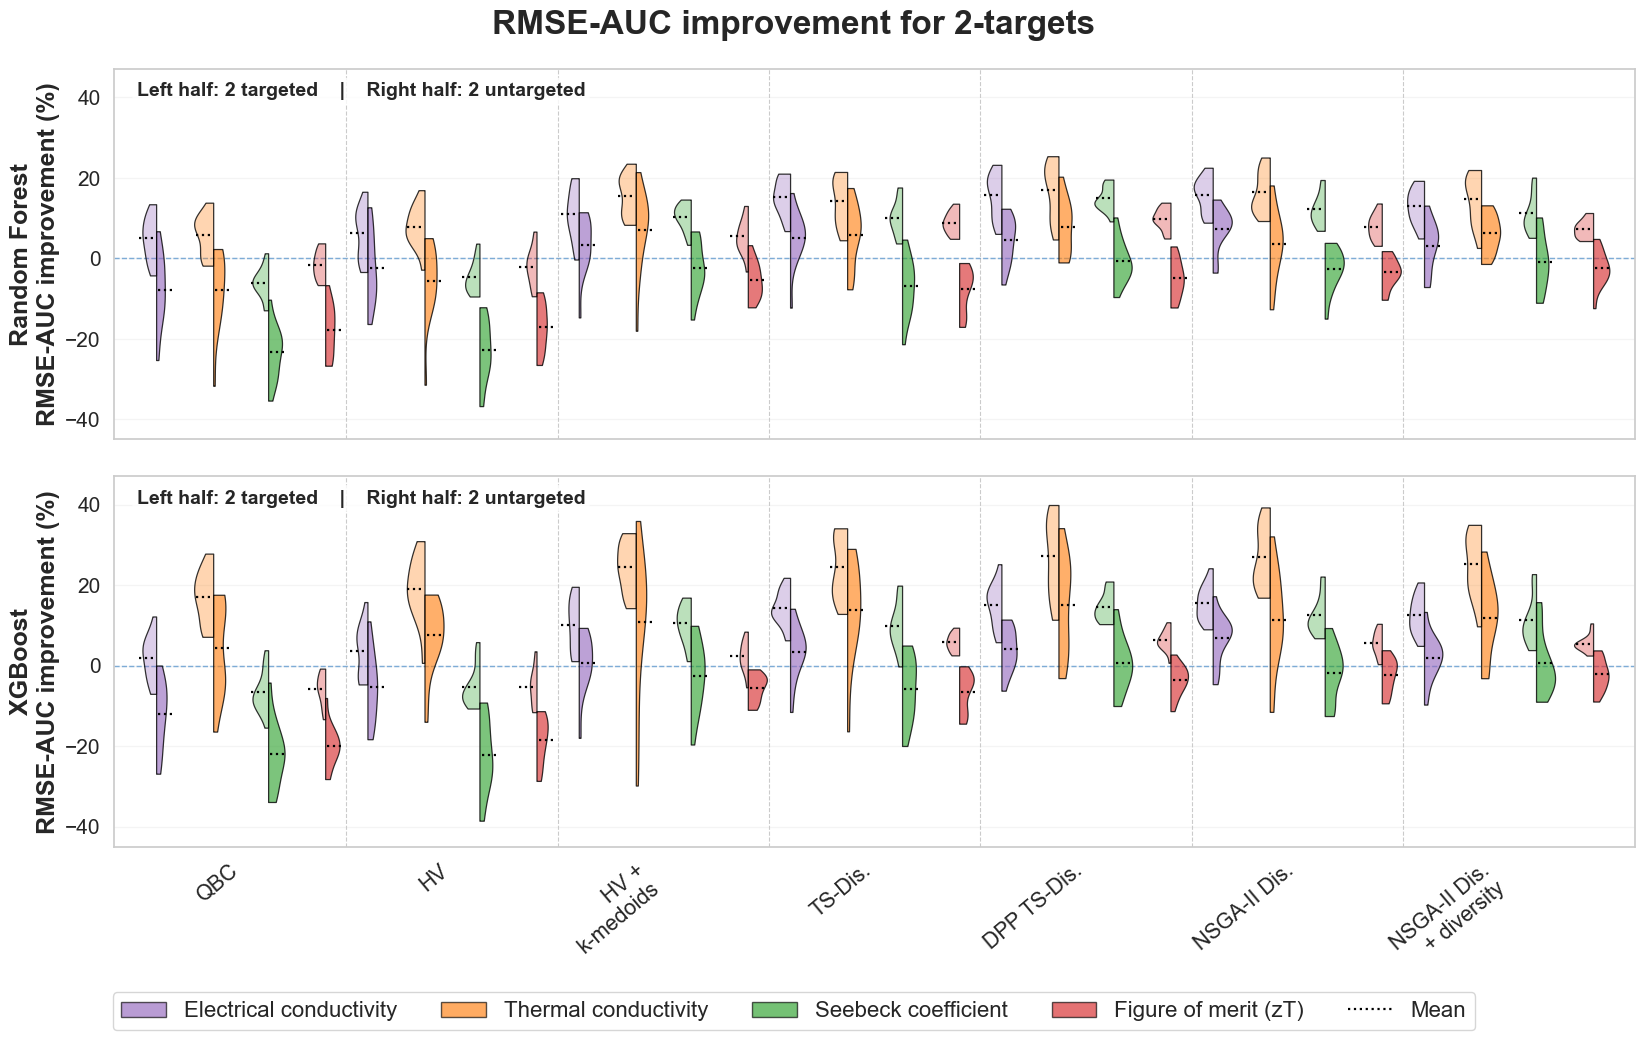


Saved figure:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\ThermoElectricNew3\WITH_MODIFICATIONS\plots\Property_Mean_Direct_From_AL\property_split_violins_direct_from_AL_2targets_RF_XGB_ALL_CASES.png

Saved raw observations:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\ThermoElectricNew3\WITH_MODIFICATIONS\plots\Property_Mean_Direct_From_AL\property_seed_improvements_direct_from_AL_2targets_RF_XGB_ALL_CASES.csv

Saved statistics:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\ThermoElectricNew3\WITH_MODIFICATIONS\plots\Property_Mean_Direct_From_AL\property_mean_std_count_direct_from_AL_2targets_RF_XGB_ALL_CASES.csv

Saved raw file diagnostic:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\ThermoElectricNew3\WITH_MODIFICATIONS

In [14]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
# Configuration
BASE_ROOT = Path(
    r"C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES"
    r"\PhD Toronto\DatasetGeneration\Better_Acqsition\ThermoElectricNew3"
    r"\WITH_MODIFICATIONS"
)
DATA_ROOT = BASE_ROOT / "al"
OUTPUT_ROOT = BASE_ROOT / "plots" / "Property_Mean_Direct_From_AL"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
OUTPUT_FIGURE = OUTPUT_ROOT / "property_split_violins_direct_from_AL_2targets_RF_XGB_ALL_CASES.png"
OUTPUT_RAW_CASES = OUTPUT_ROOT / "property_seed_improvements_direct_from_AL_2targets_RF_XGB_ALL_CASES.csv"
OUTPUT_STATS = OUTPUT_ROOT / "property_mean_std_count_direct_from_AL_2targets_RF_XGB_ALL_CASES.csv"
OUTPUT_FILE_DIAGNOSTIC = OUTPUT_ROOT / "2target_raw_file_diagnostic_RF_XGB_ALL_CASES.csv"
SEEDS = range(5)
MODELS = {"rf": "Random Forest", "xgb": "XGBoost"}
MODEL_ORDER = ["rf", "xgb"]
# Properties and raw RMSE columns
RMSE_METRICS = {
    "rmse_elec_cond": "Electrical conductivity",
    "rmse_k_total": "Thermal conductivity",
    "rmse_seebeck": "Seebeck coefficient",
    "rmse_zt": "Figure of merit (zT)",
}
PROPERTY_ID_BY_METRIC = {
    "rmse_elec_cond": "electric_cond",
    "rmse_k_total": "thermal_cond",
    "rmse_seebeck": "seebeck_coef",
    "rmse_zt": "zT",
}
PROPERTY_ORDER = [
    "Electrical conductivity",
    "Thermal conductivity",
    "Seebeck coefficient",
    "Figure of merit (zT)",
]
PROPERTY_COLORS = {
    "Electrical conductivity": "#9467bd",
    "Thermal conductivity": "#ff7f0e",
    "Seebeck coefficient": "#2ca02c",
    "Figure of merit (zT)": "#d62728",
}
PROPERTY_X_OFFSETS = {
    "Electrical conductivity": -0.40,
    "Thermal conductivity": -0.13,
    "Seebeck coefficient": +0.13,
    "Figure of merit (zT)": +0.40,
}
VIOLIN_WIDTH = 0.18
# Six two-target campaigns
TWO_TARGET_SETS = {
    "el_seeb": {
        "prefix": "ThermoEl_el_seeb",
        "targeted": {"electric_cond", "seebeck_coef"},
    },
    "el_ThC": {
        "prefix": "ThermoEl_el_ThC",
        "targeted": {"electric_cond", "thermal_cond"},
    },
    "el_zT": {
        "prefix": "ThermoEl_el_zT",
        "targeted": {"electric_cond", "zT"},
    },
    "seeb_ThC": {
        "prefix": "ThermoEl_seeb_ThC",
        "targeted": {"seebeck_coef", "thermal_cond"},
    },
    "seeb_zT": {
        "prefix": "ThermoEl_seeb_zT",
        "targeted": {"seebeck_coef", "zT"},
    },
    "zT_ThC": {
        "prefix": "ThermoEl_zT_ThC",
        "targeted": {"zT", "thermal_cond"},
    },
}
# Preserve the actual raw folder names and filename suffixes
POLICY_CONFIG = {
    "QBC": {
        "folder": "grow_2QBC",
        "suffix": "growing_2QBC",
    },
    "HV": {
        "folder": "grow_disagreementHV_no_diversity_TwoTargets",
        "suffix": "growing_HV_nodiv_2targets",
    },
    "HV + k-medoids": {
        "folder": "grow_disagreementHV_topM_kmedoids_TwoTargets",
        "suffix": "growing_2HV_k",
    },
    "NSGA-II QBC": {
        "folder": "grow_EA_2Obj_TwoTargets_QBC_ONLY",
        "suffix": "growing_EA_2obj_qbc_only",
    },
    "NSGA-II QBC + diversity": {
        "folder": "grow_EA_3Obj_TwoTargets",
        "suffix": "growing_EA_2out_div",
    },
    "TS-QBC": {
        "folder": "grow_TS_QBC_no_diversity_TwoTargets",
        "suffix": "growing_TS_nodiv_2targets",
    },
    "DPP-TS-QBC": {
        "folder": "grow_DPP_TS_QBC_TwoTargets",
        "suffix": "grow_DPP_TS_QBC_2targets",
    },
}
# Consistent plotting order and displayed names
POLICY_ORDER = [
    "QBC",
    "HV",
    "HV + k-medoids",
    "TS-QBC",
    "DPP-TS-QBC",
    "NSGA-II QBC",
    "NSGA-II QBC + diversity",
]
DISPLAY_POLICY_LABELS = {
    "QBC": "QBC",
    "HV": "HV",
    "HV + k-medoids": "HV +\nk-medoids",
    "TS-QBC": "TS-Dis.",
    "DPP-TS-QBC": "DPP TS-Dis.",
    "NSGA-II QBC": "NSGA-II Dis.",
    "NSGA-II QBC + diversity": "NSGA-II Dis.\n+ diversity",
}
# Raw-file paths
def random_path(model, seed):
    return (
        DATA_ROOT
        / "grow_random"
        / "ThermoEl"
        / "all"
        / str(seed)
        / f"ThermoEl_all_random_{model}{seed}.csv"
    )
def policy_path(policy, target_folder, model, seed):
    config = POLICY_CONFIG[policy]
    target_prefix = TWO_TARGET_SETS[target_folder]["prefix"]
    return (
        DATA_ROOT
        / config["folder"]
        / "ThermoEl"
        / target_folder
        / str(seed)
        / f"{target_prefix}{config['suffix']}_{model}{seed}.csv"
    )
# RMSE-AUC directly from raw files
def normalized_rmse_auc_from_file(path, metric):
    if not path.exists():
        return None
    df = pd.read_csv(path)
    if "train_ratio" not in df.columns:
        print(f"WARNING: 'train_ratio' missing: {path}")
        return None
    if metric not in df.columns:
        print(f"WARNING: '{metric}' missing: {path}")
        return None
    curve = df[["train_ratio", metric]].copy()
    curve["train_ratio"] = pd.to_numeric(curve["train_ratio"], errors="coerce")
    curve[metric] = pd.to_numeric(curve[metric], errors="coerce")
    curve = (
        curve.dropna()
        .groupby("train_ratio", as_index=False)[metric]
        .mean()
        .sort_values("train_ratio")
    )
    if len(curve) < 2:
        return None
    x = 100.0 * curve["train_ratio"].to_numpy(dtype=float)
    y = curve[metric].to_numpy(dtype=float)
    width = x[-1] - x[0]
    if width <= 0:
        return None
    if hasattr(np, "trapezoid"):
        area = np.trapezoid(y, x)
    else:
        area = np.trapz(y, x)
    return float(area / width)
# Collect every available raw observation
def collect_raw_improvements():
    rows = []
    diagnostics = []
    for model in MODEL_ORDER:
        for target_folder, target_info in TWO_TARGET_SETS.items():
            targeted_properties = target_info["targeted"]
            for seed in SEEDS:
                rand_path = random_path(model, seed)
                random_exists = rand_path.exists()
                if random_exists:
                    random_auc = {
                        metric: normalized_rmse_auc_from_file(rand_path, metric)
                        for metric in RMSE_METRICS
                    }
                else:
                    random_auc = {metric: None for metric in RMSE_METRICS}
                for policy in POLICY_ORDER:
                    pol_path = policy_path(
                        policy=policy,
                        target_folder=target_folder,
                        model=model,
                        seed=seed,
                    )
                    policy_exists = pol_path.exists()
                    diagnostics.append({
                        "model": model,
                        "target_case": target_folder,
                        "seed": seed,
                        "policy": policy,
                        "policy_file_exists": policy_exists,
                        "random_file_exists": random_exists,
                        "policy_file": str(pol_path),
                        "random_file": str(rand_path),
                    })
                    if not random_exists:
                        continue
                    if not policy_exists:
                        print(
                            "MISSING POLICY FILE | "
                            f"{model} | {target_folder} | "
                            f"seed={seed} | {policy}\n"
                            f"    {pol_path}"
                        )
                        continue
                    for metric, property_name in RMSE_METRICS.items():
                        property_id = PROPERTY_ID_BY_METRIC[metric]
                        if property_id in targeted_properties:
                            case_type = "targeted"
                            axis_name = "2 targeted"
                        else:
                            case_type = "untargeted"
                            axis_name = "2 untargeted"
                        pol_auc = normalized_rmse_auc_from_file(pol_path, metric)
                        rand_auc = random_auc[metric]
                        if pol_auc is None or rand_auc is None:
                            continue
                        if rand_auc == 0:
                            continue
                        improvement_percent = 100.0 * (1.0 - pol_auc / rand_auc)
                        rows.append({
                            "model": model,
                            "model_name": MODELS[model],
                            "n_targets": 2,
                            "axis": axis_name,
                            "case_type": case_type,
                            "target_case": target_folder,
                            "policy": policy,
                            "seed": seed,
                            "metric": metric,
                            "property_id": property_id,
                            "property_name": property_name,
                            "improvement_percent": improvement_percent,
                            "policy_rmse_auc": pol_auc,
                            "random_rmse_auc": rand_auc,
                            "policy_file": str(pol_path),
                            "random_file": str(rand_path),
                        })
    diagnostic_df = pd.DataFrame(diagnostics)
    diagnostic_df.to_csv(OUTPUT_FILE_DIAGNOSTIC, index=False)
    raw_df = pd.DataFrame(rows)
    if raw_df.empty:
        raise RuntimeError(
            "No raw observations were loaded. "
            "Check the paths printed in the diagnostic."
        )
    return raw_df, diagnostic_df
# Load data and report diagnostics
raw_df, diagnostic_df = collect_raw_improvements()
raw_df.to_csv(OUTPUT_RAW_CASES, index=False)
print("\n============================================================")
print("EXPECTED RAW CAMPAIGNS")
print("============================================================")
print(f"Models          : {len(MODEL_ORDER)}")
print(f"Target cases    : {len(TWO_TARGET_SETS)}")
print(f"Policies        : {len(POLICY_ORDER)}")
print(f"Seeds           : {len(SEEDS)}")
print(
    "Expected policy files = "
    f"{len(MODEL_ORDER) * len(TWO_TARGET_SETS) * len(POLICY_ORDER) * len(SEEDS)}"
)
print("\n============================================================")
print("MISSING POLICY FILE COUNT")
print("============================================================")
missing_files = diagnostic_df.loc[
    ~diagnostic_df["policy_file_exists"]
].copy()
print(
    f"{len(missing_files)} missing out of "
    f"{len(diagnostic_df)} expected policy files"
)
if not missing_files.empty:
    print(
        missing_files[
            ["model", "target_case", "seed", "policy", "policy_file"]
        ].to_string(index=False)
    )
print("\n============================================================")
print("LOADED OBSERVATIONS BY MODEL / POLICY / AXIS")
print("============================================================")
loaded_counts = (
    raw_df.groupby(["model", "policy", "axis"], as_index=False)
    .size()
    .rename(columns={"size": "n_observations"})
)
print(loaded_counts.to_string(index=False))
print("\n============================================================")
print("LOADED TARGET CASES BY MODEL / POLICY")
print("============================================================")
case_counts = (
    raw_df[["model", "policy", "target_case"]]
    .drop_duplicates()
    .groupby(["model", "policy"], as_index=False)
    .size()
    .rename(columns={"size": "n_target_cases"})
)
print(case_counts.to_string(index=False))
# Summary statistics
stats_df = (
    raw_df.groupby(
        [
            "model",
            "model_name",
            "axis",
            "case_type",
            "policy",
            "property_id",
            "property_name",
        ],
        as_index=False,
    )["improvement_percent"]
    .agg(
        mean_percent="mean",
        std_percent="std",
        count="count",
    )
)
stats_df.to_csv(OUTPUT_STATS, index=False)
# Shared y limits
all_values = pd.to_numeric(raw_df["improvement_percent"], errors="coerce")
all_values = all_values[np.isfinite(all_values)]
if len(all_values) == 0:
    GLOBAL_Y_LIM = (-1, 1)
else:
    global_min = float(all_values.min())
    global_max = float(all_values.max())
    global_span = max(global_max - global_min, 1.0)
    global_padding = max(1.0, 0.08 * global_span)
    y_min = min(int(np.floor(global_min - global_padding)), 0)
    y_max = max(int(np.ceil(global_max + global_padding)), 0)
    GLOBAL_Y_LIM = (y_min, y_max)
# Plot helpers
def shift_new_violin_bodies(ax, start_collection_idx, x_offset):
    for coll in ax.collections[start_collection_idx:]:
        if not hasattr(coll, "get_paths"):
            continue
        for path in coll.get_paths():
            path.vertices[:, 0] += x_offset
def draw_half_mean_line(ax, values, position, width, side):
    if len(values) == 0:
        return
    mean_val = float(np.mean(values))
    half_pad = 0.01
    half_extent = 0.46 * width
    if side == "left":
        x0 = position - half_extent
        x1 = position - half_pad
    else:
        x0 = position + half_pad
        x1 = position + half_extent
    ax.hlines(
        mean_val,
        x0,
        x1,
        colors="black",
        linewidth=1.6,
        linestyles=":",
        zorder=4,
    )
# Figure: Random Forest above, XGBoost below
# Each property's left half is targeted; right half is untargeted
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(17.0, 10.8),
    sharex=False,
    sharey=True,
)
common_y_min, common_y_max = GLOBAL_Y_LIM
common_policy_order = POLICY_ORDER
x_positions = np.arange(len(common_policy_order), dtype=float)
for row_index, model in enumerate(MODEL_ORDER):
    ax = axes[row_index]
    model_df = raw_df.loc[raw_df["model"] == model].copy()
    targeted_df = model_df.loc[model_df["axis"] == "2 targeted"].copy()
    untargeted_df = model_df.loc[model_df["axis"] == "2 untargeted"].copy()
    for property_name in PROPERTY_ORDER:
        color = PROPERTY_COLORS[property_name]
        targeted_prop_df = targeted_df.loc[
            targeted_df["property_name"] == property_name,
            ["policy", "improvement_percent"],
        ].copy()
        untargeted_prop_df = untargeted_df.loc[
            untargeted_df["property_name"] == property_name,
            ["policy", "improvement_percent"],
        ].copy()
        targeted_prop_df["comparison_case"] = "targeted"
        untargeted_prop_df["comparison_case"] = "untargeted"
        prop_df = pd.concat(
            [targeted_prop_df, untargeted_prop_df],
            ignore_index=True,
        )
        prop_df["policy"] = pd.Categorical(
            prop_df["policy"],
            categories=common_policy_order,
            ordered=True,
        )
        prop_df["comparison_case"] = pd.Categorical(
            prop_df["comparison_case"],
            categories=["targeted", "untargeted"],
            ordered=True,
        )
        prop_df["improvement_percent"] = pd.to_numeric(
            prop_df["improvement_percent"], errors="coerce"
        )
        prop_df = prop_df.dropna(subset=["improvement_percent"])
        if prop_df.empty:
            print(f"WARNING: no observations for {model} / {property_name}")
            continue
        start_idx = len(ax.collections)
        sns.violinplot(
            data=prop_df,
            x="policy",
            y="improvement_percent",
            hue="comparison_case",
            order=common_policy_order,
            hue_order=["targeted", "untargeted"],
            split=True,
            inner=None,
            cut=0,
            bw_adjust=1.0,
            gridsize=200,
            linewidth=1.0,
            saturation=1.0,
            palette={"targeted": color, "untargeted": color},
            width=VIOLIN_WIDTH,
            ax=ax,
        )
        shift_new_violin_bodies(
            ax=ax,
            start_collection_idx=start_idx,
            x_offset=PROPERTY_X_OFFSETS[property_name],
        )
        # Targeted half is lighter; untargeted half is darker
        new_collections = ax.collections[start_idx:]
        property_rgb = mcolors.to_rgb(color)
        expected_centers = x_positions + PROPERTY_X_OFFSETS[property_name]
        for coll in new_collections:
            try:
                paths = coll.get_paths()
                if not paths:
                    continue
                verts = paths[0].vertices
                x_mean = float(np.mean(verts[:, 0]))
                nearest_center = float(
                    expected_centers[
                        np.argmin(np.abs(expected_centers - x_mean))
                    ]
                )
                if x_mean < nearest_center:
                    face_rgba = (*property_rgb, 0.32)
                else:
                    face_rgba = (*property_rgb, 0.62)
                coll.set_alpha(None)
                coll.set_facecolor([face_rgba])
                coll.set_edgecolor((*mcolors.to_rgb("black"), 0.80))
                coll.set_linewidth(0.9)
            except Exception as exc:
                print(f"WARNING: could not style {property_name}: {exc}")
        if ax.get_legend() is not None:
            ax.get_legend().remove()
        # Mean lines for each half of each property distribution
        for x, policy in zip(x_positions, common_policy_order):
            targeted_values = pd.to_numeric(
                targeted_df.loc[
                    (targeted_df["policy"] == policy)
                    & (targeted_df["property_name"] == property_name),
                    "improvement_percent",
                ],
                errors="coerce",
            )
            targeted_values = targeted_values[
                np.isfinite(targeted_values)
            ].to_numpy(dtype=float)
            untargeted_values = pd.to_numeric(
                untargeted_df.loc[
                    (untargeted_df["policy"] == policy)
                    & (untargeted_df["property_name"] == property_name),
                    "improvement_percent",
                ],
                errors="coerce",
            )
            untargeted_values = untargeted_values[
                np.isfinite(untargeted_values)
            ].to_numpy(dtype=float)
            x_plot = x + PROPERTY_X_OFFSETS[property_name]
            if len(targeted_values) > 0:
                draw_half_mean_line(
                    ax=ax,
                    values=targeted_values,
                    position=x_plot,
                    width=VIOLIN_WIDTH,
                    side="left",
                )
            if len(untargeted_values) > 0:
                draw_half_mean_line(
                    ax=ax,
                    values=untargeted_values,
                    position=x_plot,
                    width=VIOLIN_WIDTH,
                    side="right",
                )
    # Axes
    ax.set_ylim(common_y_min, common_y_max)
    ax.set_xlim(-0.60, len(common_policy_order) - 0.40)
    ax.set_xticks(x_positions)
    if row_index == 0:
        ax.set_xticklabels([])
        ax.tick_params(axis="x", which="both", labelbottom=False)
    else:
        ax.set_xticklabels(
            [DISPLAY_POLICY_LABELS[p] for p in common_policy_order],
            fontsize=15.5,
            rotation=40,
            ha="right",
        )
        ax.tick_params(axis="x", which="both", labelbottom=True)
    ax.grid(axis="y", alpha=0.20)
    ax.axhline(
        0.0,
        color="#5b9bd5",
        linewidth=1.0,
        linestyle="--",
        alpha=0.90,
        zorder=0,
    )
    for separator_x in np.arange(len(common_policy_order) - 1, dtype=float) + 0.5:
        ax.axvline(
            separator_x,
            color="0.55",
            linewidth=0.8,
            linestyle="--",
            alpha=0.45,
            zorder=0,
        )
    ax.tick_params(axis="y", labelsize=15)
    ax.text(
        0.015,
        0.965,
        "Left half: 2 targeted    |    Right half: 2 untargeted",
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=14,
        fontweight="bold",
        bbox=dict(
            boxstyle="round,pad=0.22",
            facecolor="white",
            edgecolor="none",
            alpha=0.82,
        ),
    )
    ax.set_ylabel(
        f"{MODELS[model]}\nRMSE-AUC improvement (%)",
        fontsize=18,
        fontweight="bold",
    )
    ax.set_xlabel("")
# Title and legend
fig.suptitle(
    "RMSE-AUC improvement for 2-targets",
    fontsize=24,
    fontweight="bold",
    y=0.975,
)
property_handles = [
    Patch(
        facecolor=PROPERTY_COLORS[property_name],
        edgecolor="black",
        alpha=0.65,
        label=property_name,
    )
    for property_name in PROPERTY_ORDER
]
property_handles += [
    Line2D(
        [0],
        [0],
        color="black",
        linewidth=1.6,
        linestyle=":",
        label="Mean",
    )
]
fig.legend(
    handles=property_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.02),
    ncol=5,
    fontsize=16,
    frameon=True,
)
plt.subplots_adjust(
    left=0.10,
    right=0.995,
    top=0.92,
    bottom=0.20,
    hspace=0.10,
)
fig.savefig(OUTPUT_FIGURE, dpi=250, bbox_inches="tight")
plt.show()
plt.close(fig)
print("\nSaved figure:")
print(OUTPUT_FIGURE)
print("\nSaved raw observations:")
print(OUTPUT_RAW_CASES)
print("\nSaved statistics:")
print(OUTPUT_STATS)
print("\nSaved raw file diagnostic:")
print(OUTPUT_FILE_DIAGNOSTIC)


================ RAW AL FILE DIAGNOSTIC ================
Missing policy files encountered: 0
Missing Random files encountered: 0

================ DIRECT RAW-AL STATISTICS ================
 rf | 1 targeted     | DPP TS-Dis.                 | Electrical conductivity    | mean= 20.1376 | std=  4.5582 | count= 5
 rf | 1 targeted     | DPP TS-Dis.                 | Seebeck coefficient        | mean= 16.8872 | std=  2.6857 | count= 5
 rf | 1 targeted     | DPP TS-Dis.                 | Thermal conductivity       | mean= 19.0353 | std=  3.9280 | count= 5
 rf | 1 targeted     | DPP TS-Dis.                 | Figure of merit (zT)       | mean= 11.8106 | std=  3.5299 | count= 5
 rf | 1 targeted     | HV + k-medoids              | Electrical conductivity    | mean= 13.0904 | std=  2.8804 | count= 5
 rf | 1 targeted     | HV + k-medoids              | Seebeck coefficient        | mean= 13.6906 | std=  3.2151 | count= 5
 rf | 1 targeted     | HV + k-medoids              | Thermal conductivity     

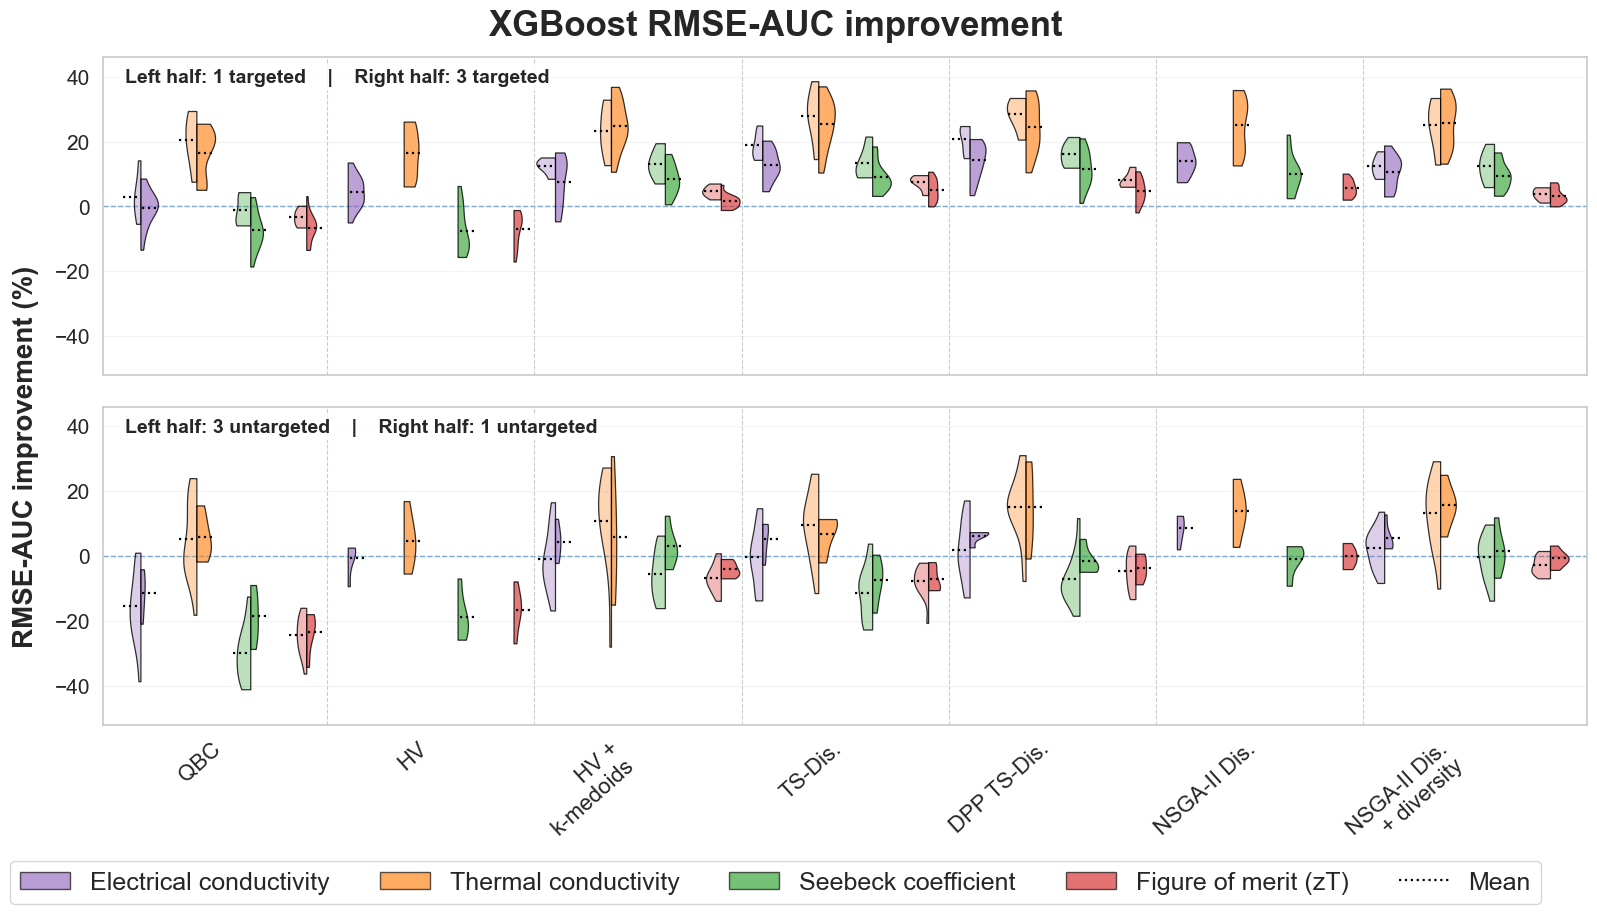


Saved figure:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\ThermoElectricNew3\WITH_MODIFICATIONS\plots\Property_Mean_Direct_From_AL\property_split_violins_direct_from_AL_xgb_two_panels_sns_property_spacing_fixed.png

Saved DIRECT per-seed/case raw observations:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\ThermoElectricNew3\WITH_MODIFICATIONS\plots\Property_Mean_Direct_From_AL\property_seed_improvements_direct_from_AL.csv

Saved DIRECT mean/std/count statistics:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\ThermoElectricNew3\WITH_MODIFICATIONS\plots\Property_Mean_Direct_From_AL\property_mean_std_count_direct_from_AL.csv


In [15]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
# Configuration
BASE_ROOT = Path(
    r"C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES"
    r"\PhD Toronto\DatasetGeneration\Better_Acqsition\ThermoElectricNew3"
    r"\WITH_MODIFICATIONS"
)
DATA_ROOT = BASE_ROOT / "al"
OUTPUT_ROOT = BASE_ROOT / "plots" / "Property_Mean_Direct_From_AL"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
OUTPUT_FIGURE = OUTPUT_ROOT / "property_split_violins_direct_from_AL_xgb_two_panels_sns_property_spacing_fixed.png"
OUTPUT_RAW_CASES = OUTPUT_ROOT / "property_seed_improvements_direct_from_AL.csv"
OUTPUT_STATS = OUTPUT_ROOT / "property_mean_std_count_direct_from_AL.csv"
SEEDS = range(5)
MODELS = {"rf": "Random Forest", "xgb": "XGBoost"}
# Properties and raw RMSE columns
RMSE_METRICS = {
    "rmse_elec_cond": "Electrical conductivity",
    "rmse_k_total": "Thermal conductivity",
    "rmse_seebeck": "Seebeck coefficient",
    "rmse_zt": "Figure of merit (zT)",
}
PROPERTY_ID_BY_METRIC = {
    "rmse_elec_cond": "electric_cond",
    "rmse_k_total": "thermal_cond",
    "rmse_seebeck": "seebeck_coef",
    "rmse_zt": "zT",
}
PROPERTY_ORDER = [
    "Electrical conductivity",
    "Thermal conductivity",
    "Seebeck coefficient",
    "Figure of merit (zT)",
]
PROPERTY_COLORS = {
    "Electrical conductivity": "#9467bd",
    "Thermal conductivity": "#ff7f0e",
    "Seebeck coefficient": "#2ca02c",
    "Figure of merit (zT)": "#d62728",
}
PROPERTY_X_OFFSETS = {
    "Electrical conductivity": -0.40,
    "Thermal conductivity": -0.13,
    "Seebeck coefficient": +0.13,
    "Figure of merit (zT)": +0.40,
}
VIOLIN_WIDTH = 0.18
# Cases and policy labels
AXIS_ORDER = [
    "1 targeted",
    "3 untargeted",
    "3 targeted",
    "1 untargeted",
]
POLICY_ORDER = [
    "QBC",
    "HV",
    "HV + k-medoids",
    "TS-QBC",
    "DPP-TS-QBC",
    "NSGA-II QBC",
    "NSGA-II QBC + diversity",
]
DISPLAY_POLICY_LABELS = {
    "QBC": "QBC",
    "HV": "HV",
    "HV + k-medoids": "HV +\nk-medoids",
    "TS-QBC": "TS-Dis.",
    "DPP-TS-QBC": "DPP TS-Dis.",
    "NSGA-II QBC": "NSGA-II Dis.",
    "NSGA-II QBC + diversity": "NSGA-II Dis.\n+ diversity",
}
# One-target campaigns
ONE_TARGET_SETS = {
    "electric_cond": {
        "prefix": "ThermoEl_electric_cond",
        "targeted": {"electric_cond"},
    },
    "seebeck_coef": {
        "prefix": "ThermoEl_seebeck_coef",
        "targeted": {"seebeck_coef"},
    },
    "zT": {
        "prefix": "ThermoEl_zT",
        "targeted": {"zT"},
    },
    "thermal_cond": {
        "prefix": "ThermoEl_thermal_cond",
        "targeted": {"thermal_cond"},
    },
}
ONE_TARGET_POLICIES = {
    "QBC": (
        "grow_QBC",
        "growing_QBC",
    ),
    "HV + k-medoids": (
        "grow_disagreementHV_topM_kmedoids_OneTarget",
        "growing_1HV_k",
    ),
    "DPP-TS-QBC": (
        "grow_DPP_TS_QBC_OneTarget",
        "growing_DPP_TS_QBC_1target",
    ),
    "NSGA-II QBC + diversity": (
        "grow_EA_DeltaDiversity",
        "growing_EA_1out_div",
    ),
    "TS-QBC": (
        "grow_TS_QBC_no_diversity_OneTarget",
        "growing_TS_nodiv_1target",
    ),
}
# Three-target campaigns, including HV and NSGA-II Dis.
THREE_TARGET_SETS = {
    "el_seeb_zT": {
        "prefix": "ThermoEl_el_seeb_zT",
        "targeted": {"electric_cond", "seebeck_coef", "zT"},
    },
    "el_seeb_ThC": {
        "prefix": "ThermoEl_el_seeb_ThC",
        "targeted": {"electric_cond", "seebeck_coef", "thermal_cond"},
    },
    "el_zT_ThC": {
        "prefix": "ThermoEl_el_zT_ThC",
        "targeted": {"electric_cond", "zT", "thermal_cond"},
    },
    "seeb_zT_ThC": {
        "prefix": "ThermoEl_seeb_zT_ThC",
        "targeted": {"seebeck_coef", "zT", "thermal_cond"},
    },
}
THREE_TARGET_POLICIES = {
    "QBC": (
        "grow_3QBC",
        "growing_3QBC",
    ),
    "HV": (
        "grow_disagreementHV_no_diversity_ThreeTargets",
        "growing_HV_nodiv_3targets",
    ),
    "HV + k-medoids": (
        "grow_disagreementHV_topM_kmedoids_ThreeTargets",
        "growing_3HV_k",
    ),
    "TS-QBC": (
        "grow_TS_QBC_no_diversity_ThreeTargets",
        "growing_TS_nodiv_3targets",
    ),
    "DPP-TS-QBC": (
        "grow_DPP_TS_QBC_ThreeTargets",
        "growing_DPP_TS_QBC_3targets",
    ),
    "NSGA-II QBC": (
        "grow_EA_3Obj_ThreeTargets_QBC_ONLY",
        "growing_EA_3obj_qbc_only",
    ),
    "NSGA-II QBC + diversity": (
        "grow_EA_4Obj_ThreeTargets",
        "growing_EA_3out_div",
    ),
}
# Raw-file helpers
def random_path(model, seed):
    return (
        DATA_ROOT
        / "grow_random"
        / "ThermoEl"
        / "all"
        / str(seed)
        / f"ThermoEl_all_random_{model}{seed}.csv"
    )
def policy_path(folder, target_folder, target_prefix, suffix, model, seed):
    return (
        DATA_ROOT
        / folder
        / "ThermoEl"
        / target_folder
        / str(seed)
        / f"{target_prefix}{suffix}_{model}{seed}.csv"
    )
def normalized_rmse_auc_from_file(path, metric):
    if not path.exists():
        return None
    df = pd.read_csv(path)
    if "train_ratio" not in df.columns:
        print(f"WARNING: 'train_ratio' missing: {path}")
        return None
    if metric not in df.columns:
        print(f"WARNING: '{metric}' missing: {path}")
        return None
    curve = df[["train_ratio", metric]].copy()
    curve["train_ratio"] = pd.to_numeric(curve["train_ratio"], errors="coerce")
    curve[metric] = pd.to_numeric(curve[metric], errors="coerce")
    curve = (
        curve.dropna()
        .groupby("train_ratio", as_index=False)[metric]
        .mean()
        .sort_values("train_ratio")
    )
    if len(curve) < 2:
        print(f"WARNING: fewer than 2 valid AL iterations: {path} | {metric}")
        return None
    x = 100.0 * curve["train_ratio"].to_numpy(dtype=float)
    y = curve[metric].to_numpy(dtype=float)
    width = x[-1] - x[0]
    if width <= 0:
        print(f"WARNING: invalid AL interval: {path} | {metric}")
        return None
    if hasattr(np, "trapezoid"):
        area = np.trapezoid(y, x)
    else:
        area = np.trapz(y, x)
    return {
        "rmse_auc": float(area / width),
        "first_train_percent": float(x[0]),
        "last_train_percent": float(x[-1]),
        "n_iterations": int(len(curve)),
    }
# Direct per-seed improvements from raw AL files
def collect_raw_improvements():
    rows = []
    settings = [
        (1, ONE_TARGET_SETS, ONE_TARGET_POLICIES),
        (3, THREE_TARGET_SETS, THREE_TARGET_POLICIES),
    ]
    missing_policy_files = 0
    missing_random_files = 0
    for model in MODELS:
        for n_targets, target_sets, policies in settings:
            for target_folder, target_info in target_sets.items():
                target_prefix = target_info["prefix"]
                targeted_properties = target_info["targeted"]
                for seed in SEEDS:
                    rand_path = random_path(model, seed)
                    if not rand_path.exists():
                        missing_random_files += 1
                        print(f"WARNING: missing Random raw file: {rand_path}")
                        continue
                    random_auc = {
                        metric: normalized_rmse_auc_from_file(rand_path, metric)
                        for metric in RMSE_METRICS
                    }
                    for policy in POLICY_ORDER:
                        if policy not in policies:
                            continue
                        folder, suffix = policies[policy]
                        pol_path = policy_path(
                            folder=folder,
                            target_folder=target_folder,
                            target_prefix=target_prefix,
                            suffix=suffix,
                            model=model,
                            seed=seed,
                        )
                        if not pol_path.exists():
                            missing_policy_files += 1
                            print(f"WARNING: missing policy raw file: {pol_path}")
                            continue
                        for metric, property_name in RMSE_METRICS.items():
                            property_id = PROPERTY_ID_BY_METRIC[metric]
                            case_type = (
                                "targeted"
                                if property_id in targeted_properties
                                else "untargeted"
                            )
                            if n_targets == 1:
                                axis_name = (
                                    "1 targeted"
                                    if case_type == "targeted"
                                    else "3 untargeted"
                                )
                            else:
                                axis_name = (
                                    "3 targeted"
                                    if case_type == "targeted"
                                    else "1 untargeted"
                                )
                            pol_auc = normalized_rmse_auc_from_file(pol_path, metric)
                            rand_auc = random_auc[metric]
                            if pol_auc is None or rand_auc is None:
                                continue
                            if rand_auc["rmse_auc"] == 0:
                                print(
                                    "WARNING: Random RMSE-AUC is zero; skipping: "
                                    f"model={model}, seed={seed}, metric={metric}"
                                )
                                continue
                            improvement_percent = 100.0 * (
                                1.0 - pol_auc["rmse_auc"] / rand_auc["rmse_auc"]
                            )
                            rows.append({
                                "model": model,
                                "model_name": MODELS[model],
                                "n_targets": n_targets,
                                "axis": axis_name,
                                "case_type": case_type,
                                "target_case": target_folder,
                                "policy": policy,
                                "seed": seed,
                                "metric": metric,
                                "property_id": property_id,
                                "property_name": property_name,
                                "improvement_percent": improvement_percent,
                                "policy_rmse_auc": pol_auc["rmse_auc"],
                                "random_rmse_auc": rand_auc["rmse_auc"],
                                "policy_file": str(pol_path),
                                "random_file": str(rand_path),
                            })
    print("\n================ RAW AL FILE DIAGNOSTIC ================")
    print(f"Missing policy files encountered: {missing_policy_files}")
    print(f"Missing Random files encountered: {missing_random_files}")
    raw_df = pd.DataFrame(rows)
    if raw_df.empty:
        raise RuntimeError(
            "No raw AL observations were loaded. Check DATA_ROOT and raw filenames."
        )
    return raw_df
# Direct mean, standard deviation, and count
def summarize_raw_improvements(raw_df):
    stats_df = (
        raw_df.groupby(
            [
                "model",
                "model_name",
                "axis",
                "n_targets",
                "case_type",
                "policy",
                "property_id",
                "property_name",
            ],
            as_index=False,
        )["improvement_percent"]
        .agg(
            mean_percent="mean",
            std_percent="std",
            count="count",
        )
    )
    print("\n================ DIRECT RAW-AL STATISTICS ================")
    for row in stats_df.itertuples(index=False):
        std_text = "NaN" if pd.isna(row.std_percent) else f"{row.std_percent:.4f}"
        display_policy = DISPLAY_POLICY_LABELS[row.policy].replace("\n", " ")
        print(
            f"{row.model:>3} | {row.axis:<14} | {display_policy:<27} | "
            f"{row.property_name:<26} | mean={row.mean_percent:8.4f} | "
            f"std={std_text:>8} | count={int(row.count):2d}"
        )
        if row.count < 2 or pd.isna(row.std_percent):
            print(
                "  WARNING: standard deviation cannot be estimated reliably "
                f"because count={int(row.count)}."
            )
    return stats_df
raw_df = collect_raw_improvements()
raw_df.to_csv(OUTPUT_RAW_CASES, index=False)
stats_df = summarize_raw_improvements(raw_df)
stats_df.to_csv(OUTPUT_STATS, index=False)
# Automatic y limits from direct raw observations
def calculate_case_y_limits(raw_df, padding_fraction=0.12, minimum_padding=2.0):
    limits = {}
    for axis_name in AXIS_ORDER:
        subset = raw_df.loc[raw_df["axis"] == axis_name]
        values = pd.to_numeric(subset["improvement_percent"], errors="coerce")
        values = values[np.isfinite(values)]
        if len(values) == 0:
            limits[axis_name] = (-1, 1)
            continue
        data_min = float(values.min())
        data_max = float(values.max())
        span = max(data_max - data_min, 1.0)
        padding = max(minimum_padding, padding_fraction * span)
        y_min = min(int(np.floor(data_min - padding)), 0)
        y_max = max(int(np.ceil(data_max + padding)), 0)
        if y_min == y_max:
            y_min -= 1
            y_max += 1
        limits[axis_name] = (y_min, y_max)
    return limits
CASE_Y_LIMITS = calculate_case_y_limits(raw_df)
all_values = pd.to_numeric(raw_df["improvement_percent"], errors="coerce")
all_values = all_values[np.isfinite(all_values)]
if len(all_values) == 0:
    GLOBAL_Y_LIM = (-1, 1)
else:
    global_min = float(all_values.min())
    global_max = float(all_values.max())
    global_span = max(global_max - global_min, 1.0)
    global_padding = max(1.0, 0.08 * global_span)
    y_min = min(int(np.floor(global_min - global_padding)), 0)
    y_max = max(int(np.ceil(global_max + global_padding)), 0)
    if y_min == y_max:
        y_min -= 1
        y_max += 1
    GLOBAL_Y_LIM = (y_min, y_max)
print("\n================ PANEL Y LIMITS ================")
for axis_name in AXIS_ORDER:
    print(f"{axis_name}: {CASE_Y_LIMITS[axis_name]}")
print(f"Common y scale used for all panels: {GLOBAL_Y_LIM}")
# XGBoost panels
# Top: left half = 1 targeted; right half = 3 targeted
# Bottom: left half = 3 untargeted; right half = 1 untargeted
PANEL_SPECS = [
    {
        "left_axis": "1 targeted",
        "right_axis": "3 targeted",
        "title": "Left half: 1 targeted    |    Right half: 3 targeted",
    },
    {
        "left_axis": "3 untargeted",
        "right_axis": "1 untargeted",
        "title": "Left half: 3 untargeted    |    Right half: 1 untargeted",
    },
]
def shift_new_violin_bodies(ax, start_collection_idx, x_offset):
    for coll in ax.collections[start_collection_idx:]:
        if not hasattr(coll, "get_paths"):
            continue
        for path in coll.get_paths():
            path.vertices[:, 0] += x_offset
def draw_half_mean_line(ax, values, position, width, side):
    if len(values) == 0:
        return
    mean_val = float(np.mean(values))
    half_pad = 0.01
    half_extent = 0.46 * width
    if side == "left":
        x0 = position - half_extent
        x1 = position - half_pad
    else:
        x0 = position + half_pad
        x1 = position + half_extent
    ax.hlines(
        mean_val,
        x0,
        x1,
        colors="black",
        linewidth=1.6,
        linestyles=":",
        zorder=4,
    )
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(16.4, 9.6),
    sharex=False,
    sharey=True,
)
model = "xgb"
panel_df_all = raw_df.loc[raw_df["model"] == model].copy()
common_y_min, common_y_max = GLOBAL_Y_LIM
common_policy_order = POLICY_ORDER
x_positions = np.arange(len(common_policy_order), dtype=float)
for row_index, panel_spec in enumerate(PANEL_SPECS):
    ax = axes[row_index]
    left_axis = panel_spec["left_axis"]
    right_axis = panel_spec["right_axis"]
    left_df = panel_df_all.loc[panel_df_all["axis"] == left_axis].copy()
    right_df = panel_df_all.loc[panel_df_all["axis"] == right_axis].copy()
    for property_name in PROPERTY_ORDER:
        color = PROPERTY_COLORS.get(property_name, "gray")
        left_prop_df = left_df.loc[
            left_df["property_name"] == property_name,
            ["policy", "improvement_percent"],
        ].copy()
        right_prop_df = right_df.loc[
            right_df["property_name"] == property_name,
            ["policy", "improvement_percent"],
        ].copy()
        left_prop_df["comparison_case"] = "left"
        right_prop_df["comparison_case"] = "right"
        prop_df = pd.concat(
            [left_prop_df, right_prop_df],
            ignore_index=True,
        )
        prop_df["policy"] = pd.Categorical(
            prop_df["policy"],
            categories=common_policy_order,
            ordered=True,
        )
        prop_df["comparison_case"] = pd.Categorical(
            prop_df["comparison_case"],
            categories=["left", "right"],
            ordered=True,
        )
        prop_df["improvement_percent"] = pd.to_numeric(
            prop_df["improvement_percent"], errors="coerce"
        )
        prop_df = prop_df.dropna(subset=["improvement_percent"])
        if prop_df.empty:
            print(
                "WARNING: no raw observations available for "
                f"property={property_name}, "
                f"left_axis={left_axis}, right_axis={right_axis}"
            )
            continue
        start_idx = len(ax.collections)
        sns.violinplot(
            data=prop_df,
            x="policy",
            y="improvement_percent",
            hue="comparison_case",
            order=common_policy_order,
            hue_order=["left", "right"],
            split=True,
            inner=None,
            cut=0,
            bw_adjust=1.0,
            gridsize=200,
            linewidth=1.0,
            saturation=1.0,
            palette={"left": color, "right": color},
            width=VIOLIN_WIDTH,
            ax=ax,
        )
        shift_new_violin_bodies(
            ax, start_idx, PROPERTY_X_OFFSETS[property_name]
        )
        # Keep the same property RGB color; vary transparency by half
        new_collections = ax.collections[start_idx:]
        property_rgb = mcolors.to_rgb(color)
        expected_centers = x_positions + PROPERTY_X_OFFSETS[property_name]
        for coll in new_collections:
            try:
                paths = coll.get_paths()
                if not paths:
                    continue
                verts = paths[0].vertices
                x_mean = float(np.mean(verts[:, 0]))
                nearest_center = float(
                    expected_centers[
                        np.argmin(np.abs(expected_centers - x_mean))
                    ]
                )
                if x_mean < nearest_center:
                    face_rgba = (*property_rgb, 0.32)
                else:
                    face_rgba = (*property_rgb, 0.62)
                coll.set_alpha(None)
                coll.set_facecolor([face_rgba])
                coll.set_edgecolor((*mcolors.to_rgb("black"), 0.80))
                coll.set_linewidth(0.9)
            except Exception as exc:
                print(
                    f"WARNING: could not style violin half for {property_name}: {exc}"
                )
        if ax.get_legend() is not None:
            ax.get_legend().remove()
        # Mean lines for each available half
        for x, policy in zip(x_positions, common_policy_order):
            left_values = pd.to_numeric(
                left_df.loc[
                    (left_df["policy"] == policy)
                    & (left_df["property_name"] == property_name),
                    "improvement_percent",
                ],
                errors="coerce",
            )
            left_values = left_values[
                np.isfinite(left_values)
            ].to_numpy(dtype=float)
            right_values = pd.to_numeric(
                right_df.loc[
                    (right_df["policy"] == policy)
                    & (right_df["property_name"] == property_name),
                    "improvement_percent",
                ],
                errors="coerce",
            )
            right_values = right_values[
                np.isfinite(right_values)
            ].to_numpy(dtype=float)
            x_plot = x + PROPERTY_X_OFFSETS[property_name]
            if len(left_values) > 0:
                draw_half_mean_line(
                    ax=ax,
                    values=left_values,
                    position=x_plot,
                    width=VIOLIN_WIDTH,
                    side="left",
                )
            if len(right_values) > 0:
                draw_half_mean_line(
                    ax=ax,
                    values=right_values,
                    position=x_plot,
                    width=VIOLIN_WIDTH,
                    side="right",
                )
    ax.set_ylim(common_y_min, common_y_max)
    ax.set_xlim(-0.58, len(common_policy_order) - 0.42)
    ax.set_xticks(x_positions)
    if row_index == 0:
        ax.set_xticklabels([])
        ax.tick_params(axis="x", which="both", labelbottom=False)
    else:
        ax.set_xticklabels(
            [DISPLAY_POLICY_LABELS[p] for p in common_policy_order],
            fontsize=16.0,
            rotation=42,
            ha="right",
        )
        ax.tick_params(axis="x", which="both", labelbottom=True)
    ax.grid(axis="y", alpha=0.20)
    ax.axhline(
        0.0,
        color="#5b9bd5",
        linewidth=1.0,
        linestyle="--",
        alpha=0.90,
        zorder=0,
    )
    for separator_x in np.arange(len(common_policy_order) - 1, dtype=float) + 0.5:
        ax.axvline(
            separator_x,
            color="0.55",
            linewidth=0.8,
            linestyle="--",
            alpha=0.45,
            zorder=0,
        )
    y_range = common_y_max - common_y_min
    if y_range <= 8:
        tick_step = 2
    elif y_range <= 16:
        tick_step = 4
    elif y_range <= 30:
        tick_step = 5
    elif y_range <= 50:
        tick_step = 10
    else:
        tick_step = 20
    first_tick = int(np.ceil(common_y_min / tick_step) * tick_step)
    last_tick = int(np.floor(common_y_max / tick_step) * tick_step)
    yticks = np.arange(first_tick, last_tick + tick_step, tick_step, dtype=int)
    if common_y_min <= 0 <= common_y_max and 0 not in yticks:
        yticks = np.sort(np.append(yticks, 0))
    ax.tick_params(axis="y", labelsize=15)
    ax.set_yticks(yticks)
    ax.text(
        0.015,
        0.965,
        panel_spec["title"],
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=14,
        fontweight="bold",
        bbox=dict(
            boxstyle="round,pad=0.22",
            facecolor="white",
            edgecolor="none",
            alpha=0.82,
        ),
    )
    ax.set_ylabel("")
    ax.set_xlabel("")
fig.suptitle(
    "XGBoost RMSE-AUC improvement",
    fontsize=25,
    fontweight="bold",
    y=0.965,
)
fig.supylabel(
    "RMSE-AUC improvement (%)",
    fontsize=20,
    fontweight="bold",
    x=0.035,
)
property_handles = [
    Patch(
        facecolor=PROPERTY_COLORS[property_name],
        edgecolor="black",
        alpha=0.65,
        label=property_name,
    )
    for property_name in PROPERTY_ORDER
]
property_handles += [
    Line2D(
        [0],
        [0],
        color="black",
        linewidth=1.6,
        linestyle=":",
        label="Mean",
    ),
]
fig.legend(
    handles=property_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.02),
    ncol=5,
    fontsize=18,
    frameon=True,
)
plt.subplots_adjust(
    left=0.09,
    right=0.995,
    top=0.915,
    bottom=0.22,
    hspace=0.10,
)
fig.savefig(OUTPUT_FIGURE, dpi=250, bbox_inches="tight")
plt.show()
plt.close(fig)
print("\nSaved figure:")
print(OUTPUT_FIGURE)
print("\nSaved DIRECT per-seed/case raw observations:")
print(OUTPUT_RAW_CASES)
print("\nSaved DIRECT mean/std/count statistics:")
print(OUTPUT_STATS)


================ RANDOM FOREST RAW FILE DIAGNOSTIC ================
Missing policy files encountered: 0
Missing Random files encountered: 0

================ DIRECT RANDOM FOREST STATISTICS ================
 rf | 1 targeted     | DPP TS-Dis.                 | Electrical conductivity    | mean= 20.1376 | std=  4.5582 | count= 5
 rf | 1 targeted     | DPP TS-Dis.                 | Seebeck coefficient        | mean= 16.8872 | std=  2.6857 | count= 5
 rf | 1 targeted     | DPP TS-Dis.                 | Thermal conductivity       | mean= 19.0353 | std=  3.9280 | count= 5
 rf | 1 targeted     | DPP TS-Dis.                 | Figure of merit (zT)       | mean= 11.8106 | std=  3.5299 | count= 5
 rf | 1 targeted     | HV + k-medoids              | Electrical conductivity    | mean= 13.0904 | std=  2.8804 | count= 5
 rf | 1 targeted     | HV + k-medoids              | Seebeck coefficient        | mean= 13.6906 | std=  3.2151 | count= 5
 rf | 1 targeted     | HV + k-medoids              | Thermal

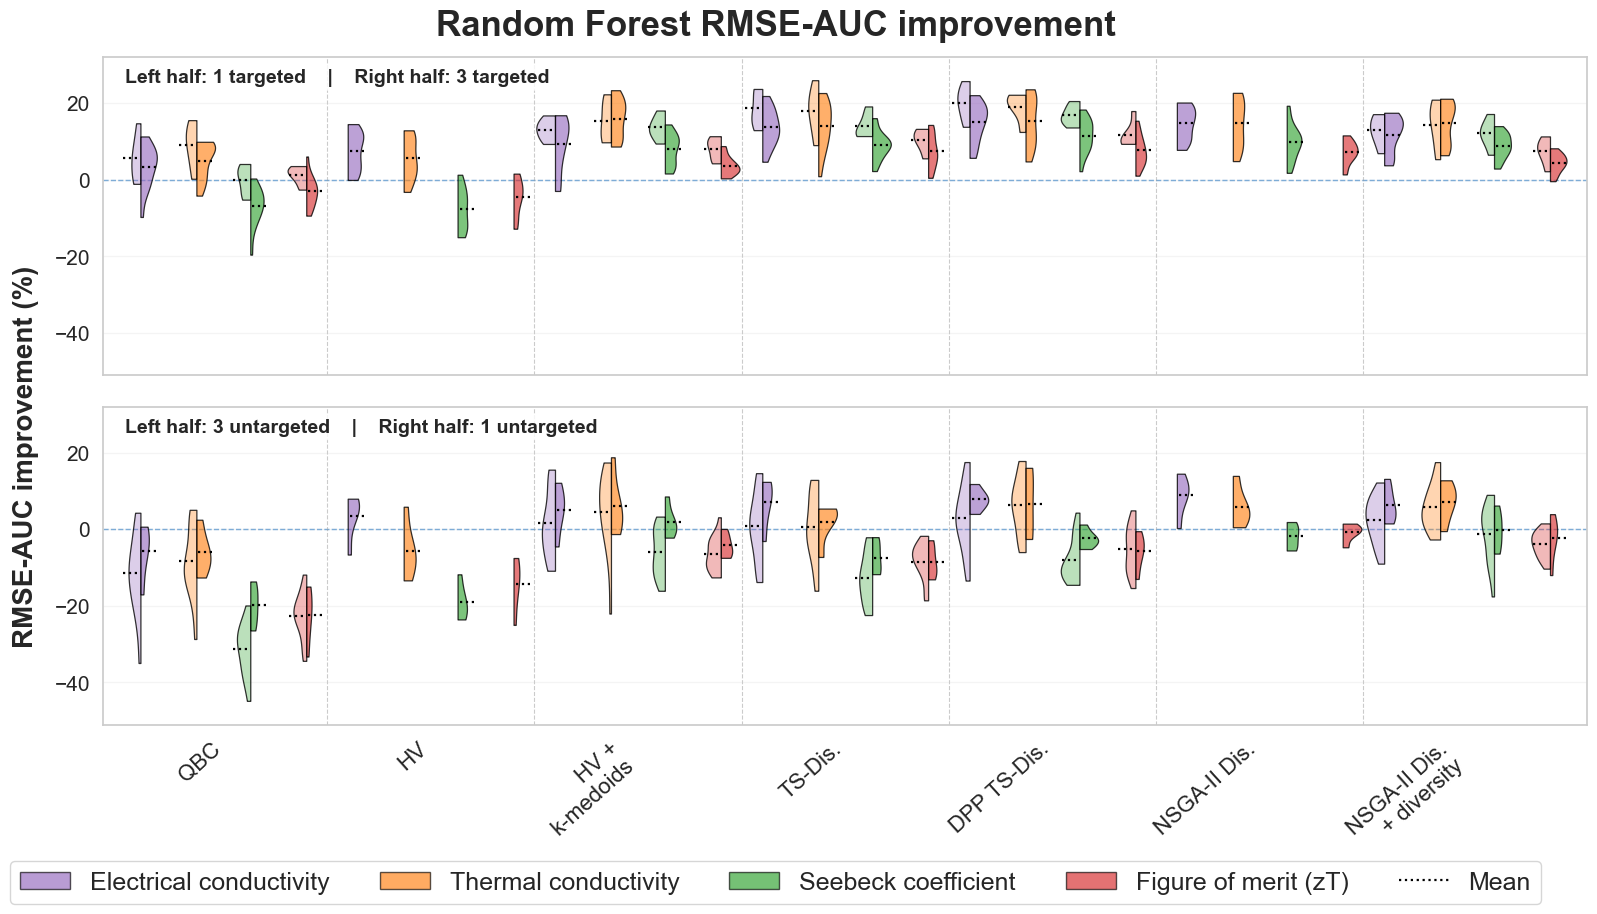


Saved Random Forest figure:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\ThermoElectricNew3\WITH_MODIFICATIONS\plots\Property_Mean_Direct_From_AL\property_split_violins_direct_from_AL_rf_two_panels_sns_property_spacing_fixed.png

Saved Random Forest per-seed/case raw observations:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\ThermoElectricNew3\WITH_MODIFICATIONS\plots\Property_Mean_Direct_From_AL\property_seed_improvements_direct_from_AL_rf.csv

Saved Random Forest mean/std/count statistics:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\ThermoElectricNew3\WITH_MODIFICATIONS\plots\Property_Mean_Direct_From_AL\property_mean_std_count_direct_from_AL_rf.csv


In [16]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
# Configuration
BASE_ROOT = Path(
    r"C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES"
    r"\PhD Toronto\DatasetGeneration\Better_Acqsition\ThermoElectricNew3"
    r"\WITH_MODIFICATIONS"
)
DATA_ROOT = BASE_ROOT / "al"
OUTPUT_ROOT = BASE_ROOT / "plots" / "Property_Mean_Direct_From_AL"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
MODEL = "rf"
MODEL_NAME = "Random Forest"
OUTPUT_FIGURE = OUTPUT_ROOT / "property_split_violins_direct_from_AL_rf_two_panels_sns_property_spacing_fixed.png"
OUTPUT_RAW_CASES = OUTPUT_ROOT / "property_seed_improvements_direct_from_AL_rf.csv"
OUTPUT_STATS = OUTPUT_ROOT / "property_mean_std_count_direct_from_AL_rf.csv"
SEEDS = range(5)
# Properties and raw RMSE columns
RMSE_METRICS = {
    "rmse_elec_cond": "Electrical conductivity",
    "rmse_k_total": "Thermal conductivity",
    "rmse_seebeck": "Seebeck coefficient",
    "rmse_zt": "Figure of merit (zT)",
}
PROPERTY_ID_BY_METRIC = {
    "rmse_elec_cond": "electric_cond",
    "rmse_k_total": "thermal_cond",
    "rmse_seebeck": "seebeck_coef",
    "rmse_zt": "zT",
}
PROPERTY_ORDER = [
    "Electrical conductivity",
    "Thermal conductivity",
    "Seebeck coefficient",
    "Figure of merit (zT)",
]
PROPERTY_COLORS = {
    "Electrical conductivity": "#9467bd",
    "Thermal conductivity": "#ff7f0e",
    "Seebeck coefficient": "#2ca02c",
    "Figure of merit (zT)": "#d62728",
}
PROPERTY_X_OFFSETS = {
    "Electrical conductivity": -0.40,
    "Thermal conductivity": -0.13,
    "Seebeck coefficient": +0.13,
    "Figure of merit (zT)": +0.40,
}
VIOLIN_WIDTH = 0.18
# Cases and policy labels
AXIS_ORDER = [
    "1 targeted",
    "3 untargeted",
    "3 targeted",
    "1 untargeted",
]
POLICY_ORDER = [
    "QBC",
    "HV",
    "HV + k-medoids",
    "TS-QBC",
    "DPP-TS-QBC",
    "NSGA-II QBC",
    "NSGA-II QBC + diversity",
]
DISPLAY_POLICY_LABELS = {
    "QBC": "QBC",
    "HV": "HV",
    "HV + k-medoids": "HV +\nk-medoids",
    "TS-QBC": "TS-Dis.",
    "DPP-TS-QBC": "DPP TS-Dis.",
    "NSGA-II QBC": "NSGA-II Dis.",
    "NSGA-II QBC + diversity": "NSGA-II Dis.\n+ diversity",
}
# One-target campaigns
ONE_TARGET_SETS = {
    "electric_cond": {
        "prefix": "ThermoEl_electric_cond",
        "targeted": {"electric_cond"},
    },
    "seebeck_coef": {
        "prefix": "ThermoEl_seebeck_coef",
        "targeted": {"seebeck_coef"},
    },
    "zT": {
        "prefix": "ThermoEl_zT",
        "targeted": {"zT"},
    },
    "thermal_cond": {
        "prefix": "ThermoEl_thermal_cond",
        "targeted": {"thermal_cond"},
    },
}
ONE_TARGET_POLICIES = {
    "QBC": (
        "grow_QBC",
        "growing_QBC",
    ),
    "HV + k-medoids": (
        "grow_disagreementHV_topM_kmedoids_OneTarget",
        "growing_1HV_k",
    ),
    "DPP-TS-QBC": (
        "grow_DPP_TS_QBC_OneTarget",
        "growing_DPP_TS_QBC_1target",
    ),
    "NSGA-II QBC + diversity": (
        "grow_EA_DeltaDiversity",
        "growing_EA_1out_div",
    ),
    "TS-QBC": (
        "grow_TS_QBC_no_diversity_OneTarget",
        "growing_TS_nodiv_1target",
    ),
}
# Three-target campaigns
THREE_TARGET_SETS = {
    "el_seeb_zT": {
        "prefix": "ThermoEl_el_seeb_zT",
        "targeted": {"electric_cond", "seebeck_coef", "zT"},
    },
    "el_seeb_ThC": {
        "prefix": "ThermoEl_el_seeb_ThC",
        "targeted": {"electric_cond", "seebeck_coef", "thermal_cond"},
    },
    "el_zT_ThC": {
        "prefix": "ThermoEl_el_zT_ThC",
        "targeted": {"electric_cond", "zT", "thermal_cond"},
    },
    "seeb_zT_ThC": {
        "prefix": "ThermoEl_seeb_zT_ThC",
        "targeted": {"seebeck_coef", "zT", "thermal_cond"},
    },
}
THREE_TARGET_POLICIES = {
    "QBC": (
        "grow_3QBC",
        "growing_3QBC",
    ),
    "HV": (
        "grow_disagreementHV_no_diversity_ThreeTargets",
        "growing_HV_nodiv_3targets",
    ),
    "HV + k-medoids": (
        "grow_disagreementHV_topM_kmedoids_ThreeTargets",
        "growing_3HV_k",
    ),
    "TS-QBC": (
        "grow_TS_QBC_no_diversity_ThreeTargets",
        "growing_TS_nodiv_3targets",
    ),
    "DPP-TS-QBC": (
        "grow_DPP_TS_QBC_ThreeTargets",
        "growing_DPP_TS_QBC_3targets",
    ),
    "NSGA-II QBC": (
        "grow_EA_3Obj_ThreeTargets_QBC_ONLY",
        "growing_EA_3obj_qbc_only",
    ),
    "NSGA-II QBC + diversity": (
        "grow_EA_4Obj_ThreeTargets",
        "growing_EA_3out_div",
    ),
}
# Raw-file helpers
def random_path(model, seed):
    return (
        DATA_ROOT
        / "grow_random"
        / "ThermoEl"
        / "all"
        / str(seed)
        / f"ThermoEl_all_random_{model}{seed}.csv"
    )
def policy_path(folder, target_folder, target_prefix, suffix, model, seed):
    return (
        DATA_ROOT
        / folder
        / "ThermoEl"
        / target_folder
        / str(seed)
        / f"{target_prefix}{suffix}_{model}{seed}.csv"
    )
def normalized_rmse_auc_from_file(path, metric):
    if not path.exists():
        return None
    df = pd.read_csv(path)
    if "train_ratio" not in df.columns:
        print(f"WARNING: 'train_ratio' missing: {path}")
        return None
    if metric not in df.columns:
        print(f"WARNING: '{metric}' missing: {path}")
        return None
    curve = df[["train_ratio", metric]].copy()
    curve["train_ratio"] = pd.to_numeric(curve["train_ratio"], errors="coerce")
    curve[metric] = pd.to_numeric(curve[metric], errors="coerce")
    curve = (
        curve.dropna()
        .groupby("train_ratio", as_index=False)[metric]
        .mean()
        .sort_values("train_ratio")
    )
    if len(curve) < 2:
        print(f"WARNING: fewer than 2 valid AL iterations: {path} | {metric}")
        return None
    x = 100.0 * curve["train_ratio"].to_numpy(dtype=float)
    y = curve[metric].to_numpy(dtype=float)
    width = x[-1] - x[0]
    if width <= 0:
        print(f"WARNING: invalid AL interval: {path} | {metric}")
        return None
    if hasattr(np, "trapezoid"):
        area = np.trapezoid(y, x)
    else:
        area = np.trapz(y, x)
    return {
        "rmse_auc": float(area / width),
        "first_train_percent": float(x[0]),
        "last_train_percent": float(x[-1]),
        "n_iterations": int(len(curve)),
    }
# Calculate Random Forest improvements only
def collect_raw_improvements():
    rows = []
    settings = [
        (1, ONE_TARGET_SETS, ONE_TARGET_POLICIES),
        (3, THREE_TARGET_SETS, THREE_TARGET_POLICIES),
    ]
    missing_policy_files = 0
    missing_random_files = 0
    random_auc_cache = {}
    for seed in SEEDS:
        rand_path = random_path(MODEL, seed)
        if not rand_path.exists():
            missing_random_files += 1
            print(f"WARNING: missing Random raw file: {rand_path}")
            continue
        random_auc_cache[seed] = {
            metric: normalized_rmse_auc_from_file(rand_path, metric)
            for metric in RMSE_METRICS
        }
    for n_targets, target_sets, policies in settings:
        for target_folder, target_info in target_sets.items():
            target_prefix = target_info["prefix"]
            targeted_properties = target_info["targeted"]
            for seed in SEEDS:
                if seed not in random_auc_cache:
                    continue
                rand_path = random_path(MODEL, seed)
                random_auc = random_auc_cache[seed]
                for policy in POLICY_ORDER:
                    if policy not in policies:
                        continue
                    folder, suffix = policies[policy]
                    pol_path = policy_path(
                        folder=folder,
                        target_folder=target_folder,
                        target_prefix=target_prefix,
                        suffix=suffix,
                        model=MODEL,
                        seed=seed,
                    )
                    if not pol_path.exists():
                        missing_policy_files += 1
                        print(f"WARNING: missing policy raw file: {pol_path}")
                        continue
                    for metric, property_name in RMSE_METRICS.items():
                        property_id = PROPERTY_ID_BY_METRIC[metric]
                        case_type = (
                            "targeted"
                            if property_id in targeted_properties
                            else "untargeted"
                        )
                        if n_targets == 1:
                            axis_name = (
                                "1 targeted"
                                if case_type == "targeted"
                                else "3 untargeted"
                            )
                        else:
                            axis_name = (
                                "3 targeted"
                                if case_type == "targeted"
                                else "1 untargeted"
                            )
                        pol_auc = normalized_rmse_auc_from_file(pol_path, metric)
                        rand_auc = random_auc[metric]
                        if pol_auc is None or rand_auc is None:
                            continue
                        if rand_auc["rmse_auc"] == 0:
                            print(
                                "WARNING: Random RMSE-AUC is zero; skipping: "
                                f"model={MODEL}, seed={seed}, metric={metric}"
                            )
                            continue
                        improvement_percent = 100.0 * (
                            1.0 - pol_auc["rmse_auc"] / rand_auc["rmse_auc"]
                        )
                        rows.append({
                            "model": MODEL,
                            "model_name": MODEL_NAME,
                            "n_targets": n_targets,
                            "axis": axis_name,
                            "case_type": case_type,
                            "target_case": target_folder,
                            "policy": policy,
                            "seed": seed,
                            "metric": metric,
                            "property_id": property_id,
                            "property_name": property_name,
                            "improvement_percent": improvement_percent,
                            "policy_rmse_auc": pol_auc["rmse_auc"],
                            "random_rmse_auc": rand_auc["rmse_auc"],
                            "policy_file": str(pol_path),
                            "random_file": str(rand_path),
                        })
    print(f"\n================ {MODEL_NAME.upper()} RAW FILE DIAGNOSTIC ================")
    print(f"Missing policy files encountered: {missing_policy_files}")
    print(f"Missing Random files encountered: {missing_random_files}")
    raw_df = pd.DataFrame(rows)
    if raw_df.empty:
        raise RuntimeError(
            "No Random Forest AL observations were loaded. "
            "Check DATA_ROOT and raw filenames."
        )
    return raw_df
# Direct mean, standard deviation, and count
def summarize_raw_improvements(raw_df):
    stats_df = (
        raw_df.groupby(
            [
                "model",
                "model_name",
                "axis",
                "n_targets",
                "case_type",
                "policy",
                "property_id",
                "property_name",
            ],
            as_index=False,
        )["improvement_percent"]
        .agg(
            mean_percent="mean",
            std_percent="std",
            count="count",
        )
    )
    print("\n================ DIRECT RANDOM FOREST STATISTICS ================")
    for row in stats_df.itertuples(index=False):
        std_text = "NaN" if pd.isna(row.std_percent) else f"{row.std_percent:.4f}"
        display_policy = DISPLAY_POLICY_LABELS[row.policy].replace("\n", " ")
        print(
            f"{row.model:>3} | {row.axis:<14} | {display_policy:<27} | "
            f"{row.property_name:<26} | mean={row.mean_percent:8.4f} | "
            f"std={std_text:>8} | count={int(row.count):2d}"
        )
        if row.count < 2 or pd.isna(row.std_percent):
            print(
                "  WARNING: standard deviation cannot be estimated reliably "
                f"because count={int(row.count)}."
            )
    return stats_df
raw_df = collect_raw_improvements()
raw_df.to_csv(OUTPUT_RAW_CASES, index=False)
stats_df = summarize_raw_improvements(raw_df)
stats_df.to_csv(OUTPUT_STATS, index=False)
# Automatic y limits from Random Forest observations
def calculate_case_y_limits(raw_df, padding_fraction=0.12, minimum_padding=2.0):
    limits = {}
    for axis_name in AXIS_ORDER:
        subset = raw_df.loc[raw_df["axis"] == axis_name]
        values = pd.to_numeric(subset["improvement_percent"], errors="coerce")
        values = values[np.isfinite(values)]
        if len(values) == 0:
            limits[axis_name] = (-1, 1)
            continue
        data_min = float(values.min())
        data_max = float(values.max())
        span = max(data_max - data_min, 1.0)
        padding = max(minimum_padding, padding_fraction * span)
        y_min = min(int(np.floor(data_min - padding)), 0)
        y_max = max(int(np.ceil(data_max + padding)), 0)
        if y_min == y_max:
            y_min -= 1
            y_max += 1
        limits[axis_name] = (y_min, y_max)
    return limits
CASE_Y_LIMITS = calculate_case_y_limits(raw_df)
all_values = pd.to_numeric(raw_df["improvement_percent"], errors="coerce")
all_values = all_values[np.isfinite(all_values)]
if len(all_values) == 0:
    GLOBAL_Y_LIM = (-1, 1)
else:
    global_min = float(all_values.min())
    global_max = float(all_values.max())
    global_span = max(global_max - global_min, 1.0)
    global_padding = max(1.0, 0.08 * global_span)
    y_min = min(int(np.floor(global_min - global_padding)), 0)
    y_max = max(int(np.ceil(global_max + global_padding)), 0)
    if y_min == y_max:
        y_min -= 1
        y_max += 1
    GLOBAL_Y_LIM = (y_min, y_max)
print("\n================ PANEL Y LIMITS ================")
for axis_name in AXIS_ORDER:
    print(f"{axis_name}: {CASE_Y_LIMITS[axis_name]}")
print(f"Common y scale used for all panels: {GLOBAL_Y_LIM}")
# Random Forest panels
# Top: left half = 1 targeted; right half = 3 targeted
# Bottom: left half = 3 untargeted; right half = 1 untargeted
PANEL_SPECS = [
    {
        "left_axis": "1 targeted",
        "right_axis": "3 targeted",
        "title": "Left half: 1 targeted    |    Right half: 3 targeted",
    },
    {
        "left_axis": "3 untargeted",
        "right_axis": "1 untargeted",
        "title": "Left half: 3 untargeted    |    Right half: 1 untargeted",
    },
]
def shift_new_violin_bodies(ax, start_collection_idx, x_offset):
    for coll in ax.collections[start_collection_idx:]:
        if not hasattr(coll, "get_paths"):
            continue
        for path in coll.get_paths():
            path.vertices[:, 0] += x_offset
def draw_half_mean_line(ax, values, position, width, side):
    if len(values) == 0:
        return
    mean_val = float(np.mean(values))
    half_pad = 0.01
    half_extent = 0.46 * width
    if side == "left":
        x0 = position - half_extent
        x1 = position - half_pad
    else:
        x0 = position + half_pad
        x1 = position + half_extent
    ax.hlines(
        mean_val,
        x0,
        x1,
        colors="black",
        linewidth=1.6,
        linestyles=":",
        zorder=4,
    )
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(16.4, 9.6),
    sharex=False,
    sharey=True,
)
panel_df_all = raw_df.loc[raw_df["model"] == MODEL].copy()
common_y_min, common_y_max = GLOBAL_Y_LIM
common_policy_order = POLICY_ORDER
x_positions = np.arange(len(common_policy_order), dtype=float)
for row_index, panel_spec in enumerate(PANEL_SPECS):
    ax = axes[row_index]
    left_axis = panel_spec["left_axis"]
    right_axis = panel_spec["right_axis"]
    left_df = panel_df_all.loc[panel_df_all["axis"] == left_axis].copy()
    right_df = panel_df_all.loc[panel_df_all["axis"] == right_axis].copy()
    for property_name in PROPERTY_ORDER:
        color = PROPERTY_COLORS.get(property_name, "gray")
        left_prop_df = left_df.loc[
            left_df["property_name"] == property_name,
            ["policy", "improvement_percent"],
        ].copy()
        right_prop_df = right_df.loc[
            right_df["property_name"] == property_name,
            ["policy", "improvement_percent"],
        ].copy()
        left_prop_df["comparison_case"] = "left"
        right_prop_df["comparison_case"] = "right"
        prop_df = pd.concat(
            [left_prop_df, right_prop_df],
            ignore_index=True,
        )
        prop_df["policy"] = pd.Categorical(
            prop_df["policy"],
            categories=common_policy_order,
            ordered=True,
        )
        prop_df["comparison_case"] = pd.Categorical(
            prop_df["comparison_case"],
            categories=["left", "right"],
            ordered=True,
        )
        prop_df["improvement_percent"] = pd.to_numeric(
            prop_df["improvement_percent"], errors="coerce"
        )
        prop_df = prop_df.dropna(subset=["improvement_percent"])
        if prop_df.empty:
            print(
                "WARNING: no raw observations available for "
                f"property={property_name}, "
                f"left_axis={left_axis}, right_axis={right_axis}"
            )
            continue
        start_idx = len(ax.collections)
        sns.violinplot(
            data=prop_df,
            x="policy",
            y="improvement_percent",
            hue="comparison_case",
            order=common_policy_order,
            hue_order=["left", "right"],
            split=True,
            inner=None,
            cut=0,
            bw_adjust=1.0,
            gridsize=200,
            linewidth=1.0,
            saturation=1.0,
            palette={"left": color, "right": color},
            width=VIOLIN_WIDTH,
            ax=ax,
        )
        shift_new_violin_bodies(
            ax, start_idx, PROPERTY_X_OFFSETS[property_name]
        )
        # Same property RGB color; different transparency for each half
        new_collections = ax.collections[start_idx:]
        property_rgb = mcolors.to_rgb(color)
        expected_centers = x_positions + PROPERTY_X_OFFSETS[property_name]
        for coll in new_collections:
            try:
                paths = coll.get_paths()
                if not paths:
                    continue
                verts = paths[0].vertices
                x_mean = float(np.mean(verts[:, 0]))
                nearest_center = float(
                    expected_centers[
                        np.argmin(np.abs(expected_centers - x_mean))
                    ]
                )
                if x_mean < nearest_center:
                    face_rgba = (*property_rgb, 0.32)
                else:
                    face_rgba = (*property_rgb, 0.62)
                coll.set_alpha(None)
                coll.set_facecolor([face_rgba])
                coll.set_edgecolor((*mcolors.to_rgb("black"), 0.80))
                coll.set_linewidth(0.9)
            except Exception as exc:
                print(
                    f"WARNING: could not style violin half for {property_name}: {exc}"
                )
        if ax.get_legend() is not None:
            ax.get_legend().remove()
        # Mean lines for each available half
        for x, policy in zip(x_positions, common_policy_order):
            left_values = pd.to_numeric(
                left_df.loc[
                    (left_df["policy"] == policy)
                    & (left_df["property_name"] == property_name),
                    "improvement_percent",
                ],
                errors="coerce",
            )
            left_values = left_values[
                np.isfinite(left_values)
            ].to_numpy(dtype=float)
            right_values = pd.to_numeric(
                right_df.loc[
                    (right_df["policy"] == policy)
                    & (right_df["property_name"] == property_name),
                    "improvement_percent",
                ],
                errors="coerce",
            )
            right_values = right_values[
                np.isfinite(right_values)
            ].to_numpy(dtype=float)
            x_plot = x + PROPERTY_X_OFFSETS[property_name]
            if len(left_values) > 0:
                draw_half_mean_line(
                    ax=ax,
                    values=left_values,
                    position=x_plot,
                    width=VIOLIN_WIDTH,
                    side="left",
                )
            if len(right_values) > 0:
                draw_half_mean_line(
                    ax=ax,
                    values=right_values,
                    position=x_plot,
                    width=VIOLIN_WIDTH,
                    side="right",
                )
    ax.set_ylim(common_y_min, common_y_max)
    ax.set_xlim(-0.58, len(common_policy_order) - 0.42)
    ax.set_xticks(x_positions)
    if row_index == 0:
        ax.set_xticklabels([])
        ax.tick_params(axis="x", which="both", labelbottom=False)
    else:
        ax.set_xticklabels(
            [DISPLAY_POLICY_LABELS[p] for p in common_policy_order],
            fontsize=16.0,
            rotation=42,
            ha="right",
        )
        ax.tick_params(axis="x", which="both", labelbottom=True)
    ax.grid(axis="y", alpha=0.20)
    ax.axhline(
        0.0,
        color="#5b9bd5",
        linewidth=1.0,
        linestyle="--",
        alpha=0.90,
        zorder=0,
    )
    for separator_x in np.arange(len(common_policy_order) - 1, dtype=float) + 0.5:
        ax.axvline(
            separator_x,
            color="0.55",
            linewidth=0.8,
            linestyle="--",
            alpha=0.45,
            zorder=0,
        )
    y_range = common_y_max - common_y_min
    if y_range <= 8:
        tick_step = 2
    elif y_range <= 16:
        tick_step = 4
    elif y_range <= 30:
        tick_step = 5
    elif y_range <= 50:
        tick_step = 10
    else:
        tick_step = 20
    first_tick = int(np.ceil(common_y_min / tick_step) * tick_step)
    last_tick = int(np.floor(common_y_max / tick_step) * tick_step)
    yticks = np.arange(first_tick, last_tick + tick_step, tick_step, dtype=int)
    if common_y_min <= 0 <= common_y_max and 0 not in yticks:
        yticks = np.sort(np.append(yticks, 0))
    ax.tick_params(axis="y", labelsize=15)
    ax.set_yticks(yticks)
    ax.text(
        0.015,
        0.965,
        panel_spec["title"],
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=14,
        fontweight="bold",
        bbox=dict(
            boxstyle="round,pad=0.22",
            facecolor="white",
            edgecolor="none",
            alpha=0.82,
        ),
    )
    ax.set_ylabel("")
    ax.set_xlabel("")
fig.suptitle(
    f"{MODEL_NAME} RMSE-AUC improvement",
    fontsize=25,
    fontweight="bold",
    y=0.965,
)
fig.supylabel(
    "RMSE-AUC improvement (%)",
    fontsize=20,
    fontweight="bold",
    x=0.035,
)
property_handles = [
    Patch(
        facecolor=PROPERTY_COLORS[property_name],
        edgecolor="black",
        alpha=0.65,
        label=property_name,
    )
    for property_name in PROPERTY_ORDER
]
property_handles += [
    Line2D(
        [0],
        [0],
        color="black",
        linewidth=1.6,
        linestyle=":",
        label="Mean",
    ),
]
fig.legend(
    handles=property_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.02),
    ncol=5,
    fontsize=18,
    frameon=True,
)
plt.subplots_adjust(
    left=0.09,
    right=0.995,
    top=0.915,
    bottom=0.22,
    hspace=0.10,
)
fig.savefig(OUTPUT_FIGURE, dpi=250, bbox_inches="tight")
plt.show()
plt.close(fig)
print("\nSaved Random Forest figure:")
print(OUTPUT_FIGURE)
print("\nSaved Random Forest per-seed/case raw observations:")
print(OUTPUT_RAW_CASES)
print("\nSaved Random Forest mean/std/count statistics:")
print(OUTPUT_STATS)


================ RAW AL FILE DIAGNOSTIC ================
Missing policy files encountered: 0
Missing Random files encountered: 0

================ DIRECT RAW-AL STATISTICS ================
 rf | 1 targeted     | HV + k-medoids              | Seebeck coefficient        | mean= 13.6906 | std=  3.2151 | count= 5
 rf | 1 targeted     | HV + k-medoids              | Thermal conductivity       | mean= 15.4579 | std=  5.5078 | count= 5
 rf | 1 targeted     | NSGA-II QBC + diversity     | Seebeck coefficient        | mean= 12.1271 | std=  3.8343 | count= 5
 rf | 1 targeted     | NSGA-II QBC + diversity     | Thermal conductivity       | mean= 14.4373 | std=  6.1406 | count= 5
 rf | 1 targeted     | QBC                         | Seebeck coefficient        | mean= -0.1095 | std=  3.8888 | count= 5
 rf | 1 targeted     | QBC                         | Thermal conductivity       | mean=  8.9624 | std=  5.9605 | count= 5
 rf | 1 untargeted   | HV + k-medoids              | Seebeck coefficient      

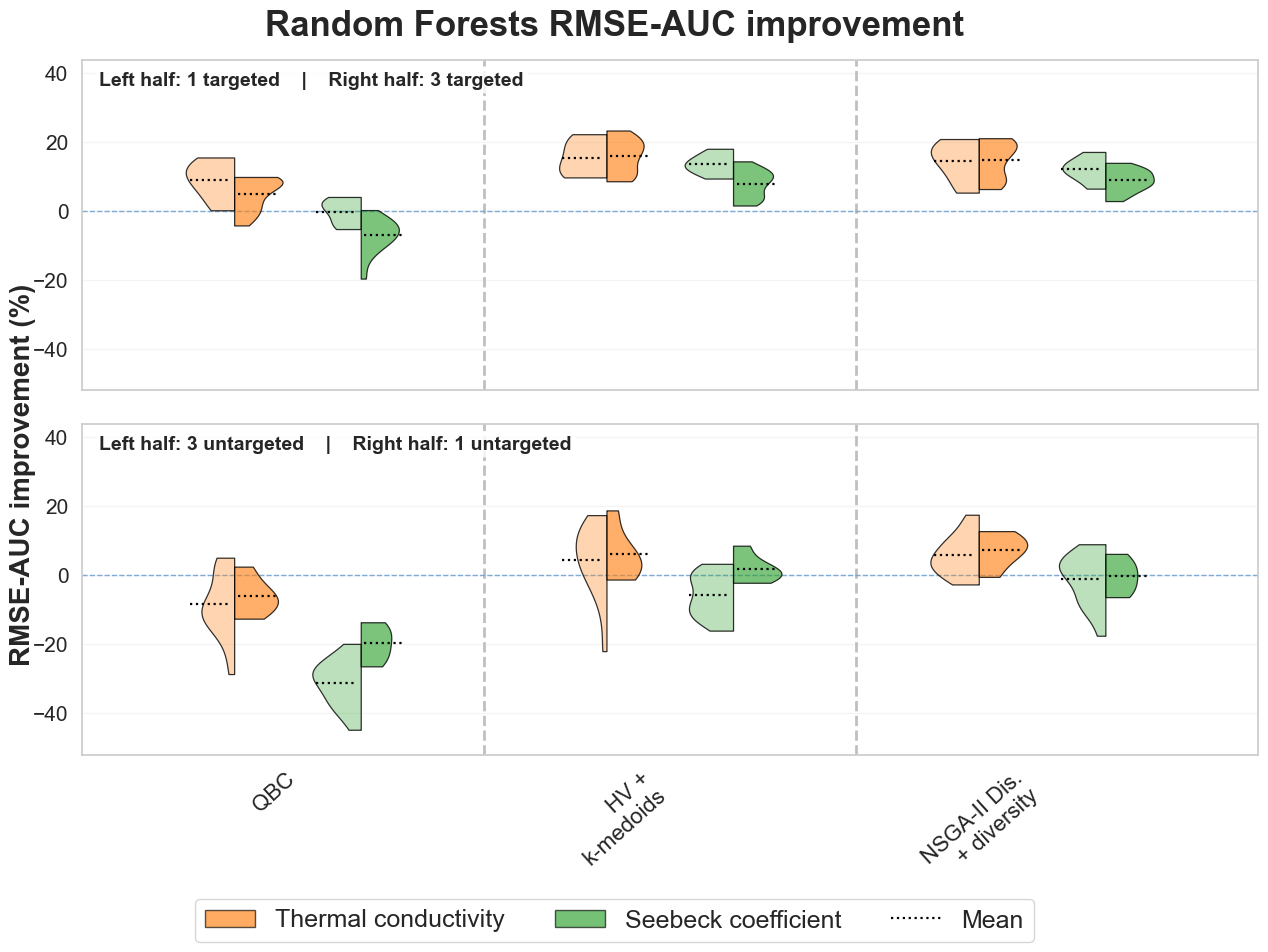


Saved figure:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\ThermoElectricNew3\WITH_MODIFICATIONS\plots\Property_Mean_Direct_From_AL\property_split_violins_rf_three_policies_two_properties.png

Saved DIRECT per-seed/case raw observations:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\ThermoElectricNew3\WITH_MODIFICATIONS\plots\Property_Mean_Direct_From_AL\property_seed_improvements_three_policies_two_properties.csv

Saved DIRECT mean/std/count statistics:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\ThermoElectricNew3\WITH_MODIFICATIONS\plots\Property_Mean_Direct_From_AL\property_mean_std_count_three_policies_two_properties.csv


In [17]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
from matplotlib.lines import Line2D


# =============================================================================
# Configuration
# =============================================================================
BASE_ROOT = Path(
    r"C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES"
    r"\PhD Toronto\DatasetGeneration\Better_Acqsition\ThermoElectricNew3"
    r"\WITH_MODIFICATIONS"
)

DATA_ROOT = BASE_ROOT / "al"
OUTPUT_ROOT = BASE_ROOT / "plots" / "Property_Mean_Direct_From_AL"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

OUTPUT_FIGURE = OUTPUT_ROOT / "property_split_violins_rf_three_policies_two_properties.png"
OUTPUT_RAW_CASES = OUTPUT_ROOT / "property_seed_improvements_three_policies_two_properties.csv"
OUTPUT_STATS = OUTPUT_ROOT / "property_mean_std_count_three_policies_two_properties.csv"

SEEDS = range(5)
MODELS = {
    "rf": "Random Forest",
    "xgb": "XGBoost",
}


# =============================================================================
# Properties and raw RMSE columns
# =============================================================================
RMSE_METRICS = {
    "rmse_k_total": "Thermal conductivity",
    "rmse_seebeck": "Seebeck coefficient",
}

PROPERTY_ID_BY_METRIC = {
    "rmse_k_total": "thermal_cond",
    "rmse_seebeck": "seebeck_coef",
}

PROPERTY_MARKERS = {
    "Thermal conductivity": "D",
    "Seebeck coefficient": "^",
}

PROPERTY_COLORS = {
    "Thermal conductivity": "#ff7f0e",
    "Seebeck coefficient": "#2ca02c",
}

# Two selected properties, centered within each policy group.
PROPERTY_ORDER = [
    "Thermal conductivity",
    "Seebeck coefficient",
]
PROPERTY_X_OFFSETS = {
    "Thermal conductivity": -0.17,
    "Seebeck coefficient": +0.17,
}
VIOLIN_WIDTH = 0.26


# =============================================================================
# Plot cases
# =============================================================================
AXIS_ORDER = [
    "1 targeted",
    "3 untargeted",
    "3 targeted",
    "1 untargeted",
]

POLICY_ORDER = [
    "QBC",
    "HV + k-medoids",
    "NSGA-II QBC + diversity",
]

DISPLAY_POLICY_LABELS = {
    "QBC": "QBC",
    "HV + k-medoids": "HV +\nk-medoids",
    "NSGA-II QBC + diversity": "NSGA-II Dis.\n+ diversity",
}

PANEL_POLICY_ORDER = {axis_name: POLICY_ORDER for axis_name in AXIS_ORDER}


# =============================================================================
# Raw AL layout: one-target campaigns
# =============================================================================
ONE_TARGET_SETS = {
    "electric_cond": {
        "prefix": "ThermoEl_electric_cond",
        "targeted": {"electric_cond"},
    },
    "seebeck_coef": {
        "prefix": "ThermoEl_seebeck_coef",
        "targeted": {"seebeck_coef"},
    },
    "zT": {
        "prefix": "ThermoEl_zT",
        "targeted": {"zT"},
    },
    "thermal_cond": {
        "prefix": "ThermoEl_thermal_cond",
        "targeted": {"thermal_cond"},
    },
}

# Only policies that actually have distinct one-target raw campaigns are listed.
ONE_TARGET_POLICIES = {
    "QBC": (
        "grow_QBC",
        "growing_QBC",
    ),
    "HV + k-medoids": (
        "grow_disagreementHV_topM_kmedoids_OneTarget",
        "growing_1HV_k",
    ),
    "DPP-TS-QBC": (
        "grow_DPP_TS_QBC_OneTarget",
        "growing_DPP_TS_QBC_1target",
    ),
    "NSGA-II QBC + diversity": (
        "grow_EA_DeltaDiversity",
        "growing_EA_1out_div",
    ),
    "TS-QBC": (
        "grow_TS_QBC_no_diversity_OneTarget",
        "growing_TS_nodiv_1target",
    ),
}


# =============================================================================
# Raw AL layout: three-target campaigns
# =============================================================================
THREE_TARGET_SETS = {
    "el_seeb_zT": {
        "prefix": "ThermoEl_el_seeb_zT",
        "targeted": {"electric_cond", "seebeck_coef", "zT"},
    },
    "el_seeb_ThC": {
        "prefix": "ThermoEl_el_seeb_ThC",
        "targeted": {"electric_cond", "seebeck_coef", "thermal_cond"},
    },
    "el_zT_ThC": {
        "prefix": "ThermoEl_el_zT_ThC",
        "targeted": {"electric_cond", "zT", "thermal_cond"},
    },
    "seeb_zT_ThC": {
        "prefix": "ThermoEl_seeb_zT_ThC",
        "targeted": {"seebeck_coef", "zT", "thermal_cond"},
    },
}

THREE_TARGET_POLICIES = {
    "QBC": (
        "grow_3QBC",
        "growing_3QBC",
    ),
    "HV": (
        "grow_disagreementHV_no_diversity_ThreeTargets",
        "growing_HV_nodiv_3targets",
    ),
    "HV + k-medoids": (
        "grow_disagreementHV_topM_kmedoids_ThreeTargets",
        "growing_3HV_k",
    ),
    "DPP-TS-QBC": (
        "grow_DPP_TS_QBC_ThreeTargets",
        "growing_DPP_TS_QBC_3targets",
    ),
    "NSGA-II QBC": (
        "grow_EA_3Obj_ThreeTargets_QBC_ONLY",
        "growing_EA_3obj_qbc_only",
    ),
    "NSGA-II QBC + diversity": (
        "grow_EA_4Obj_ThreeTargets",
        "growing_EA_3out_div",
    ),
    "TS-QBC": (
        "grow_TS_QBC_no_diversity_ThreeTargets",
        "growing_TS_nodiv_3targets",
    ),
}


# =============================================================================
# Raw-file helpers
# =============================================================================
def random_path(model, seed):
    return (
        DATA_ROOT
        / "grow_random"
        / "ThermoEl"
        / "all"
        / str(seed)
        / f"ThermoEl_all_random_{model}{seed}.csv"
    )


def policy_path(folder, target_folder, target_prefix, suffix, model, seed):
    return (
        DATA_ROOT
        / folder
        / "ThermoEl"
        / target_folder
        / str(seed)
        / f"{target_prefix}{suffix}_{model}{seed}.csv"
    )


def normalized_rmse_auc_from_file(path, metric):
    """Return normalized RMSE-AUC from one raw AL CSV file."""
    if not path.exists():
        return None

    df = pd.read_csv(path)

    if "train_ratio" not in df.columns:
        print(f"WARNING: 'train_ratio' missing: {path}")
        return None

    if metric not in df.columns:
        print(f"WARNING: '{metric}' missing: {path}")
        return None

    curve = df[["train_ratio", metric]].copy()
    curve["train_ratio"] = pd.to_numeric(curve["train_ratio"], errors="coerce")
    curve[metric] = pd.to_numeric(curve[metric], errors="coerce")
    curve = (
        curve.dropna()
        .groupby("train_ratio", as_index=False)[metric]
        .mean()
        .sort_values("train_ratio")
    )

    if len(curve) < 2:
        print(f"WARNING: fewer than 2 valid AL iterations: {path} | {metric}")
        return None

    x = 100.0 * curve["train_ratio"].to_numpy(dtype=float)
    y = curve[metric].to_numpy(dtype=float)

    width = x[-1] - x[0]
    if width <= 0:
        print(f"WARNING: invalid AL interval: {path} | {metric}")
        return None

    if hasattr(np, "trapezoid"):
        area = np.trapezoid(y, x)
    else:
        area = np.trapz(y, x)

    return {
        "rmse_auc": float(area / width),
        "first_train_percent": float(x[0]),
        "last_train_percent": float(x[-1]),
        "n_iterations": int(len(curve)),
    }


# =============================================================================
# Build DIRECT per-seed improvements from raw AL files
# =============================================================================
def collect_raw_improvements():
    """
    Build one observation for each:
        model x target campaign x policy x seed x property.

    IMPORTANT:
    No pre-aggregated plot/analysis CSV is used.

    Improvement is calculated directly per seed:

        100 * (1 - policy_RMSE_AUC_seed / random_RMSE_AUC_seed)

    Therefore the final standard deviation reflects variation in the actual
    raw campaign-level/seed-level improvement observations.
    """
    rows = []

    settings = [
        (1, ONE_TARGET_SETS, ONE_TARGET_POLICIES),
        (3, THREE_TARGET_SETS, THREE_TARGET_POLICIES),
    ]

    missing_policy_files = 0
    missing_random_files = 0

    for model in MODELS:
        for n_targets, target_sets, policies in settings:
            for target_folder, target_info in target_sets.items():
                target_prefix = target_info["prefix"]
                targeted_properties = target_info["targeted"]

                for seed in SEEDS:
                    rand_path = random_path(model, seed)
                    if not rand_path.exists():
                        missing_random_files += 1
                        print(f"WARNING: missing Random raw file: {rand_path}")
                        continue

                    # Cache Random AUC once per property for this model/seed.
                    random_auc = {
                        metric: normalized_rmse_auc_from_file(rand_path, metric)
                        for metric in RMSE_METRICS
                    }

                    for policy, (folder, suffix) in policies.items():
                        if policy not in POLICY_ORDER:
                            continue
                        pol_path = policy_path(
                            folder=folder,
                            target_folder=target_folder,
                            target_prefix=target_prefix,
                            suffix=suffix,
                            model=model,
                            seed=seed,
                        )

                        if not pol_path.exists():
                            missing_policy_files += 1
                            print(f"WARNING: missing policy raw file: {pol_path}")
                            continue

                        for metric, property_name in RMSE_METRICS.items():
                            property_id = PROPERTY_ID_BY_METRIC[metric]
                            case_type = (
                                "targeted"
                                if property_id in targeted_properties
                                else "untargeted"
                            )

                            if n_targets == 1:
                                axis_name = (
                                    "1 targeted"
                                    if case_type == "targeted"
                                    else "3 untargeted"
                                )
                            else:
                                axis_name = (
                                    "3 targeted"
                                    if case_type == "targeted"
                                    else "1 untargeted"
                                )

                            pol_auc = normalized_rmse_auc_from_file(pol_path, metric)
                            rand_auc = random_auc[metric]

                            if pol_auc is None or rand_auc is None:
                                continue

                            if rand_auc["rmse_auc"] == 0:
                                print(
                                    "WARNING: Random RMSE-AUC is zero; skipping: "
                                    f"model={model}, seed={seed}, metric={metric}"
                                )
                                continue

                            improvement_percent = 100.0 * (
                                1.0 - pol_auc["rmse_auc"] / rand_auc["rmse_auc"]
                            )

                            rows.append(
                                {
                                    "model": model,
                                    "model_name": MODELS[model],
                                    "n_targets": n_targets,
                                    "axis": axis_name,
                                    "case_type": case_type,
                                    "target_case": target_folder,
                                    "policy": policy,
                                    "seed": seed,
                                    "metric": metric,
                                    "property_id": property_id,
                                    "property_name": property_name,
                                    "improvement_percent": improvement_percent,
                                    "policy_rmse_auc": pol_auc["rmse_auc"],
                                    "random_rmse_auc": rand_auc["rmse_auc"],
                                    "policy_file": str(pol_path),
                                    "random_file": str(rand_path),
                                }
                            )

    print("\n================ RAW AL FILE DIAGNOSTIC ================")
    print(f"Missing policy files encountered: {missing_policy_files}")
    print(f"Missing Random files encountered: {missing_random_files}")

    raw_df = pd.DataFrame(rows)
    if raw_df.empty:
        raise RuntimeError(
            "No raw AL observations were loaded. Check DATA_ROOT and raw filenames."
        )

    return raw_df


# =============================================================================
# Direct mean / standard deviation / count
# =============================================================================
def summarize_raw_improvements(raw_df):
    stats_df = (
        raw_df.groupby(
            [
                "model",
                "model_name",
                "axis",
                "n_targets",
                "case_type",
                "policy",
                "property_id",
                "property_name",
            ],
            as_index=False,
        )["improvement_percent"]
        .agg(
            mean_percent="mean",
            std_percent="std",
            count="count",
        )
    )

    print("\n================ DIRECT RAW-AL STATISTICS ================")
    for row in stats_df.itertuples(index=False):
        std_text = "NaN" if pd.isna(row.std_percent) else f"{row.std_percent:.4f}"
        print(
            f"{row.model:>3} | {row.axis:<14} | {row.policy:<27} | "
            f"{row.property_name:<26} | mean={row.mean_percent:8.4f} | "
            f"std={std_text:>8} | count={int(row.count):2d}"
        )

        if row.count < 2 or pd.isna(row.std_percent):
            print(
                "  WARNING: standard deviation cannot be estimated reliably "
                f"because count={int(row.count)}."
            )

    return stats_df


raw_df = collect_raw_improvements()
raw_df.to_csv(OUTPUT_RAW_CASES, index=False)

stats_df = summarize_raw_improvements(raw_df)
stats_df.to_csv(OUTPUT_STATS, index=False)


# =============================================================================
# Automatic y limits using the DIRECT raw observations
# =============================================================================
def calculate_case_y_limits(raw_df, padding_fraction=0.12, minimum_padding=2.0):
    limits = {}

    for axis_name in AXIS_ORDER:
        subset = raw_df.loc[raw_df["axis"] == axis_name].copy()
        values = pd.to_numeric(subset["improvement_percent"], errors="coerce")
        values = values[np.isfinite(values)]

        if len(values) == 0:
            limits[axis_name] = (-1, 1)
            continue

        data_min = float(values.min())
        data_max = float(values.max())
        span = max(data_max - data_min, 1.0)
        padding = max(minimum_padding, padding_fraction * span)

        y_min = int(np.floor(data_min - padding))
        y_max = int(np.ceil(data_max + padding))
        y_min = min(y_min, 0)
        y_max = max(y_max, 0)

        if y_min == y_max:
            y_min -= 1
            y_max += 1

        limits[axis_name] = (y_min, y_max)

    return limits


CASE_Y_LIMITS = calculate_case_y_limits(raw_df)

# Use one common y-scale across all panels.
all_values = pd.to_numeric(raw_df["improvement_percent"], errors="coerce")
all_values = all_values[np.isfinite(all_values)]
if len(all_values) == 0:
    GLOBAL_Y_LIM = (-1, 1)
else:
    global_min = float(all_values.min())
    global_max = float(all_values.max())
    global_span = max(global_max - global_min, 1.0)
    global_padding = max(1.0, 0.08 * global_span)
    y_min = int(np.floor(global_min - global_padding))
    y_max = int(np.ceil(global_max + global_padding))
    y_min = min(y_min, 0)
    y_max = max(y_max, 0)
    if y_min == y_max:
        y_min -= 1
        y_max += 1
    GLOBAL_Y_LIM = (y_min, y_max)

print("\n================ PANEL Y LIMITS ================")
for axis_name in AXIS_ORDER:
    print(f"{axis_name}: {CASE_Y_LIMITS[axis_name]}")
print(f"Common y scale used for all panels: {GLOBAL_Y_LIM}")


# =============================================================================
# Plot split violin plots directly from the raw AL observations using seaborn
# Random Forest only, arranged as two vertical panels.
#   Top:    left half = 1 targeted,     right half = 3 targeted
#   Bottom: left half = 3 untargeted,   right half = 1 untargeted
# =============================================================================
PANEL_SPECS = [
    {
        "left_axis": "1 targeted",
        "right_axis": "3 targeted",
        "title": "Left half: 1 targeted    |    Right half: 3 targeted",
    },
    {
        "left_axis": "3 untargeted",
        "right_axis": "1 untargeted",
        "title": "Left half: 3 untargeted    |    Right half: 1 untargeted",
    },
]


def shift_new_violin_bodies(ax, start_collection_idx, x_offset):
    new_collections = ax.collections[start_collection_idx:]
    for coll in new_collections:
        if not hasattr(coll, "get_paths"):
            continue
        for path in coll.get_paths():
            path.vertices[:, 0] += x_offset


def draw_half_mean_line(ax, values, position, width, side):
    if len(values) == 0:
        return

    mean_val = float(np.mean(values))
    half_pad = 0.01
    half_extent = 0.46 * width

    if side == "left":
        x0 = position - half_extent
        x1 = position - half_pad
    else:
        x0 = position + half_pad
        x1 = position + half_extent

    ax.hlines(
        mean_val,
        x0,
        x1,
        colors="black",
        linewidth=1.6,
        linestyles=":",
        zorder=4,
    )


fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(13, 10),
    sharex=False,
    sharey=True,
)

model = "rf"
panel_df_all = raw_df.loc[raw_df["model"] == model].copy()
common_y_min, common_y_max = GLOBAL_Y_LIM
common_policy_order = POLICY_ORDER
x_positions = np.arange(len(common_policy_order), dtype=float)

for row_index, panel_spec in enumerate(PANEL_SPECS):
    ax = axes[row_index]

    left_axis = panel_spec["left_axis"]
    right_axis = panel_spec["right_axis"]

    left_df = panel_df_all.loc[panel_df_all["axis"] == left_axis].copy()
    right_df = panel_df_all.loc[panel_df_all["axis"] == right_axis].copy()

    for property_name in PROPERTY_ORDER:
        color = PROPERTY_COLORS.get(property_name, "gray")

        left_prop_df = left_df.loc[left_df["property_name"] == property_name, ["policy", "improvement_percent"]].copy()
        right_prop_df = right_df.loc[right_df["property_name"] == property_name, ["policy", "improvement_percent"]].copy()

        left_prop_df["comparison_case"] = "left"
        right_prop_df["comparison_case"] = "right"
        prop_df = pd.concat([left_prop_df, right_prop_df], ignore_index=True)
        prop_df["policy"] = pd.Categorical(prop_df["policy"], categories=common_policy_order, ordered=True)
        prop_df["comparison_case"] = pd.Categorical(prop_df["comparison_case"], categories=["left", "right"], ordered=True)
        prop_df["improvement_percent"] = pd.to_numeric(prop_df["improvement_percent"], errors="coerce")
        prop_df = prop_df.dropna(subset=["improvement_percent"])

        if prop_df.empty:
            print(f"WARNING: no raw observations available for property={property_name}, left_axis={left_axis}, right_axis={right_axis}")
            continue

        start_idx = len(ax.collections)
        sns.violinplot(
            data=prop_df,
            x="policy",
            y="improvement_percent",
            hue="comparison_case",
            order=common_policy_order,
            hue_order=["left", "right"],
            split=True,
            inner=None,
            cut=0,
            bw_adjust=1.0,
            gridsize=200,
            linewidth=1.0,
            saturation=1.0,
            palette={"left": color, "right": color},
            width=VIOLIN_WIDTH,
            ax=ax,
        )
        shift_new_violin_bodies(ax, start_idx, PROPERTY_X_OFFSETS[property_name])

        # Keep the EXACT property RGB color on both halves.
        # Only transparency changes: left is lighter, right is darker.
        # Detect the side geometrically instead of relying on Seaborn's
        # collection ordering, which can change when some policy/case data are missing.
        new_collections = ax.collections[start_idx:]
        property_rgb = mcolors.to_rgb(color)
        expected_centers = x_positions + PROPERTY_X_OFFSETS[property_name]

        for coll in new_collections:
            try:
                paths = coll.get_paths()
                if not paths:
                    continue

                verts = paths[0].vertices
                x_mean = float(np.mean(verts[:, 0]))
                nearest_center = float(
                    expected_centers[np.argmin(np.abs(expected_centers - x_mean))]
                )

                if x_mean < nearest_center:
                    face_rgba = (*property_rgb, 0.32)   # left half: lighter
                else:
                    face_rgba = (*property_rgb, 0.62)   # right half: darker

                # Store transparency only in the RGBA face color.
                # IMPORTANT: do NOT call set_alpha(1.0), because Collection alpha
                # overrides the alpha embedded in face_rgba and makes everything opaque.
                coll.set_alpha(None)
                coll.set_facecolor([face_rgba])
                coll.set_edgecolor((*mcolors.to_rgb("black"), 0.80))
                coll.set_linewidth(0.9)
            except Exception as exc:
                print(
                    f"WARNING: could not style violin half for {property_name}: {exc}"
                )

        if ax.get_legend() is not None:
            ax.get_legend().remove()

        for x, policy in zip(x_positions, common_policy_order):
            left_values = pd.to_numeric(
                left_df.loc[
                    (left_df["policy"] == policy) & (left_df["property_name"] == property_name),
                    "improvement_percent",
                ],
                errors="coerce",
            )
            left_values = left_values[np.isfinite(left_values)].to_numpy(dtype=float)

            right_values = pd.to_numeric(
                right_df.loc[
                    (right_df["policy"] == policy) & (right_df["property_name"] == property_name),
                    "improvement_percent",
                ],
                errors="coerce",
            )
            right_values = right_values[np.isfinite(right_values)].to_numpy(dtype=float)

            x_plot = x + PROPERTY_X_OFFSETS[property_name]
            if len(left_values) > 0:
                draw_half_mean_line(
                    ax=ax,
                    values=left_values,
                    position=x_plot,
                    width=VIOLIN_WIDTH,
                    side="left",
                )
            if len(right_values) > 0:
                draw_half_mean_line(
                    ax=ax,
                    values=right_values,
                    position=x_plot,
                    width=VIOLIN_WIDTH,
                    side="right",
                )

    ax.set_ylim(common_y_min, common_y_max)
    ax.set_xlim(-0.58, len(common_policy_order) - 0.42)
    ax.set_xticks(x_positions)

    if row_index == 0:
        ax.set_xticklabels([])
        ax.tick_params(axis="x", which="both", labelbottom=False)
    else:
        ax.set_xticklabels(
            [DISPLAY_POLICY_LABELS[p] for p in common_policy_order],
            fontsize=16.0,
            rotation=42,
            ha="right",
        )
        ax.tick_params(axis="x", which="both", labelbottom=True)

    ax.grid(axis="y", alpha=0.20)
    ax.axhline(0.0, color="#5b9bd5", linewidth=1.0, linestyle="--", alpha=0.90, zorder=0)

    for separator_x in np.arange(len(common_policy_order) - 1, dtype=float) + 0.5:
        ax.axvline(
            separator_x,
            color="0.55",
            linewidth=2.0,
            linestyle="--",
            alpha=0.55,
            zorder=0,
        )

    y_range = common_y_max - common_y_min
    if y_range <= 8:
        tick_step = 2
    elif y_range <= 16:
        tick_step = 4
    elif y_range <= 30:
        tick_step = 5
    elif y_range <= 50:
        tick_step = 10
    else:
        tick_step = 20

    first_tick = int(np.ceil(common_y_min / tick_step) * tick_step)
    last_tick = int(np.floor(common_y_max / tick_step) * tick_step)
    yticks = np.arange(first_tick, last_tick + tick_step, tick_step, dtype=int)
    if common_y_min <= 0 <= common_y_max and 0 not in yticks:
        yticks = np.sort(np.append(yticks, 0))
    ax.tick_params(axis="y", labelsize=15)
    ax.set_yticks(yticks)

    ax.text(
        0.015,
        0.965,
        panel_spec["title"],
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=14,
        fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.22", facecolor="white", edgecolor="none", alpha=0.82),
    )
  
    ax.set_ylabel("")
    ax.set_xlabel("")


fig.suptitle(
    "Random Forests RMSE-AUC improvement",
    fontsize=25,
    fontweight="bold",
    y=0.965,
)

fig.supylabel(
    "RMSE-AUC improvement (%)",
    fontsize=20,
    fontweight="bold",
    x=0.035,
)

property_handles = [
    Patch(
        facecolor=PROPERTY_COLORS[property_name],
        edgecolor="black",
        alpha=0.65,
        label=property_name,
    )
    for property_name in PROPERTY_ORDER
]

property_handles += [
    Line2D([0], [0], color="black", linewidth=1.6, linestyle=":", label="Mean"),
]

fig.legend(
    handles=property_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.02),
    ncol=3,
    fontsize=18,
    frameon=True,
)

plt.subplots_adjust(
    left=0.09,
    right=0.995,
    top=0.915,
    bottom=0.22,
    hspace=0.10,
)

fig.savefig(OUTPUT_FIGURE, dpi=250, bbox_inches="tight")
plt.show()
plt.close(fig)


print("\nSaved figure:")
print(OUTPUT_FIGURE)
print("\nSaved DIRECT per-seed/case raw observations:")
print(OUTPUT_RAW_CASES)
print("\nSaved DIRECT mean/std/count statistics:")
print(OUTPUT_STATS)

Samples used: 7770

Outcome columns:
  Electrical Conductivity (S/cm)
  Seebeck Coefficient (µV/K)
  zT
  Total Thermal Conductivity (W/mK)

Explained variance:
PC1 = 0.1194
PC2 = 0.0833
Total = 0.2027


C:\Users\rafae\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\rafae\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^


================ QUANTILE BINNING =================
Electrical conductivity: N_pool=7770, requested_bins=89, actual_bins=89, pool_count/bin min=68, median=87.0, max=106
Seebeck coefficient: N_pool=7770, requested_bins=89, actual_bins=89, pool_count/bin min=80, median=87.0, max=93
zT: N_pool=7770, requested_bins=89, actual_bins=89, pool_count/bin min=82, median=87.0, max=93
Thermal conductivity: N_pool=7770, requested_bins=89, actual_bins=89, pool_count/bin min=68, median=87.0, max=107


EXPERIMENTAL DATASET: ThermoEl | TARGET: Thermal conductivity
Thermal conductivity | DPP-TS-QBC | seed 0
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\ThermoElectricNew3\WITH_MODIFICATIONS\al\grow_DPP_TS_QBC_OneTarget\ThermoEl\thermal_cond\0\ThermoEl_thermal_condgrowing_DPP_TS_QBC_1target0_trainIndices.csv
Thermal conductivity | DPP-TS-QBC | seed 1
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGenera

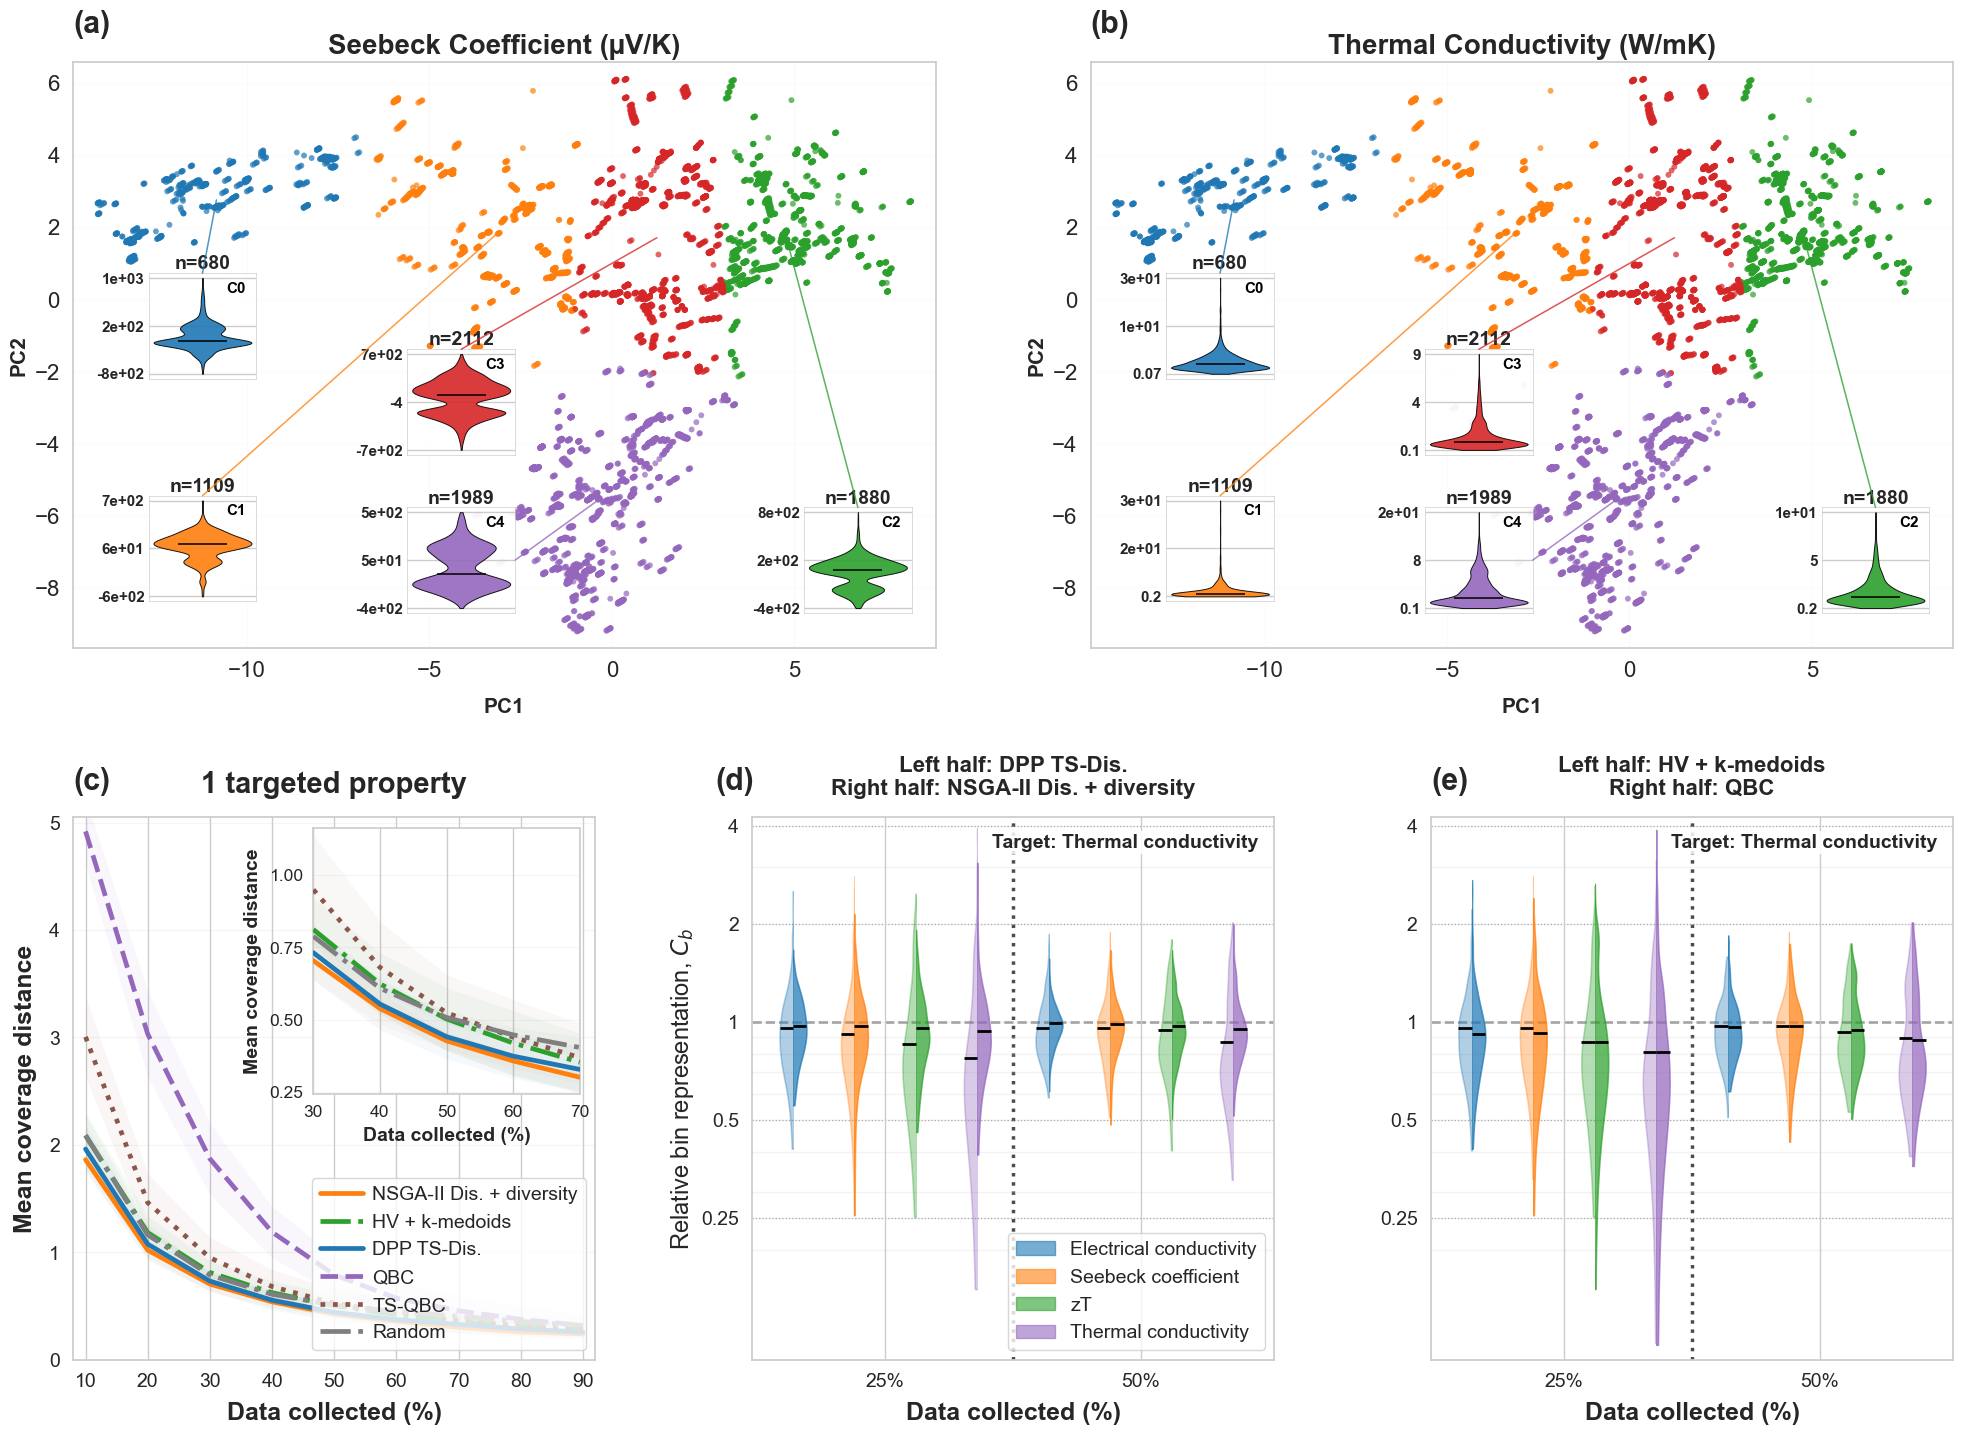

In [18]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from matplotlib.ticker import FormatStrFormatter
from matplotlib.patches import ConnectionPatch, Patch, Rectangle
from matplotlib.lines import Line2D
from matplotlib.ticker import FixedLocator, FixedFormatter, NullFormatter
# =============================================================================
# PATHS
# =============================================================================
BASE = Path(
    r"C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES"
    r"\PhD Toronto\DatasetGeneration\Better_Acqsition"
    r"\ThermoElectricNew3\WITH_MODIFICATIONS"
)
DATA_PATH = BASE / "CLEANED_DATA_AND_FILTERED.csv"
SUMMARY_CSV = (
    BASE
    / "ThermoEl_COVERAGE_unselected_to_selected_mean_min_distance_MEAN_STD_ALL_RAW_SEEDS.csv"
)
OUTPUT_FIGURE = BASE / "ThermoEl_PCA_coverage_thermal_Cb_25_50_compact.png"
# =============================================================================
# TOP-ROW PCA + VIOLIN SETTINGS
# =============================================================================
N_FEATURES = 161
N_CLUSTERS = 5
RANDOM_SEED = 42
POINT_SIZE = 18
ALPHA_POINTS = 0.7
VIOLIN_POSITIONS = {
    0: (0.15, 0.55),
    1: (0.15, 0.17),
    2: (0.91, 0.15),
    3: (0.45, 0.42),
    4: (0.45, 0.15),
    5: (0.90, 0.38),
    6: (0.36, 0.36),
    7: (0.90, 0.10),
    8: (0.15, 0.18),
    9: (0.40, 0.10),
}
INSET_WIDTH = 0.125
INSET_HEIGHT = 0.18
VIOLIN_TICK_FONTSIZE = 11
VIOLIN_TITLE_FONTSIZE = 14
MAIN_TITLE_FONTSIZE = 20
AXIS_LABEL_FONTSIZE = 15
AXIS_TICK_FONTSIZE = 16
# =============================================================================
# BOTTOM-ROW COVERAGE SETTINGS
# =============================================================================
PERCENTAGES = list(range(10, 100, 10))
MAIN_YMIN = 0.0
MAIN_YMAX = 5.05
INSET_XMIN = 30
INSET_XMAX = 70
AUTO_INSET_YLIM = True
INSET_YMIN = 2e-1
INSET_YMAX = 1.1
LINE_WIDTH = 3.4
MARKER_SIZE = 9.0
RIBBON_ALPHA = 0.05
POLICIES_BY_TARGET_COUNT = {
    1: [
        "NSGA-II + diversity",
        "HV + k-medoids",
        "DPP-TS-QBC",
        "QBC",
        "TS-QBC",
        "Random",
    ],
    2: [
        "NSGA-II + diversity",
        "NSGA-II",
        "HV + k-medoids",
        "DPP-TS-QBC",
        "QBC",
        "TS-QBC",
        "Random",
    ],
    3: [
        "NSGA-II + diversity",
        "NSGA-II",
        "HV + k-medoids",
        "DPP-TS-QBC",
        "QBC",
        "TS-QBC",
        "Random",
    ],
}
POLICY_STYLE = {
    "NSGA-II + diversity": {
        "color": "tab:orange",
        "marker": "o",
        "linestyle": "-",
    },
    "NSGA-II": {
        "color": "tab:red",
        "marker": "P",
        "linestyle": "--",
    },
    "HV + k-medoids": {
        "color": "tab:green",
        "marker": "^",
        "linestyle": "-.",
    },
    "DPP-TS-QBC": {
        "color": "tab:blue",
        "marker": "s",
        "linestyle": "-",
    },
    "QBC": {
        "color": "tab:purple",
        "marker": "D",
        "linestyle": "--",
    },
    "TS-QBC": {
        "color": "tab:brown",
        "marker": "v",
        "linestyle": ":",
    },
    "Random": {
        "color": "tab:gray",
        "marker": "X",
        "linestyle": "-.",
    },
}
# =============================================================================
# LOAD AND PREPARE DATA FOR THE TOP ROW
# =============================================================================
df_raw = pd.read_csv(DATA_PATH)
if df_raw.shape[1] == 165:
    df = df_raw.copy()
elif df_raw.shape[1] == 166:
    df = df_raw.copy()
    df = df.set_index(df.columns[0])
else:
    raise ValueError(
        f"Unexpected number of columns: {df_raw.shape[1]}. "
        "Expected 165 or 166."
    )
feature_cols = df.columns[:N_FEATURES]
outcome_cols = df.columns[-4:]
X = df.loc[:, feature_cols].apply(pd.to_numeric, errors="coerce")
Y = df.loc[:, outcome_cols].apply(pd.to_numeric, errors="coerce")
valid_mask = (
    X.notna().all(axis=1)
    & Y.notna().all(axis=1)
    & np.isfinite(X.to_numpy(dtype=float)).all(axis=1)
    & np.isfinite(Y.to_numpy(dtype=float)).all(axis=1)
)
X = X.loc[valid_mask].copy()
Y = Y.loc[valid_mask].copy()
print(f"Samples used: {len(X)}")
print("\nOutcome columns:")
for col in outcome_cols:
    print(f"  {col}")
# Same feature treatment as the original PCA/violin code.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
pca = PCA(n_components=2, random_state=RANDOM_SEED)
X_pca = pca.fit_transform(X_scaled)
pca_df = pd.DataFrame(
    X_pca,
    index=X.index,
    columns=["PC1", "PC2"],
)
print(
    "\nExplained variance:"
    f"\nPC1 = {pca.explained_variance_ratio_[0]:.4f}"
    f"\nPC2 = {pca.explained_variance_ratio_[1]:.4f}"
    f"\nTotal = {pca.explained_variance_ratio_.sum():.4f}"
)
kmeans = KMeans(
    n_clusters=N_CLUSTERS,
    random_state=RANDOM_SEED,
    n_init=20,
)
cluster_labels = kmeans.fit_predict(pca_df[["PC1", "PC2"]])
pca_df["cluster"] = cluster_labels
Y["cluster"] = cluster_labels
centroids = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=["PC1", "PC2"],
)
centroids["cluster"] = np.arange(N_CLUSTERS)
# Keep the same relabeling used by the original code.
centroids_sorted = centroids.sort_values(
    by=["PC2", "PC1"],
    ascending=[False, True],
).reset_index(drop=True)
old_to_new = {
    int(old): int(new)
    for new, old in enumerate(centroids_sorted["cluster"].tolist())
}
pca_df["cluster"] = pca_df["cluster"].map(old_to_new)
Y["cluster"] = Y["cluster"].map(old_to_new)
centroids["cluster"] = centroids["cluster"].map(old_to_new)
centroids = centroids.sort_values("cluster").reset_index(drop=True)
cluster_anchors = (
    pca_df.groupby("cluster")[["PC1", "PC2"]]
    .mean()
    .reset_index()
)
cmap = plt.get_cmap("tab10")
cluster_colors = {i: cmap(i) for i in range(N_CLUSTERS)}
# Shared PCA limits for Seebeck coefficient and thermal conductivity, as in the original shared axes.
xmin = float(pca_df["PC1"].min())
xmax = float(pca_df["PC1"].max())
ymin = float(pca_df["PC2"].min())
ymax = float(pca_df["PC2"].max())
xpad = 0.03 * max(xmax - xmin, 1.0)
ypad = 0.03 * max(ymax - ymin, 1.0)
PCA_XLIM = (xmin - xpad, xmax + xpad)
PCA_YLIM = (ymin - ypad, ymax + ypad)
# =============================================================================
# LOAD COVERAGE SUMMARY FOR THE BOTTOM ROW
# =============================================================================
if not SUMMARY_CSV.exists():
    raise FileNotFoundError(f"Summary CSV not found:\n{SUMMARY_CSV}")
summary_df = pd.read_csv(SUMMARY_CSV)
required_columns = {
    "percent",
    "policy",
    "mean_coverage_distance",
    "std_across_raw_cases",
    "n_raw",
    "target_count",
}
missing_columns = required_columns.difference(summary_df.columns)
if missing_columns:
    raise KeyError(
        "The summary CSV is missing required columns:\n"
        f"{sorted(missing_columns)}\n\n"
        f"Available columns:\n{list(summary_df.columns)}"
    )
# =============================================================================
# HELPERS: TOP ROW
# =============================================================================
def choose_inset_anchor_point(
    cluster_ax_x,
    cluster_ax_y,
    inset_center_x,
    inset_center_y,
):
    """Choose the inset border point that faces the cluster anchor."""
    dx = inset_center_x - cluster_ax_x
    dy = inset_center_y - cluster_ax_y
    if abs(dx) >= abs(dy):
        if dx >= 0:
            return (0.0, 0.5)
        return (1.0, 0.5)
    if dy >= 0:
        return (0.5, 0.0)
    return (0.5, 1.0)
def plot_pca_with_cluster_violins(
    fig,
    ax,
    outcome_col,
    outcome_title,
):
    """Reproduce one PCA + cluster-violin panel from the original code."""
    for cluster_id in range(N_CLUSTERS):
        mask = pca_df["cluster"] == cluster_id
        ax.scatter(
            pca_df.loc[mask, "PC1"],
            pca_df.loc[mask, "PC2"],
            s=POINT_SIZE,
            color=cluster_colors[cluster_id],
            alpha=ALPHA_POINTS,
            edgecolors="none",
            zorder=1,
        )
    ax.set_title(
        outcome_title,
        fontsize=MAIN_TITLE_FONTSIZE,
        fontweight="bold",
    )
    ax.set_xlabel(
        "PC1",
        fontsize=AXIS_LABEL_FONTSIZE,
        fontweight="bold",
        labelpad=12,
    )
    ax.set_ylabel(
        "PC2",
        fontsize=AXIS_LABEL_FONTSIZE,
        fontweight="bold",
    )
    ax.tick_params(axis="both", labelsize=AXIS_TICK_FONTSIZE)
    ax.grid(alpha=0.08)
    ax.set_xlim(*PCA_XLIM)
    ax.set_ylim(*PCA_YLIM)
    for cluster_id in range(N_CLUSTERS):
        cluster_mask = Y["cluster"] == cluster_id
        cluster_values = Y.loc[cluster_mask, outcome_col].dropna().to_numpy()
        if len(cluster_values) == 0:
            continue
        cx = cluster_anchors.loc[
            cluster_anchors["cluster"] == cluster_id,
            "PC1",
        ].iloc[0]
        cy = cluster_anchors.loc[
            cluster_anchors["cluster"] == cluster_id,
            "PC2",
        ].iloc[0]
        x_fraction, y_fraction = VIOLIN_POSITIONS[cluster_id]
        violin_ax = ax.inset_axes(
            [
                x_fraction - INSET_WIDTH / 2,
                y_fraction - INSET_HEIGHT / 2,
                INSET_WIDTH,
                INSET_HEIGHT,
            ],
            transform=ax.transAxes,
            zorder=8,
        )
        vp = violin_ax.violinplot(
            [cluster_values],
            positions=[1],
            widths=0.85,
            showmeans=False,
            showmedians=True,
            showextrema=False,
        )
        for body in vp["bodies"]:
            body.set_facecolor(cluster_colors[cluster_id])
            body.set_edgecolor("black")
            body.set_linewidth(0.7)
            body.set_alpha(0.90)
        if "cmedians" in vp:
            vp["cmedians"].set_color("black")
            vp["cmedians"].set_linewidth(1.1)
        violin_ax.set_xticks([])
        ymin_v = np.nanmin(cluster_values)
        ymax_v = np.nanmax(cluster_values)
        if np.isclose(ymin_v, ymax_v):
            ticks = [ymin_v]
        else:
            ticks = np.linspace(ymin_v, ymax_v, 3)
        violin_ax.set_yticks(ticks)
        violin_ax.yaxis.set_major_formatter(FormatStrFormatter("%.1g"))
        violin_ax.tick_params(
            axis="y",
            labelsize=VIOLIN_TICK_FONTSIZE,
            length=2,
            pad=1,
        )
        for label in violin_ax.get_yticklabels():
            label.set_fontweight("bold")
        violin_ax.set_title(
            f"n={len(cluster_values)}",
            fontsize=VIOLIN_TITLE_FONTSIZE,
            fontweight="bold",
            pad=1,
        )
        violin_ax.text(
            0.90,
            0.92,
            f"C{cluster_id}",
            transform=violin_ax.transAxes,
            ha="right",
            va="top",
            fontsize=11,
            fontweight="bold",
            color="black",
            bbox=dict(
                boxstyle="round,pad=0.15",
                facecolor="white",
                edgecolor="none",
                alpha=0.60,
            ),
            zorder=10,
        )
        violin_ax.set_facecolor((1, 1, 1, 0.94))
        for spine in violin_ax.spines.values():
            spine.set_linewidth(0.7)
            spine.set_alpha(0.7)
        cluster_display = ax.transData.transform((cx, cy))
        cluster_axes = ax.transAxes.inverted().transform(cluster_display)
        cluster_ax_x, cluster_ax_y = cluster_axes
        inset_anchor = choose_inset_anchor_point(
            cluster_ax_x=cluster_ax_x,
            cluster_ax_y=cluster_ax_y,
            inset_center_x=x_fraction,
            inset_center_y=y_fraction,
        )
        connector = ConnectionPatch(
            xyA=inset_anchor,
            coordsA=violin_ax.transAxes,
            xyB=(cx, cy),
            coordsB=ax.transData,
            axesA=violin_ax,
            axesB=ax,
            color=cluster_colors[cluster_id],
            linewidth=1.1,
            alpha=0.78,
            zorder=5,
        )
        fig.add_artist(connector)
# =============================================================================
# HELPERS: BOTTOM ROW
# =============================================================================
def draw_policy(
    ax,
    sub,
    policy,
    include_label=True,
    ribbon_alpha=RIBBON_ALPHA,
):
    """Draw mean +/- 1 SD for one coverage policy."""
    sub = sub.sort_values("percent")
    x = sub["percent"].to_numpy(dtype=float)
    mean_values = sub["mean_coverage_distance"].to_numpy(dtype=float)
    std_values = sub["std_across_raw_cases"].to_numpy(dtype=float)
    lower = np.maximum(mean_values - std_values, 0.0)
    upper = mean_values + std_values
    color = POLICY_STYLE[policy]["color"]
    marker = POLICY_STYLE[policy]["marker"]
    linestyle = POLICY_STYLE[policy]["linestyle"]
    ax.fill_between(
        x,
        lower,
        upper,
        color=color,
        alpha=ribbon_alpha,
        linewidth=0,
        zorder=1,
    )
    ax.plot(
        x,
        mean_values,
        color=color,
        linestyle=linestyle,
        linewidth=LINE_WIDTH,
        markeredgewidth=0.75,
        label=policy if include_label else None,
        zorder=5,
    )
def automatic_inset_ylim(panel):
    """Fit a positive log-scale range to the policies shown in the inset."""
    zoom = panel[panel["percent"].between(INSET_XMIN, INSET_XMAX)]
    if zoom.empty:
        return INSET_YMIN, INSET_YMAX
    means = zoom["mean_coverage_distance"].to_numpy(dtype=float)
    stds = zoom["std_across_raw_cases"].to_numpy(dtype=float)
    lower, upper = means - stds, means + stds
    positive_lower = lower[np.isfinite(lower) & (lower > 0)]
    positive_upper = upper[np.isfinite(upper) & (upper > 0)]
    if not len(positive_lower) or not len(positive_upper):
        return INSET_YMIN, INSET_YMAX
    y_min = float(positive_lower.min())
    y_max = float(positive_upper.max())
    if y_max <= y_min:
        return y_min / 1.1, y_min * 1.1
    return y_min / 1.02, y_max * 1.02
def plot_coverage_panel(ax, summary_df, target_count):
    """Adapt the original standalone coverage figure to one panel."""
    panel = summary_df[
        summary_df["target_count"] == target_count
    ].copy()
    if panel.empty:
        raise ValueError(f"No rows found for target_count = {target_count}")
    policy_order = POLICIES_BY_TARGET_COUNT[target_count]
    title_main = {
        1: "1 targeted property",
        2: "2 targeted properties",
        3: "3 targeted properties",
    }[target_count]
    for policy in policy_order:
        sub = panel[panel["policy"] == policy].copy()
        if sub.empty:
            print(
                f"[WARNING] No saved data for "
                f"target_count={target_count}, policy={policy}"
            )
            continue
        draw_policy(
            ax=ax,
            sub=sub,
            policy=policy,
            include_label=True,
            ribbon_alpha=RIBBON_ALPHA,
        )
    ax.set_title(
    f"{title_main}",
    fontsize=21,
    fontweight="bold",
    pad=18,
    )
    ax.set_xlabel(
        "Data collected (%)",
        fontsize=18,
        fontweight="bold",
        labelpad=8,
    )
    ax.set_ylabel(
        "Mean coverage distance",
        fontsize=18,
        fontweight="bold",
        labelpad=9,
    )
    ax.set_xticks(PERCENTAGES)
    ax.set_xlim(min(PERCENTAGES) - 2, max(PERCENTAGES) + 2)
    ax.set_ylim(MAIN_YMIN, MAIN_YMAX)
    ax.set_yticks(np.arange(0, MAIN_YMAX + 0.01, 1))
    ax.tick_params(
        axis="both",
        labelsize=14,
        width=1.2,
        length=6,
    )
    ax.grid(axis="y", alpha=0.18, linewidth=0.9)
    ax.set_axisbelow(True)
    # QBC stays in the main panel but is excluded from the zoom and its limits.
    axzoom = ax.inset_axes([0.46, 0.49, 0.51, 0.49])
    inset_policies = [policy for policy in policy_order if policy != "QBC"]
    inset_panel = panel[panel["policy"].isin(inset_policies)].copy()
    for policy in inset_policies:
        sub = inset_panel[inset_panel["policy"] == policy]
        sub_zoom = sub[sub["percent"].between(INSET_XMIN, INSET_XMAX)]
        if sub_zoom.empty:
            continue
        draw_policy(
            ax=axzoom, sub=sub_zoom, policy=policy,
            include_label=False, ribbon_alpha=RIBBON_ALPHA * 0.9,
        )
    axzoom.set_xlim(INSET_XMIN, INSET_XMAX)
    if AUTO_INSET_YLIM:
        inset_ymin, inset_ymax = automatic_inset_ylim(inset_panel)
    else:
        inset_ymin, inset_ymax = INSET_YMIN, INSET_YMAX
    # Use a linear y-axis and ordinary decimal tick labels.
    axzoom.yaxis.set_major_locator(plt.MaxNLocator(nbins=4))
    axzoom.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))

    axzoom.set_ylim(inset_ymin, inset_ymax)
    axzoom.set_xticks(
        [x for x in PERCENTAGES if INSET_XMIN <= x <= INSET_XMAX]
    )
    axzoom.set_xlabel(
        "Data collected (%)",
        fontsize=14,
        fontweight="bold",
        labelpad=5,
    )
    axzoom.set_ylabel(
        "Mean coverage distance",
        fontsize=14,
        fontweight="bold",
        labelpad=5,
    )
    axzoom.tick_params(
        axis="both",
        labelsize=12.5,
        width=1.0,
        length=4,
    )
    axzoom.grid(axis="y", alpha=0.18, linewidth=0.8)
    axzoom.set_axisbelow(True)
    for spine in axzoom.spines.values():
        spine.set_linewidth(1.2)
# C_b computation and half-violin plot adapted from the first supplied script.
# =============================================================================
# Configuration
# =============================================================================

BASE = Path(
    r"C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES"
    r"\PhD Toronto\DatasetGeneration\Better_Acqsition\ThermoElectricNew3"
    r"\WITH_MODIFICATIONS"
)

DATA_FILE = BASE / "CLEANED_DATA_AND_FILTERED.csv"

DATASET_KEY = "ThermoEl"

SEEDS = [0, 1, 2, 3, 4]

COLLECTION_FRACTIONS = np.arange(0.25, 1.01, 0.25)
PERCENTAGES_TO_SHOW = [25, 50]


# -----------------------------------------------------------------------------
# Outcome columns in CLEANED_DATA_AND_FILTERED.csv
# -----------------------------------------------------------------------------

PROPERTY_COLUMNS = {
    "Electrical conductivity": "Electrical Conductivity (S/cm)",
    "Seebeck coefficient": "Seebeck Coefficient (µV/K)",
    "zT": "zT",
    "Thermal conductivity": "Total Thermal Conductivity (W/mK)",
}


# -----------------------------------------------------------------------------
# Target directory names used under:
#
# BASE / al / <policy_folder> / ThermoEl / <target_folder> / <seed>
#
# If one of your directories uses a slightly different spelling, only change
# the value here.
# -----------------------------------------------------------------------------

TARGET_CASES = {
    "Electrical conductivity": "electric_cond",
    "Seebeck coefficient": "seebeck",
    "zT": "zT",
    "Thermal conductivity": "thermal_cond",
}


# -----------------------------------------------------------------------------
# Property plotting styles
# -----------------------------------------------------------------------------

PROPERTY_STYLE = {
    "Electrical conductivity": {"color": "tab:blue"},
    "Seebeck coefficient": {"color": "tab:orange"},
    "zT": {"color": "tab:green"},
    "Thermal conductivity": {"color": "tab:purple"},
}


# Four properties shown side-by-side around each acquisition percentage.
PROPERTY_OFFSETS = {
    "Electrical conductivity": -0.36,
    "Seebeck coefficient": -0.12,
    "zT": 0.12,
    "Thermal conductivity": 0.36,
}


VIOLIN_WIDTH = 0.105

REFERENCE_LEVELS = [0.25, 0.5, 1.0, 2.0, 4.0]


# =============================================================================
# Policy names
# =============================================================================

POLICY_DPP = "DPP-TS-QBC"
POLICY_NSGA = "NSGA-II Dis. + diversity"
POLICY_QBC = "QBC"
POLICY_HV_KMEDOIDS = "HV + k-medoids"

POLICIES_TO_LOAD = [
    POLICY_DPP,
    POLICY_NSGA,
    POLICY_QBC,
    POLICY_HV_KMEDOIDS,
]


# =============================================================================
# Experimental-data loading
# =============================================================================

def load_experimental_data(path):
    """
    Load CLEANED_DATA_AND_FILTERED.csv.

    IMPORTANT:
    trainIndices are interpreted as ZERO-BASED ROW POSITIONS in this dataframe.

    Therefore:
        trainIndices = 0  -> first data row
        trainIndices = 1  -> second data row
        ...

    No material-ID lookup is performed.
    """

    if not path.exists():
        raise FileNotFoundError(
            f"Experimental dataset does not exist:\n{path}"
        )

    df = pd.read_csv(path)

    missing_columns = [
        col for col in PROPERTY_COLUMNS.values()
        if col not in df.columns
    ]

    if missing_columns:
        raise KeyError(
            "The following required outcome columns were not found in:\n"
            f"{path}\n\n"
            f"Missing columns: {missing_columns}\n\n"
            f"Available columns:\n{list(df.columns)}"
        )

    # Convert only the required outcomes to numeric.
    for col in PROPERTY_COLUMNS.values():
        df[col] = pd.to_numeric(df[col], errors="coerce")

    # Preserve the original CSV row numbering.
    # DO NOT drop/reindex the dataframe here.
    df = df.reset_index(drop=True)

    return df


def load_train_indices(path):
    """
    Read acquisition-order row indices from column `trainIndices`.

    The values are zero-based row positions into CLEANED_DATA_AND_FILTERED.csv.
    """

    df = pd.read_csv(path)

    normalized = {
        str(col).strip().lower(): col
        for col in df.columns
    }

    if "trainindices" not in normalized:
        raise KeyError(
            f"Column `trainIndices` not found in:\n{path}\n"
            f"Available columns: {list(df.columns)}"
        )

    col = normalized["trainindices"]

    indices = pd.to_numeric(
        df[col],
        errors="coerce",
    )

    indices = indices[indices.notna()].to_numpy()

    # trainIndices should be integer row positions.
    if np.any(indices != np.floor(indices)):
        bad = indices[indices != np.floor(indices)][:10]
        raise ValueError(
            f"Non-integer trainIndices found in:\n{path}\n"
            f"Examples: {bad}"
        )

    return indices.astype(int)


# =============================================================================
# Relative bin representation C_b
# =============================================================================

def calculate_cb(y_pool, y_selected, bin_edges):
    """
    C_b = selected_fraction_in_bin / pool_fraction_in_bin

    C_b = 1:
        selected data reproduce the pool representation of that bin.

    C_b > 1:
        bin is oversampled.

    C_b < 1:
        bin is undersampled.
    """

    y_pool = np.asarray(y_pool, dtype=float)
    y_selected = np.asarray(y_selected, dtype=float)

    y_pool = y_pool[
        np.isfinite(y_pool)
    ]

    y_selected = y_selected[
        np.isfinite(y_selected)
    ]

    if len(y_pool) == 0:
        raise ValueError("y_pool contains no finite values.")

    if len(y_selected) == 0:
        return pd.DataFrame(
            columns=[
                "bin",
                "N_pool_bin",
                "N_selected_bin",
                "pool_fraction",
                "selected_fraction",
                "Cb",
            ]
        )

    pool_counts, _ = np.histogram(
        y_pool,
        bins=bin_edges,
    )

    selected_counts, _ = np.histogram(
        y_selected,
        bins=bin_edges,
    )

    pool_fraction = pool_counts / len(y_pool)
    selected_fraction = selected_counts / len(y_selected)

    valid = pool_counts > 0

    cb = np.full(
        len(pool_counts),
        np.nan,
        dtype=float,
    )

    cb[valid] = (
        selected_fraction[valid]
        / pool_fraction[valid]
    )

    result = pd.DataFrame({
        "bin": np.arange(len(pool_counts)),
        "N_pool_bin": pool_counts,
        "N_selected_bin": selected_counts,
        "pool_fraction": pool_fraction,
        "selected_fraction": selected_fraction,
        "Cb": cb,
    })

    return result[
        result["N_pool_bin"] > 0
    ].copy()


# =============================================================================
# Quantile bins for each experimental property
# =============================================================================

def build_property_bins(data):
    """
    Build QUANTILE bins independently for each property.

    The requested number of bins is kept consistent with the previous code:

        n_bins_requested = ceil(sqrt(number of finite pool values))

    but the bin EDGES are now defined by outcome quantiles rather than by
    equal-width spacing.

    Therefore, each bin contains approximately the same number of pool samples.

    Important:
    If many samples have exactly the same outcome value, several requested
    quantile edges can be identical. Duplicate edges are removed because
    np.histogram requires strictly increasing bin edges. In that situation,
    the actual number of bins can be smaller than n_bins_requested.
    """

    property_bins = {}

    print("\n================ QUANTILE BINNING =================")

    for property_name, column_name in PROPERTY_COLUMNS.items():

        y_pool = data[column_name].to_numpy(dtype=float)
        y_pool = y_pool[np.isfinite(y_pool)]

        if len(y_pool) == 0:
            raise ValueError(
                f"No finite values found for {property_name}"
            )

        n_bins_requested = int(
            np.ceil(
                np.sqrt(len(y_pool))
            )
        )

        y_min = float(np.min(y_pool))
        y_max = float(np.max(y_pool))

        if y_min == y_max:
            raise ValueError(
                f"Cannot construct quantile bins for {property_name}: "
                f"all finite pool values are identical ({y_min})."
            )

        # Requested equally spaced cumulative-probability levels:
        # 0, 1/B, 2/B, ..., 1
        quantile_levels = np.linspace(
            0.0,
            1.0,
            n_bins_requested + 1,
        )

        bin_edges = np.quantile(
            y_pool,
            quantile_levels,
        )

        # Repeated outcome values can create repeated quantile edges.
        # Histogram bins must have strictly increasing edges.
        bin_edges = np.unique(
            bin_edges.astype(float)
        )

        if len(bin_edges) < 2:
            raise ValueError(
                f"Could not construct valid quantile bins for {property_name}."
            )

        n_bins_actual = len(bin_edges) - 1

        property_bins[property_name] = bin_edges

        # Diagnostic: verify how balanced the pool occupancy actually is.
        pool_counts, _ = np.histogram(
            y_pool,
            bins=bin_edges,
        )

        nonzero_counts = pool_counts[
            pool_counts > 0
        ]

        print(
            f"{property_name}: "
            f"N_pool={len(y_pool)}, "
            f"requested_bins={n_bins_requested}, "
            f"actual_bins={n_bins_actual}, "
            f"pool_count/bin min={nonzero_counts.min()}, "
            f"median={np.median(nonzero_counts):.1f}, "
            f"max={nonzero_counts.max()}"
        )

    print("====================================================\n")

    return property_bins


# =============================================================================
# Policy file resolution
# =============================================================================

def find_trainindices_in_seed_dir(seed_dir):
    """
    Find a trainIndices CSV inside one seed directory.
    """

    if not seed_dir.exists():
        return None

    files = sorted(
        p for p in seed_dir.glob("*.csv")
        if "trainindices" in p.name.lower()
    )

    if not files:
        return None

    if len(files) > 1:
        print(
            f"WARNING: multiple trainIndices files in:\n"
            f"{seed_dir}\n"
            f"Using: {files[0].name}"
        )

    return files[0]


def get_policy_file(
    policy_name,
    target_key,
    seed,
):
    """
    Resolve the experimental trainIndices file.

    Expected path families based on the patterns supplied:

    QBC:
      al/grow_QBC/ThermoEl/<target>/<seed>/

    DPP-TS-QBC:
      al/grow_DPP_TS_QBC_OneTarget/ThermoEl/<target>/<seed>/

    NSGA-II + diversity:
      al/grow_EA_DeltaDiversity/ThermoEl/<target>/<seed>/

    HV + k-medoids:
      al/grow_disagreementHV_topM_kmedoids_OneTarget/
         ThermoEl/<target>/<seed>/
    """

    if policy_name == POLICY_QBC:
        folder_name = "grow_QBC"

    elif policy_name == POLICY_DPP:
        folder_name = "grow_DPP_TS_QBC_OneTarget"

    elif policy_name == POLICY_NSGA:
        folder_name = "grow_EA_DeltaDiversity"

    elif policy_name == POLICY_HV_KMEDOIDS:
        folder_name = "grow_disagreementHV_topM_kmedoids_OneTarget"

    else:
        raise ValueError(
            f"Unknown policy: {policy_name}"
        )

    dataset_policy_dir = (
        BASE
        / "al"
        / folder_name
        / DATASET_KEY
    )

    # First try the target directory exactly as configured in TARGET_CASES.
    target_dir = dataset_policy_dir / target_key

    # If it does not exist, resolve the target folder automatically.
    # This is especially useful for Seebeck, whose folder may be named
    # seebeck_coeff, seebeck_coefficient, etc.
    if not target_dir.exists() and dataset_policy_dir.exists():

        def normalize_name(name):
            return (
                str(name)
                .strip()
                .lower()
                .replace("-", "_")
                .replace(" ", "_")
            )

        key_norm = normalize_name(target_key)

        if "seebeck" in key_norm:
            required_tokens = ["seebeck"]
        elif "electric" in key_norm:
            required_tokens = ["electric"]
        elif "thermal" in key_norm:
            required_tokens = ["thermal"]
        elif key_norm in {"zt", "z_t"}:
            required_tokens = ["zt"]
        else:
            required_tokens = [key_norm]

        candidates = []

        for child in dataset_policy_dir.iterdir():
            if not child.is_dir():
                continue

            child_norm = normalize_name(child.name).replace("_", "")

            if all(
                token.replace("_", "") in child_norm
                for token in required_tokens
            ):
                candidates.append(child)

        if len(candidates) == 1:
            target_dir = candidates[0]
            print(
                f"Resolved target folder automatically: "
                f"{target_key} -> {target_dir.name}"
            )

        elif len(candidates) > 1:
            # Prefer the shortest matching directory name, which is usually
            # the canonical target-only directory rather than a derived case.
            candidates = sorted(
                candidates,
                key=lambda p: (len(p.name), p.name.lower()),
            )

            target_dir = candidates[0]

            print(
                f"WARNING: multiple target-folder matches for "
                f"{target_key} under:\n{dataset_policy_dir}\n"
                f"Matches: {[p.name for p in candidates]}\n"
                f"Using: {target_dir.name}"
            )

    seed_dir = target_dir / str(seed)

    return find_trainindices_in_seed_dir(
        seed_dir
    )


# =============================================================================
# Half-violin helper
# =============================================================================

def clip_violin_half(
    ax,
    body,
    center_x,
    side,
):
    """
    Clip a standard matplotlib violin to its left or right half.
    """

    verts = body.get_paths()[0].vertices

    x_min = np.min(verts[:, 0])
    x_max = np.max(verts[:, 0])
    y_min = np.min(verts[:, 1])
    y_max = np.max(verts[:, 1])

    if side == "left":

        clip = Rectangle(
            (x_min - 1.0, y_min - 10.0),
            center_x - (x_min - 1.0),
            y_max - y_min + 20.0,
            transform=ax.transData,
        )

    elif side == "right":

        clip = Rectangle(
            (center_x, y_min - 10.0),
            x_max - center_x + 1.0,
            y_max - y_min + 20.0,
            transform=ax.transData,
        )

    else:
        raise ValueError(
            "side must be 'left' or 'right'"
        )

    body.set_clip_path(clip)


# =============================================================================
# One target case
# =============================================================================

def plot_target_case(
    data,
    property_bins,
    target_label,
    target_key,
    axes,
):

    print("\n" + "=" * 110)
    print(
        f"EXPERIMENTAL DATASET: {DATASET_KEY} "
        f"| TARGET: {target_label}"
    )
    print("=" * 110)

    all_records = []

    # -------------------------------------------------------------------------
    # Load all four policies and all five seeds
    # -------------------------------------------------------------------------

    for policy_name in POLICIES_TO_LOAD:

        for seed in SEEDS:

            indices_file = get_policy_file(
                policy_name=policy_name,
                target_key=target_key,
                seed=seed,
            )

            if indices_file is None:

                expected_dir = (
                    BASE
                    / "al"
                    / (
                        "grow_QBC"
                        if policy_name == POLICY_QBC
                        else
                        "grow_DPP_TS_QBC_OneTarget"
                        if policy_name == POLICY_DPP
                        else
                        "grow_EA_DeltaDiversity"
                        if policy_name == POLICY_NSGA
                        else
                        "grow_disagreementHV_topM_kmedoids_OneTarget"
                    )
                    / DATASET_KEY
                    / target_key
                    / str(seed)
                )

                print(
                    f"WARNING: no trainIndices file found | "
                    f"target={target_label} | "
                    f"policy={policy_name} | "
                    f"seed={seed}\n"
                    f"Expected directory:\n"
                    f"{expected_dir}"
                )

                continue

            print(
                f"{target_label} | "
                f"{policy_name} | "
                f"seed {seed}\n"
                f"{indices_file}"
            )

            selected_indices_all = load_train_indices(
                indices_file
            )

            # -----------------------------------------------------------------
            # IMPORTANT VALIDATION:
            # these values are ZERO-BASED ROW NUMBERS of CLEANED_DATA_AND_FILTERED.csv
            # -----------------------------------------------------------------

            n_rows = len(data)

            invalid = selected_indices_all[
                (selected_indices_all < 0)
                | (selected_indices_all >= n_rows)
            ]

            if len(invalid) > 0:
                raise IndexError(
                    f"trainIndices outside the valid experimental-data "
                    f"row range [0, {n_rows - 1}] found in:\n"
                    f"{indices_file}\n"
                    f"Examples: {invalid[:10]}"
                )

            n_available = len(
                selected_indices_all
            )

            if n_available == 0:
                print(
                    f"WARNING: empty trainIndices file:\n"
                    f"{indices_file}"
                )
                continue

            # -------------------------------------------------------------
            # Evaluate C_b at 25%, 50%, 75%, 100% of the stored trajectory
            # -------------------------------------------------------------

            for frac in COLLECTION_FRACTIONS:

                n_take = int(
                    np.ceil(
                        frac * n_available
                    )
                )

                n_take = min(
                    max(n_take, 1),
                    n_available,
                )

                selected_indices = (
                    selected_indices_all[:n_take]
                )

                # ---------------------------------------------------------
                # INDEX CONVENTION -- IMPORTANT
                #
                # trainIndices are ZERO-BASED ROW POSITIONS in
                # CLEANED_DATA_AND_FILTERED.csv.
                #
                # Example:
                #     trainIndices = 0 -> first data row
                #     trainIndices = 1 -> second data row
                #
                # `iloc` is therefore the correct selector here.
                # Do NOT use `.loc` and do NOT map these values to an ID column.
                #
                # No rows have been dropped or reordered before this point, so
                # the CSV row positions are preserved exactly.
                # ---------------------------------------------------------
                selected_rows = data.iloc[
                    selected_indices
                ]

                for (
                    property_name,
                    column_name,
                ) in PROPERTY_COLUMNS.items():

                    y_pool = data[
                        column_name
                    ].to_numpy(dtype=float)

                    y_pool = y_pool[
                        np.isfinite(y_pool)
                    ]

                    y_selected = selected_rows[
                        column_name
                    ].to_numpy(dtype=float)

                    y_selected = y_selected[
                        np.isfinite(y_selected)
                    ]

                    # If this outcome contains missing values for some selected
                    # rows, those rows are excluded ONLY for this property.
                    if len(y_selected) == 0:
                        continue

                    result = calculate_cb(
                        y_pool=y_pool,
                        y_selected=y_selected,
                        bin_edges=property_bins[
                            property_name
                        ],
                    )

                    result["dataset"] = DATASET_KEY
                    result["target_property"] = target_label
                    result["target_key"] = target_key
                    result["policy"] = policy_name
                    result["property"] = property_name
                    result["outcome_column"] = column_name
                    result["seed"] = seed
                    result["fraction"] = frac
                    result["percent"] = int(
                        round(frac * 100)
                    )
                    result["N_selected_rows"] = n_take
                    result["N_selected_finite_for_property"] = len(
                        y_selected
                    )

                    all_records.append(
                        result
                    )

    if not all_records:
        raise FileNotFoundError(
            f"No trainIndices data loaded for target {target_label}. "
            "Check the four one-target policy folders under al/."
        )

    cb_df = pd.concat(
        all_records,
        ignore_index=True,
    )

    plot_df = cb_df[
        cb_df["percent"].isin(
            PERCENTAGES_TO_SHOW
        )
    ].copy()

    # Save raw C_b data for all four policies.
    output_csv = (
        BASE
        / (
            f"ThermoEl_{target_key}_Cb_QUANTILE_BINS_"
            f"combined_figure_raw.csv"
        )
    )

    cb_df.to_csv(
        output_csv,
        index=False,
    )

    print(
        "\nSaved raw C_b data:"
    )
    print(output_csv)

    percentages = PERCENTAGES_TO_SHOW

    base_positions = np.arange(
        1,
        len(percentages) + 1,
    )

    # -------------------------------------------------------------------------
    # EXACT split requested:
    #
    # LEFT PANEL:
    #   left half  = DPP-TS-QBC
    #   right half = NSGA-II + diversity
    #
    # RIGHT PANEL:
    #   left half  = HV + k-medoids
    #   right half = QBC
    # -------------------------------------------------------------------------

    comparisons = [
        (
            axes[0],
            POLICY_DPP,
            POLICY_NSGA,
            "DPP TS-Dis. vs NSGA-II NSGA-II Dis. + diversity",
            (
                "Left half: DPP TS-Dis.\n"
                "Right half: NSGA-II Dis. + diversity"
            ),
        ),
        (
            axes[1],
            POLICY_HV_KMEDOIDS,
            POLICY_QBC,
            "HV + k-medoids vs QBC",
            (
                "Left half: HV + k-medoids\n"
                "Right half: QBC"
            ),
        ),
    ]

    all_positive_values = []

    for (
        ax,
        left_policy,
        right_policy,
        panel_title,
        panel_subtitle,
    ) in comparisons:

        for property_name in PROPERTY_COLUMNS:

            color = PROPERTY_STYLE[
                property_name
            ]["color"]

            offset = PROPERTY_OFFSETS[
                property_name
            ]

            for base_x, pct in zip(
                base_positions,
                percentages,
            ):

                pos = base_x + offset

                left_values = (
                    plot_df.loc[
                        (
                            plot_df["policy"]
                            == left_policy
                        )
                        & (
                            plot_df["property"]
                            == property_name
                        )
                        & (
                            plot_df["percent"]
                            == pct
                        ),
                        "Cb",
                    ]
                    .dropna()
                    .to_numpy(dtype=float)
                )

                right_values = (
                    plot_df.loc[
                        (
                            plot_df["policy"]
                            == right_policy
                        )
                        & (
                            plot_df["property"]
                            == property_name
                        )
                        & (
                            plot_df["percent"]
                            == pct
                        ),
                        "Cb",
                    ]
                    .dropna()
                    .to_numpy(dtype=float)
                )

                # Keep diagnostic counts before removing C_b = 0.
                # This is especially useful if a property such as Seebeck
                # appears to be missing from a panel.
                left_raw = left_values.copy()
                right_raw = right_values.copy()

                # True logarithmic y-axis cannot render C_b = 0.
                # Zeros remain in the output CSV but are omitted from the violin.
                left_values = left_values[
                    np.isfinite(left_values)
                    & (left_values > 0)
                ]

                right_values = right_values[
                    np.isfinite(right_values)
                    & (right_values > 0)
                ]

                if property_name == "Seebeck coefficient":
                    print(
                        f"SEEBECK DIAGNOSTIC | {panel_title} | {pct}% | "
                        f"{left_policy}: total={np.isfinite(left_raw).sum()}, "
                        f"zero={(left_raw == 0).sum()}, positive={len(left_values)} | "
                        f"{right_policy}: total={np.isfinite(right_raw).sum()}, "
                        f"zero={(right_raw == 0).sum()}, positive={len(right_values)}"
                    )

                if len(left_values) > 0:
                    all_positive_values.extend(
                        left_values.tolist()
                    )

                if len(right_values) > 0:
                    all_positive_values.extend(
                        right_values.tolist()
                    )

                # ---------------------------------------------------------
                # Left half violin
                # ---------------------------------------------------------

                if len(left_values) >= 2:

                    vp_left = ax.violinplot(
                        [left_values],
                        positions=[pos],
                        widths=VIOLIN_WIDTH,
                        showmeans=False,
                        showmedians=False,
                        showextrema=False,
                    )

                    for body in vp_left[
                        "bodies"
                    ]:

                        body.set_facecolor(
                            color
                        )

                        body.set_edgecolor(
                            color
                        )

                        body.set_alpha(
                            0.35
                        )

                        body.set_linewidth(
                            1.15
                        )

                        clip_violin_half(
                            ax,
                            body,
                            pos,
                            "left",
                        )

                # ---------------------------------------------------------
                # Right half violin
                # ---------------------------------------------------------

                if len(right_values) >= 2:

                    vp_right = ax.violinplot(
                        [right_values],
                        positions=[pos],
                        widths=VIOLIN_WIDTH,
                        showmeans=False,
                        showmedians=False,
                        showextrema=False,
                    )

                    for body in vp_right[
                        "bodies"
                    ]:

                        body.set_facecolor(
                            color
                        )

                        body.set_edgecolor(
                            color
                        )

                        body.set_alpha(
                            0.72
                        )

                        body.set_linewidth(
                            1.15
                        )

                        clip_violin_half(
                            ax,
                            body,
                            pos,
                            "right",
                        )

                # ---------------------------------------------------------
                # Median lines
                # ---------------------------------------------------------

                if len(left_values) > 0:

                    y_med_left = np.median(
                        left_values
                    )

                    ax.plot(
                        [
                            pos
                            - VIOLIN_WIDTH / 2.0,
                            pos,
                        ],
                        [
                            y_med_left,
                            y_med_left,
                        ],
                        color="black",
                        zorder=5,
                        linewidth=2.0,
                        solid_capstyle="butt",
                    )

                if len(right_values) > 0:

                    y_med_right = np.median(
                        right_values
                    )

                    ax.plot(
                        [
                            pos,
                            pos
                            + VIOLIN_WIDTH / 2.0,
                        ],
                        [
                            y_med_right,
                            y_med_right,
                        ],
                        color="black",
                        zorder=5,
                        linewidth=2.0,
                        solid_capstyle="butt",
                    )

        # =====================================================================
        # Panel styling
        # =====================================================================

        ax.set_yscale(
            "log"
        )

        ax.yaxis.set_major_locator(
            FixedLocator(
                REFERENCE_LEVELS
            )
        )

        ax.yaxis.set_major_formatter(
            FixedFormatter(
                [
                    "0.25",
                    "0.5",
                    "1",
                    "2",
                    "4",
                ]
            )
        )

        ax.yaxis.set_minor_formatter(
            NullFormatter()
        )

        for level in REFERENCE_LEVELS:

            if level == 1.0:

                ax.axhline(
                    level,
                    linestyle="--",
                    linewidth=1.8,
                    color="black",
                    alpha=0.40,
                    zorder=0,
                )

            else:

                ax.axhline(
                    level,
                    linestyle=":",
                    linewidth=0.9,
                    color="gray",
                    alpha=0.75,
                    zorder=0,
                )

        # Wider x-range because there are now four properties.
        ax.set_xlim(
            0.48,
            len(percentages) + 0.52,
        )

        ax.set_xticks(
            base_positions
        )

        ax.set_xticklabels(
            [
                f"{p}%"
                for p in percentages
            ]
        )

        ax.set_xlabel(
            "Data collected (%)",
            fontsize=18,
            fontweight="bold",
            labelpad=8,
        )

        ax.set_title(
            panel_subtitle,
            fontsize=16,
            fontweight="bold",
            pad=16,
        )
        ax.text(
            0.97, 0.97, f"Target: {target_label}",
            transform=ax.transAxes, ha="right", va="top",
            fontsize=14, fontweight="bold",
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=2),
            zorder=10,
        )

        ax.tick_params(
            axis="both",
            labelsize=14,
            width=1.2,
            length=6,
        )

        ax.grid(
            axis="y",
            which="both",
            alpha=0.22,
        )

        # -------------------------------------------------------------
        # Separate the acquisition-percentage groups.
        #
        # The groups are centered at x = 1, 2, 3 for 25%, 50%, 75%.
        # Therefore the visual boundaries are halfway between them:
        # x = 1.5 and x = 2.5.
        # -------------------------------------------------------------
        for separator_x in (
            base_positions[:-1] + 0.5
        ):
            ax.axvline(
                separator_x,
                linestyle=":",
                linewidth=2.5,
                color="black",
                alpha=0.70,
                zorder=0,
            )

    # =========================================================================
    # Shared y limits
    # =========================================================================

    if all_positive_values:

        lower = min(
            0.25,
            min(all_positive_values)
            * 0.90,
        )

        upper = max(
            4.0,
            max(all_positive_values)
            * 1.08,
        )

        for ax in axes:
            ax.set_ylim(
                lower,
                upper,
            )

    axes[0].set_ylabel(
        r"Relative bin representation, $C_b$",
        fontsize=17,
    )

    return cb_df


# =============================================================================
# BUILD THE SINGLE COMBINED FIGURE
# =============================================================================
fig = plt.figure(figsize=(20, 15))
# Top row: PCA/cluster violins. Bottom row: one-target coverage and the
# Thermal Conductivity campaign's two C_b policy comparisons.
outer_gs = fig.add_gridspec(
    nrows=2, ncols=2, height_ratios=[1.08, 1.0],
    hspace=0.30, wspace=0.18,
)
ax_seebeck = fig.add_subplot(outer_gs[0, 0])
ax_thermal = fig.add_subplot(outer_gs[0, 1])
bottom_gs = outer_gs[1, :].subgridspec(1, 3, wspace=0.30)
ax_cov_1 = fig.add_subplot(bottom_gs[0, 0])
ax_cb_d = fig.add_subplot(bottom_gs[0, 1])
ax_cb_e = fig.add_subplot(bottom_gs[0, 2], sharey=ax_cb_d)
# The original code treats outcome_cols[-4:] as:
# Electrical, Seebeck, zT, Thermal.
plot_pca_with_cluster_violins(
    fig=fig, ax=ax_seebeck, outcome_col=outcome_cols[1],
    outcome_title="Seebeck Coefficient (µV/K)",
)
plot_pca_with_cluster_violins(
    fig=fig, ax=ax_thermal, outcome_col=outcome_cols[3],
    outcome_title="Thermal Conductivity (W/mK)",
)
plot_coverage_panel(ax_cov_1, summary_df, target_count=1)
cb_data = load_experimental_data(DATA_FILE)
cb_bins = build_property_bins(cb_data)
plot_target_case(
    data=cb_data,
    property_bins=cb_bins,
    target_label="Thermal conductivity",
    target_key="thermal_cond",
    axes=(ax_cb_d, ax_cb_e),
)
for ax, label in [
    (ax_seebeck, "(a)"), (ax_thermal, "(b)"),
    (ax_cov_1, "(c)"), (ax_cb_d, "(d)"), (ax_cb_e, "(e)"),
]:
    label_y = 1.04
    label_x = -0.07 if ax is ax_cb_d else 0.0
    ax.text(label_x, label_y, label, transform=ax.transAxes,
            fontsize=22, fontweight="bold", ha="left", va="bottom")
# The coverage-policy labels belong to panel c only.
coverage_labels = {
    "DPP-TS-QBC": "DPP TS-Dis.",
    "NSGA-II + diversity": "NSGA-II Dis. + diversity",
}

coverage_handles = [
    Line2D(
        [0], [0],
        color=POLICY_STYLE[policy]["color"],
        linestyle=POLICY_STYLE[policy]["linestyle"],
        linewidth=LINE_WIDTH,
        label=coverage_labels.get(policy, policy),
    )
    for policy in POLICIES_BY_TARGET_COUNT[1]
]
ax_cov_1.legend(
    handles=coverage_handles, loc="lower right",
    ncol=1, fontsize=14, frameon=True, handlelength=2.2,
    columnspacing=0.9, handletextpad=0.5,
)
# A separate legend identifies the four outcome colors in panels d and e.
cb_handles = [
    Patch(facecolor=PROPERTY_STYLE[name]["color"],
          edgecolor=PROPERTY_STYLE[name]["color"], alpha=0.6, label=name)
    for name in PROPERTY_COLUMNS
]
ax_cb_d.legend(
    handles=cb_handles, loc="lower right",
    ncol=1, fontsize=14, frameon=True, columnspacing=1.0,
)
fig.subplots_adjust(left=0.045, right=0.985, top=0.955, bottom=0.09)
fig.savefig(OUTPUT_FIGURE, dpi=300, bbox_inches="tight")
print(f"\nSaved combined figure:\n{OUTPUT_FIGURE}")
plt.show()
plt.close(fig)

Samples used: 7770

Outcome columns:
  Electrical Conductivity (S/cm)
  Seebeck Coefficient (µV/K)
  zT
  Total Thermal Conductivity (W/mK)

Explained variance:
PC1 = 0.1194
PC2 = 0.0833
Total = 0.2027


C:\Users\rafae\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\rafae\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^


Saved figure: C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\ThermoElectricNew3\WITH_MODIFICATIONS\PCA_Electrical_Conductivity_zT_one_row.png


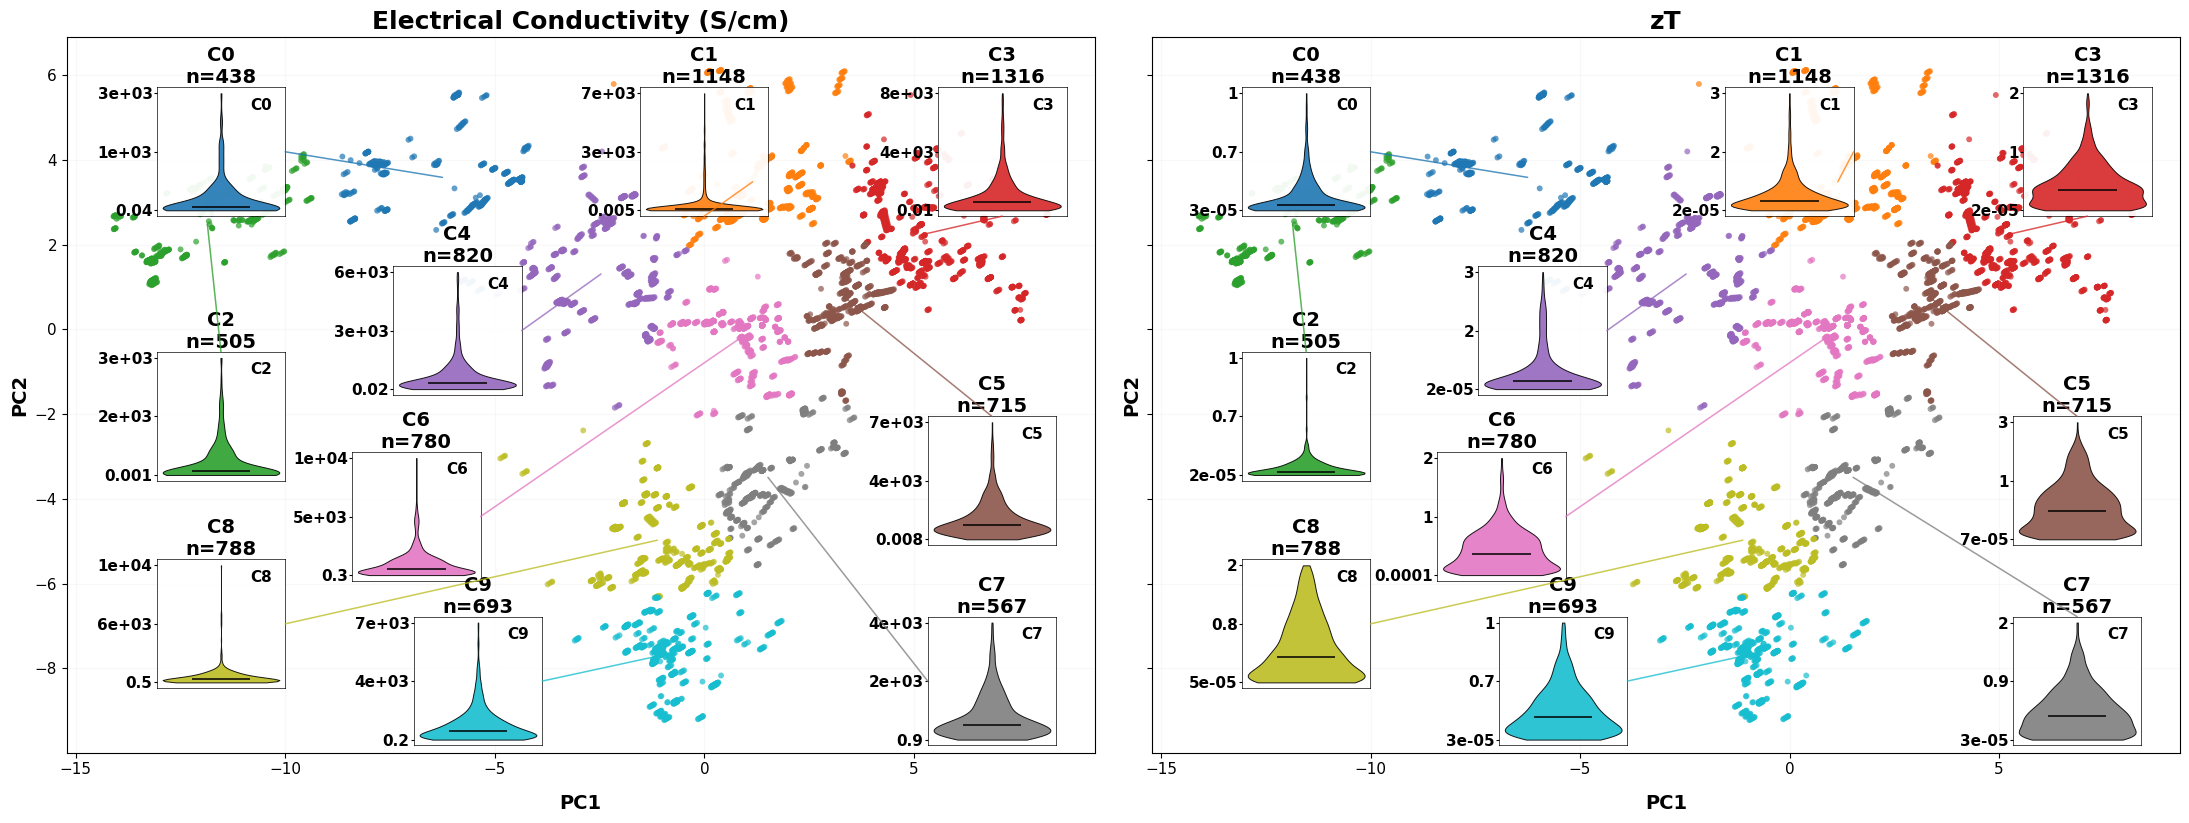

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from matplotlib.ticker import FormatStrFormatter
from matplotlib.patches import ConnectionPatch


# =============================================================================
# Path
# =============================================================================

DATA_PATH = Path(
    r"C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES"
    r"\PhD Toronto\DatasetGeneration\Better_Acqsition"
    r"\ThermoElectricNew3\WITH_MODIFICATIONS"
    r"\CLEANED_DATA_AND_FILTERED.csv"
)


# =============================================================================
# Settings
# =============================================================================

N_FEATURES = 161
N_CLUSTERS = 10
RANDOM_SEED = 42

POINT_SIZE = 18
ALPHA_POINTS = 0.7
FIGSIZE = (22, 8.5)

# Plot only Electrical Conductivity and zT, preserving the original panel style.
SELECTED_OUTCOME_INDICES = [0, 2]

OUTCOME_TITLES = [
    "Electrical Conductivity (S/cm)",
    "zT",
]

# -----------------------------------------------------------------------------
# Manual violin positions in axes fraction
# (0,0) = bottom-left of each PCA panel
# (1,1) = top-right
# -----------------------------------------------------------------------------

VIOLIN_POSITIONS = {
    0: (0.15, 0.84),
    1: (0.62, 0.84),
    2: (0.15, 0.47),
    3: (0.91, 0.84),
    4: (0.38, 0.59),
    5: (0.90, 0.38),
    6: (0.34, 0.33),
    7: (0.90, 0.10),
    8: (0.15, 0.18),
    9: (0.40, 0.10),
}

INSET_WIDTH = 0.125
INSET_HEIGHT = 0.18

VIOLIN_TICK_FONTSIZE = 11
VIOLIN_TITLE_FONTSIZE = 14
MAIN_TITLE_FONTSIZE = 18
AXIS_LABEL_FONTSIZE = 14
AXIS_TICK_FONTSIZE = 11
CLUSTER_LABEL_FONTSIZE = 12


# =============================================================================
# Load data
# =============================================================================

df_raw = pd.read_csv(DATA_PATH)

if df_raw.shape[1] == 165:
    df = df_raw.copy()

elif df_raw.shape[1] == 166:
    df = df_raw.copy()
    df = df.set_index(df.columns[0])

else:
    raise ValueError(
        f"Unexpected number of columns: {df_raw.shape[1]}. "
        "Expected 165 or 166."
    )

feature_cols = df.columns[:N_FEATURES]
outcome_cols = df.columns[-4:]
selected_outcome_cols = [outcome_cols[i] for i in SELECTED_OUTCOME_INDICES]

X = df.loc[:, feature_cols].apply(pd.to_numeric, errors="coerce")
Y = df.loc[:, outcome_cols].apply(pd.to_numeric, errors="coerce")


# =============================================================================
# Remove invalid rows
# =============================================================================

valid_mask = (
    X.notna().all(axis=1)
    & Y.notna().all(axis=1)
    & np.isfinite(X.to_numpy(dtype=float)).all(axis=1)
    & np.isfinite(Y.to_numpy(dtype=float)).all(axis=1)
)

X = X.loc[valid_mask].copy()
Y = Y.loc[valid_mask].copy()

print(f"Samples used: {len(X)}")
print("\nOutcome columns:")
for col in outcome_cols:
    print(f"  {col}")


# =============================================================================
# Standardize features
# =============================================================================

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


# =============================================================================
# PCA
# =============================================================================

pca = PCA(n_components=2, random_state=RANDOM_SEED)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_pca,
    index=X.index,
    columns=["PC1", "PC2"],
)

print(
    "\nExplained variance:"
    f"\nPC1 = {pca.explained_variance_ratio_[0]:.4f}"
    f"\nPC2 = {pca.explained_variance_ratio_[1]:.4f}"
    f"\nTotal = {pca.explained_variance_ratio_.sum():.4f}"
)


# =============================================================================
# KMeans clustering in PCA space
# =============================================================================

kmeans = KMeans(
    n_clusters=N_CLUSTERS,
    random_state=RANDOM_SEED,
    n_init=20,
)

cluster_labels = kmeans.fit_predict(pca_df[["PC1", "PC2"]])

pca_df["cluster"] = cluster_labels
Y["cluster"] = cluster_labels

centroids = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=["PC1", "PC2"],
)
centroids["cluster"] = np.arange(N_CLUSTERS)


# =============================================================================
# Reorder cluster labels for cleaner numbering
# =============================================================================

centroids_sorted = centroids.sort_values(
    by=["PC2", "PC1"],
    ascending=[False, True],
).reset_index(drop=True)

old_to_new = {
    int(old): int(new)
    for new, old in enumerate(centroids_sorted["cluster"].tolist())
}

pca_df["cluster"] = pca_df["cluster"].map(old_to_new)
Y["cluster"] = Y["cluster"].map(old_to_new)
centroids["cluster"] = centroids["cluster"].map(old_to_new)
centroids = centroids.sort_values("cluster").reset_index(drop=True)


# =============================================================================
# Robust cluster anchor points
# -----------------------------------------------------------------------------
# Instead of relying only on the raw KMeans centroids, compute the mean PCA
# position of the FINAL relabeled clusters directly from the plotted points.
# This guarantees the connector points to the actual displayed cluster.
# =============================================================================

cluster_anchors = (
    pca_df.groupby("cluster")[["PC1", "PC2"]]
    .mean()
    .reset_index()
)


# =============================================================================
# Cluster colors
# =============================================================================

cmap = plt.get_cmap("tab10")
cluster_colors = {i: cmap(i) for i in range(N_CLUSTERS)}


# =============================================================================
# Helper: choose which side of the inset should receive the connector
# =============================================================================

def choose_inset_anchor_point(cluster_ax_x, cluster_ax_y, inset_center_x, inset_center_y):
    """
    Return the point on the inset border that faces the cluster anchor.

    Coordinates are in parent-axes fraction for the cluster location and
    inset center.
    """

    dx = inset_center_x - cluster_ax_x
    dy = inset_center_y - cluster_ax_y

    if abs(dx) >= abs(dy):
        # connect to left or right side of inset
        if dx >= 0:
            # inset is to the right of the cluster -> use left edge of inset
            return (0.0, 0.5)
        else:
            # inset is to the left of the cluster -> use right edge
            return (1.0, 0.5)
    else:
        # connect to bottom or top side of inset
        if dy >= 0:
            # inset is above the cluster -> use bottom edge
            return (0.5, 0.0)
        else:
            # inset is below the cluster -> use top edge
            return (0.5, 1.0)


# =============================================================================
# Build figure
# =============================================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=FIGSIZE,
    sharex=True,
    sharey=True,
)

axes = np.atleast_1d(axes).flatten()


# =============================================================================
# Plot each outcome
# =============================================================================

for ax, outcome_col, outcome_title in zip(
    axes,
    selected_outcome_cols,
    OUTCOME_TITLES,
):

    # -------------------------------------------------------------------------
    # PCA scatter by cluster
    # -------------------------------------------------------------------------
    for cluster_id in range(N_CLUSTERS):
        mask = pca_df["cluster"] == cluster_id

        ax.scatter(
            pca_df.loc[mask, "PC1"],
            pca_df.loc[mask, "PC2"],
            s=POINT_SIZE,
            color=cluster_colors[cluster_id],
            alpha=ALPHA_POINTS,
            edgecolors="none",
            zorder=1,
        )

    # -------------------------------------------------------------------------
    # Main axis formatting
    # -------------------------------------------------------------------------
    ax.set_title(outcome_title, fontsize=MAIN_TITLE_FONTSIZE, fontweight="bold")
    ax.set_xlabel("PC1", fontsize=AXIS_LABEL_FONTSIZE, fontweight="bold", labelpad=12)
    ax.set_ylabel("PC2", fontsize=AXIS_LABEL_FONTSIZE, fontweight="bold")
    ax.tick_params(axis="both", labelsize=AXIS_TICK_FONTSIZE)
    ax.grid(alpha=0.08)

    # -------------------------------------------------------------------------
    # Add violin plots
    # -------------------------------------------------------------------------
    for cluster_id in range(N_CLUSTERS):

        cluster_mask = Y["cluster"] == cluster_id
        cluster_values = Y.loc[cluster_mask, outcome_col].dropna().to_numpy()

        if len(cluster_values) == 0:
            continue

        # ---------------------------------------------------------------------
        # Cluster anchor in actual PCA data coordinates
        # ---------------------------------------------------------------------
        cx = cluster_anchors.loc[
            cluster_anchors["cluster"] == cluster_id, "PC1"
        ].iloc[0]

        cy = cluster_anchors.loc[
            cluster_anchors["cluster"] == cluster_id, "PC2"
        ].iloc[0]

       

        # ---------------------------------------------------------------------
        # Inset axes
        # ---------------------------------------------------------------------
        x_fraction, y_fraction = VIOLIN_POSITIONS[cluster_id]

        violin_ax = ax.inset_axes(
            [
                x_fraction - INSET_WIDTH / 2,
                y_fraction - INSET_HEIGHT / 2,
                INSET_WIDTH,
                INSET_HEIGHT,
            ],
            transform=ax.transAxes,
            zorder=8,
        )

        vp = violin_ax.violinplot(
            [cluster_values],
            positions=[1],
            widths=0.85,
            showmeans=False,
            showmedians=True,
            showextrema=False,
        )

        for body in vp["bodies"]:
            body.set_facecolor(cluster_colors[cluster_id])
            body.set_edgecolor("black")
            body.set_linewidth(0.7)
            body.set_alpha(0.90)

        if "cmedians" in vp:
            vp["cmedians"].set_color("black")
            vp["cmedians"].set_linewidth(1.1)

        # ---------------------------------------------------------------------
        # Y ticks in violin
        # ---------------------------------------------------------------------
        violin_ax.set_xticks([])

        ymin_v = np.nanmin(cluster_values)
        ymax_v = np.nanmax(cluster_values)

        if np.isclose(ymin_v, ymax_v):
            ticks = [ymin_v]
        else:
            ticks = np.linspace(ymin_v, ymax_v, 3)

        violin_ax.set_yticks(ticks)
        violin_ax.yaxis.set_major_formatter(FormatStrFormatter("%.1g"))

        violin_ax.tick_params(
            axis="y",
            labelsize=VIOLIN_TICK_FONTSIZE,
            length=2,
            pad=1,
        )

        for label in violin_ax.get_yticklabels():
            label.set_fontweight("bold")

        # ---------------------------------------------------------------------
        # Inset title: show BOTH cluster number and sample size
        # ---------------------------------------------------------------------
        violin_ax.set_title(
            f"C{cluster_id}\n"
            f"n={len(cluster_values)}",
            fontsize=VIOLIN_TITLE_FONTSIZE,
            fontweight="bold",
            pad=1,
        )

        # Also write the cluster id inside the inset for extra clarity.
        violin_ax.text(
            0.90,
            0.92,
            f"C{cluster_id}",
            transform=violin_ax.transAxes,
            ha="right",
            va="top",
            fontsize=11,
            fontweight="bold",
            color="black",
            bbox=dict(
                boxstyle="round,pad=0.15",
                facecolor="white",
                edgecolor="none",
                alpha=0.60,
            ),
            zorder=10,
        )

        # ---------------------------------------------------------------------
        # Inset style
        # ---------------------------------------------------------------------
        violin_ax.set_facecolor((1, 1, 1, 0.94))
        for spine in violin_ax.spines.values():
            spine.set_linewidth(0.7)
            spine.set_alpha(0.7)

        # ---------------------------------------------------------------------
        # Connect cluster -> inset
        # Use ConnectionPatch so the line points from the actual cluster anchor
        # (data coordinates) to the border of the inset (inset axes coordinates).
        # ---------------------------------------------------------------------
        cluster_display = ax.transData.transform((cx, cy))
        cluster_axes = ax.transAxes.inverted().transform(cluster_display)
        cluster_ax_x, cluster_ax_y = cluster_axes

        inset_anchor = choose_inset_anchor_point(
            cluster_ax_x=cluster_ax_x,
            cluster_ax_y=cluster_ax_y,
            inset_center_x=x_fraction,
            inset_center_y=y_fraction,
        )

        connector = ConnectionPatch(
            xyA=inset_anchor,
            coordsA=violin_ax.transAxes,
            xyB=(cx, cy),
            coordsB=ax.transData,
            axesA=violin_ax,
            axesB=ax,
            color=cluster_colors[cluster_id],
            linewidth=1.1,
            alpha=0.78,
            zorder=5,
        )

        fig.add_artist(connector)


# =============================================================================
# Global title and layout
# =============================================================================

plt.tight_layout(
    rect=[0, 0, 1, 0.98],
    w_pad=2.0,
)

OUTPUT_PNG = DATA_PATH.parent / "PCA_Electrical_Conductivity_zT_one_row.png"
fig.savefig(
    OUTPUT_PNG,
    dpi=300,
    bbox_inches="tight",
)

print(f"\nSaved figure: {OUTPUT_PNG}")

plt.show()
plt.close(fig)